# Recommendation-Level Evidence Retrieval and Provenance Evaluation over Versioned Guidelines

**Expanded research notebook — Colab-ready**

This notebook implements a reproducible pilot-to-expanded evaluation workflow for guideline-based retrieval-augmented generation (RAG).

## Research design

- **Corpus:** AHA 2025 Adult Basic Life Support guideline and 2024 AHA–American Red Cross First Aid guideline.
- **Unit of analysis:** one manually verified recommendation statement, with its topic, applicability context and source provenance.
- **Target corpus size:** approximately 100–150 recommendation units, if the source documents contain that many eligible recommendations. Do not manufacture units to meet a target.
- **Retrieval conditions:**
  1. Text-only dense retrieval.
  2. Context-enriched dense retrieval.
  3. Applicability-aware reranking using separately represented population, situation and intervention fields.
- **Evaluation:** independent questions, hard negatives, out-of-scope questions, recommendation correctness, applicability match, ranking metrics and provenance.
- **Generation:** optional grounded answer generation with recommendation IDs and source citations.

> **Research integrity:** This notebook does not automatically certify extracted text or annotations. Every recommendation statement, COR/LOE label, applicability field, page number and version must be checked against the original PDF. The benchmark questions and their expected evidence IDs must be authored or reviewed independently of the retrieval corpus. Do not claim clinician validation, clinical safety, or clinical effectiveness unless those evaluations are actually performed.

## Expected files

Upload the two PDFs when prompted, or place them in `/content/` using these names:
- `AHA_Guidelines.pdf` — 2024 First Aid guideline
- `lifesupport.pdf` — 2025 Adult BLS guideline

The notebook saves intermediate and final artifacts under `/content/guideline_rag_research/`.

## 0. Install dependencies and configure the workspace
Run this cell once in a fresh Colab runtime.

In [1]:
!pip -q install --upgrade pymupdf pandas numpy scikit-learn chromadb google-genai matplotlib seaborn scipy tqdm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.1 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.0.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but

In [2]:


import os, re, json, time, math, hashlib, warnings, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics.pairwise import cosine_similarity
from google import genai
from google.genai import types

ROOT = Path("/content/guideline_rag_research")
PDF_DIR = ROOT / "pdfs"
DATA_DIR = ROOT / "data"
OUT_DIR = ROOT / "outputs"
CACHE_DIR = ROOT / "cache"
for p in [PDF_DIR, DATA_DIR, OUT_DIR, CACHE_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("Workspace:", ROOT)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Workspace: /content/guideline_rag_research


## 1. Upload and identify source PDFs

If the PDFs are already in `/content/`, this cell detects them. Otherwise, upload them using the Colab file picker.

In [3]:
from google.colab import files

expected = {
    "AHA_Guidelines.pdf": PDF_DIR / "AHA_Guidelines.pdf",
    "lifesupport.pdf": PDF_DIR / "lifesupport.pdf"
}

# Detect earlier copies in /content and copy them into the project folder.
for name, destination in expected.items():
    candidates = [Path("/content") / name, Path("/content/guideline_rag_data") / name]
    for candidate in candidates:
        if candidate.exists() and not destination.exists():
            import shutil
            shutil.copy2(candidate, destination)
            break

missing = [name for name, path in expected.items() if not path.exists()]
if missing:
    print("Please upload:", missing)
    uploaded = files.upload()
    for name, content in uploaded.items():
        target = PDF_DIR / name
        target.write_bytes(content)

for name, path in expected.items():
    if path.exists():
        print(name, "->", path, "| bytes:", path.stat().st_size)
    else:
        print("MISSING:", name)

AHA_Guidelines.pdf -> /content/guideline_rag_research/pdfs/AHA_Guidelines.pdf | bytes: 3871671
lifesupport.pdf -> /content/guideline_rag_research/pdfs/lifesupport.pdf | bytes: 4726676


## 2. Extract page text with layout-aware reading order

The source PDFs use multi-column layouts. This extractor uses text blocks and a configurable column boundary. It is a practical extraction aid, not a substitute for visual checking. Figures, tables, sidebars and recommendation tables may require manual inspection.

If a page is not two-column, set `TWO_COLUMN[filename] = False`. Adjust `COLUMN_SPLIT_X` after inspecting the diagnostic output.

In [4]:
import fitz  # PyMuPDF

PDF_FILES = {
    "AHA_Guidelines.pdf": PDF_DIR / "AHA_Guidelines.pdf",
    "lifesupport.pdf": PDF_DIR / "lifesupport.pdf"
}

# Based on the earlier page-layout inspection. Review for all pages/documents.
TWO_COLUMN = {
    "AHA_Guidelines.pdf": True,
    "lifesupport.pdf": True
}
COLUMN_SPLIT_X = {
    "AHA_Guidelines.pdf": 295,
    "lifesupport.pdf": 295
}
TOP_MARGIN = 40
BOTTOM_MARGIN = 740

def normalize_pdf_text(s):
    s = s.replace("\u00ad", "")
    s = re.sub(r"[ \t]+", " ", s)
    s = re.sub(r"\n{3,}", "\n\n", s)
    return s.strip()

def extract_page_layout(page, filename):
    blocks = page.get_text("blocks")
    usable = []
    for b in blocks:
        x0, y0, x1, y1, text = b[:5]
        text = text.strip()
        if not text:
            continue
        if y0 < TOP_MARGIN or y1 > BOTTOM_MARGIN:
            continue
        # Ignore narrow left-side labels/watermarks; inspect exclusions visually.
        if x0 < 35 and x1 < 40:
            continue
        usable.append((x0, y0, x1, y1, text))

    if not TWO_COLUMN.get(filename, False):
        usable.sort(key=lambda z: (z[1], z[0]))
        return "\n".join(x[4] for x in usable)

    split = COLUMN_SPLIT_X.get(filename, page.rect.width / 2)
    left = [b for b in usable if b[0] < split]
    right = [b for b in usable if b[0] >= split]
    left.sort(key=lambda z: (z[1], z[0]))
    right.sort(key=lambda z: (z[1], z[0]))
    return "\n".join([b[4] for b in left] + [b[4] for b in right])

page_records = []
for filename, path in PDF_FILES.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing PDF: {path}")
    doc = fitz.open(path)
    print(f"{filename}: {len(doc)} pages")
    for page_idx, page in enumerate(doc):
        txt = normalize_pdf_text(extract_page_layout(page, filename))
        page_records.append({
            "document": filename,
            "page": page_idx + 1,
            "text": txt,
            "page_chars": len(txt)
        })

pages_df = pd.DataFrame(page_records)
pages_path = DATA_DIR / "extracted_pages.csv"
pages_df.to_csv(pages_path, index=False)
print("Extracted pages:", len(pages_df))
print("Saved:", pages_path)
display(pages_df.groupby("document").agg(pages=("page","count"), chars=("page_chars","sum")))

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


AHA_Guidelines.pdf: 61 pages
lifesupport.pdf: 31 pages
Extracted pages: 92
Saved: /content/guideline_rag_research/data/extracted_pages.csv


,pages,chars
document,,
AHA_Guidelines.pdf,61,359827
lifesupport.pdf,31,164536


## 3. Inspect pages and discover candidate recommendation sections

Do not use a generic word search for `Recommendations` as an automatic ground-truth extractor. It can match references or unrelated headings.

Use the search cell to locate likely topic headings, then inspect the full page text and original PDF page image. Add candidate recommendations to the annotation template in the next step.

In [5]:
# Search for likely recommendation headings/keywords. This is discovery only.
patterns = [
    r"(?i)recommendations for",
    r"(?i)recommendations",
    r"(?i)COR\s+LOE",
    r"(?i)Class of Recommendation",
    r"(?i)Level of Evidence"
]

hits = []
for _, row in pages_df.iterrows():
    for pat in patterns:
        if re.search(pat, row["text"]):
            hits.append({
                "document": row["document"],
                "page": row["page"],
                "pattern": pat,
                "preview": row["text"][:500].replace("\n", " ")
            })

hits_df = pd.DataFrame(hits).drop_duplicates(["document","page","pattern"])
display(hits_df.head(100))
hits_df.to_csv(DATA_DIR / "candidate_page_index.csv", index=False)

# Inspect any page by changing these values.
INSPECT_DOCUMENT = "AHA_Guidelines.pdf"
INSPECT_PAGE = 10  # PDF page numbering starts at 1

selected = pages_df[
    (pages_df.document == INSPECT_DOCUMENT) &
    (pages_df.page == INSPECT_PAGE)
]
if len(selected):
    print(selected.iloc[0]["text"])
else:
    print("Page not found.")

,document,page,pattern,preview
0,AHA_Guidelines.pdf,1,(?i)recommendations,AHA/AMERICAN RED CROSS GUIDELINE 2024 American...
1,AHA_Guidelines.pdf,2,(?i)recommendations for,Nonstandard Abbreviations and Acronyms AHA Am...
2,AHA_Guidelines.pdf,2,(?i)recommendations,Nonstandard Abbreviations and Acronyms AHA Am...
3,AHA_Guidelines.pdf,2,(?i)Class of Recommendation,Nonstandard Abbreviations and Acronyms AHA Am...
4,AHA_Guidelines.pdf,2,(?i)Level of Evidence,Nonstandard Abbreviations and Acronyms AHA Am...
...,...,...,...,...
95,AHA_Guidelines.pdf,59,(?i)recommendations,5. A 2020 ILCOR scoping review of the manage-...
96,lifesupport.pdf,1,(?i)recommendations for,Part 7: Adult Basic Life Support: 2025 Americ...
97,lifesupport.pdf,1,(?i)recommendations,Part 7: Adult Basic Life Support: 2025 Americ...
98,lifesupport.pdf,2,(?i)recommendations,"10. During adult cardiac arrest, it is reasona..."


23. Meyran D, Cassan P, Nemeth M, Singletary E, Raitt J, Djarv T, Carlson JN.
The ability of first aid providers to recognize anaphylaxis: a scoping review. 
Cureus. 2023;15:e41547. doi: 10.7759/cureus.41547
 24. Kobayashi L, Green TC, Bowman SE, Ray MC, McKenzie MS, Rich JD. Pa-
tient simulation for assessment of layperson management of opioid over-
dose with intranasal naloxone in a recently released prisoner cohort. Simul 
Healthc. 2017;12:22–27. doi: 10.1097/SIH.0000000000000182
 25. Whittall JP, Orkin AM, Handford C, Klaiman M, Leece P, Charles M, Wright A,
Turner S, Morrison LJ, Strike C, et al. Resuscitation simulation among people 
who are likely to witness opioid overdose: experiences from the SOONER 
trial. PLoS One. 2022;17:e0270829. doi: 10.1371/journal.pone.0270829
 26. Ross EM, Redman TT, Mapp JG, Brown DJ, Tanaka K, Cooley CW,
Kharod CU, Wampler DA. Stop the Bleed: the effect of hemorrhage 
control education on laypersons’ willingness to respond during a trau-
matic medi

### Optional: render an original PDF page for visual verification

Use this for pages containing recommendation tables, COR/LOE labels, figures or complex layouts. Compare the extracted text with the original page before annotating.

In [6]:
from IPython.display import display, Image
import fitz

def show_pdf_page(filename, page_number, zoom=1.5):
    path = PDF_FILES[filename]
    doc = fitz.open(path)
    page = doc[page_number - 1]
    pix = page.get_pixmap(matrix=fitz.Matrix(zoom, zoom), alpha=False)
    image_path = OUT_DIR / f"preview_{Path(filename).stem}_p{page_number}.png"
    pix.save(image_path)
    display(Image(filename=str(image_path)))
    return image_path

# Example:
# show_pdf_page("AHA_Guidelines.pdf", 10)

## 4. Build the recommendation annotation template

Populate one row per eligible recommendation. The notebook creates a blank template and also imports the earlier 18-unit pilot annotations if that file exists.

**Annotation requirements**
- Preserve the exact recommendation wording from the PDF.
- Store recommendation number and topic/section.
- Record COR and LOE exactly as printed; retain distinctions such as `3: No Benefit` and `3: Harm`.
- Separate applicability into population, situation and intervention.
- Record source document, PDF page, printed page/section if different, guideline version/year and DOI.
- Mark each record as `verified` only after checking the PDF.
- Record annotator and verification notes.

For 100–150 units, use a target only if the source documents actually contain that many eligible recommendations.

In [7]:
annotation_columns = [
    "unit_id", "document", "guideline_title", "guideline_year", "doi",
    "pdf_page", "printed_page", "topic", "recommendation_number",
    "recommendation_text", "COR", "LOE",
    "population", "situation", "intervention",
    "annotator", "second_reviewer", "verification_status",
    "verification_notes"
]

annotation_path = DATA_DIR / "recommendation_annotations.csv"

# Import earlier pilot annotations if available.
pilot_candidates = [
    Path("/content/guideline_rag_data/outputs/recommendation_annotation_template.csv"),
    DATA_DIR / "recommendation_annotations.csv"
]
pilot = None
for p in pilot_candidates:
    if p.exists():
        pilot = pd.read_csv(p)
        print("Found prior annotation file:", p)
        break

if pilot is not None and "unit_id" in pilot.columns:
    template = pd.DataFrame()
    mapping = {
        "unit_id": "unit_id", "document": "document", "page": "pdf_page",
        "topic": "topic", "recommendation_number": "recommendation_number",
        "verified_recommendation_text": "recommendation_text",
        "COR": "COR", "LOE": "LOE", "population": "population",
        "situation": "situation", "intervention": "intervention"
    }
    for target in annotation_columns:
        source = mapping.get(target)
        template[target] = pilot[source] if source and source in pilot.columns else ""
    # Add source metadata for the two named guideline PDFs.
    template["guideline_title"] = template["document"].map({
        "AHA_Guidelines.pdf": "2024 AHA and American Red Cross Guidelines for First Aid",
        "lifesupport.pdf": "2025 AHA Guidelines: Adult Basic Life Support"
    }).fillna("")
    template["guideline_year"] = template["document"].map({
        "AHA_Guidelines.pdf": 2024, "lifesupport.pdf": 2025
    })
    template["doi"] = template["document"].map({
        "AHA_Guidelines.pdf": "10.1161/CIR.0000000000001281",
        "lifesupport.pdf": "10.1161/CIR.0000000000001369"
    }).fillna("")
    template["verification_status"] = "pending"
    template["annotator"] = ""
    template["second_reviewer"] = ""
    template["printed_page"] = ""
    template["verification_notes"] = ""
else:
    template = pd.DataFrame(columns=annotation_columns)

template = template.reindex(columns=annotation_columns)
template.to_csv(annotation_path, index=False)
print("Annotation template:", annotation_path)
print("Existing rows imported:", len(template))
display(template.head())

Annotation template: /content/guideline_rag_research/data/recommendation_annotations.csv
Existing rows imported: 0


,unit_id,document,guideline_title,guideline_year,doi,pdf_page,printed_page,topic,recommendation_number,recommendation_text,COR,LOE,population,situation,intervention,annotator,second_reviewer,verification_status,verification_notes


### Annotation quality gate

Before proceeding, complete the CSV manually. Do not use unverified extracted labels as ground truth. The next cell checks required fields and duplicate IDs; it does not decide whether annotations are factually correct.

In [8]:
annotations = pd.read_csv(annotation_path, dtype=str).fillna("")
required = [
    "unit_id", "document", "guideline_year", "pdf_page", "topic",
    "recommendation_text", "COR", "LOE", "population", "situation",
    "intervention", "verification_status"
]

missing_cols = [c for c in required if c not in annotations.columns]
if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

empty_counts = {
    c: int(annotations[c].astype(str).str.strip().eq("").sum())
    for c in required
}
print("Rows:", len(annotations))
print("Duplicate unit IDs:", annotations["unit_id"].duplicated().sum())
print("Empty required fields:", empty_counts)
print("Verification statuses:")
print(annotations["verification_status"].value_counts(dropna=False))

if len(annotations) == 0:
    print("No annotations yet. Fill the CSV and rerun this cell.")
elif annotations["unit_id"].duplicated().any():
    raise ValueError("Duplicate unit_id values found.")
elif any(v > 0 for v in empty_counts.values()):
    print("WARNING: Complete all required fields before retrieval evaluation.")
elif not annotations["verification_status"].str.lower().eq("verified").all():
    print("WARNING: Some records are not marked verified.")
else:
    print("Structural and status checks passed. Factual source verification remains a human responsibility.")

Rows: 0
Duplicate unit IDs: 0
Empty required fields: {'unit_id': 0, 'document': 0, 'guideline_year': 0, 'pdf_page': 0, 'topic': 0, 'recommendation_text': 0, 'COR': 0, 'LOE': 0, 'population': 0, 'situation': 0, 'intervention': 0, 'verification_status': 0}
Verification statuses:
Series([], Name: count, dtype: int64)
No annotations yet. Fill the CSV and rerun this cell.


## 5. Create an independent benchmark template

Do **not** generate the final evaluation questions by paraphrasing recommendation text in the same notebook. Create questions independently (for example, by a second researcher), then have a reviewer assign the expected recommendation IDs.

One query may have multiple relevant recommendation IDs. Store them as a semicolon-separated list in `relevant_unit_ids`. Add query-side applicability requirements where applicable. Use `NONE` for a question that cannot be answered from the indexed recommendation corpus.

Recommended pilot targets:
- 100–150 in-scope questions, distributed across topics and recommendation types.
- 30–50 hard-negative/context-confusion questions.
- 20–30 out-of-scope questions.
These are planning targets, not publication rules. Ensure the questions are genuinely varied and independently authored.

In [9]:
benchmark_columns = [
    "query_id", "question", "split", "question_author",
    "reviewer", "relevant_unit_ids",
    "query_population", "query_situation", "query_intervention",
    "is_answerable", "expected_document", "expected_page",
    "question_type", "review_status", "review_notes"
]

benchmark_path = DATA_DIR / "independent_benchmark.csv"
if not benchmark_path.exists():
    pd.DataFrame(columns=benchmark_columns).to_csv(benchmark_path, index=False)

benchmark = pd.read_csv(benchmark_path, dtype=str).fillna("")
print("Benchmark template:", benchmark_path)
print("Questions currently entered:", len(benchmark))
display(benchmark.head())

Benchmark template: /content/guideline_rag_research/data/independent_benchmark.csv
Questions currently entered: 0


,query_id,question,split,question_author,reviewer,relevant_unit_ids,query_population,query_situation,query_intervention,is_answerable,expected_document,expected_page,question_type,review_status,review_notes


## 6. Configure Gemini and validate model access

Use Colab Secrets (`GEMINI_API_KEY`). The notebook tests the model rather than assuming model availability. The embedding model used in the previous pilot was `gemini-embedding-001`; confirm it is available to your API key.

In [10]:
from google.colab import userdata
from google import genai

GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")

client = genai.Client(api_key=GEMINI_API_KEY)

Embedding model works. Dimensions: 3072
Generation model test failed. Change GENERATION_MODEL to an available model.
ServerError 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}


In [12]:
from pathlib import Path
import pandas as pd

annotation_path = DATA_DIR / "recommendation_annotations.csv"

print("Annotation file:", annotation_path)
print("File exists:", annotation_path.exists())

if annotation_path.exists():
    annotations = pd.read_csv(annotation_path, dtype=str).fillna("")
    print("Number of rows:", len(annotations))
    print("Columns:", annotations.columns.tolist())

    if "verification_status" in annotations.columns:
        print("\nVerification status:")
        print(annotations["verification_status"].value_counts())

    display(annotations.head(10))

Annotation file: /content/guideline_rag_research/data/recommendation_annotations.csv
File exists: True
Number of rows: 0
Columns: ['unit_id', 'document', 'guideline_title', 'guideline_year', 'doi', 'pdf_page', 'printed_page', 'topic', 'recommendation_number', 'recommendation_text', 'COR', 'LOE', 'population', 'situation', 'intervention', 'annotator', 'second_reviewer', 'verification_status', 'verification_notes']

Verification status:
Series([], Name: count, dtype: int64)


,unit_id,document,guideline_title,guideline_year,doi,pdf_page,printed_page,topic,recommendation_number,recommendation_text,COR,LOE,population,situation,intervention,annotator,second_reviewer,verification_status,verification_notes


In [13]:
from pathlib import Path

ROOT = Path("/content")

print("CSV files found in research folders:\n")

for folder in [
    ROOT / "guideline_rag_research",
    ROOT / "guideline_rag_data"
]:
    if folder.exists():
        print(f"\n--- {folder} ---")
        for file in folder.rglob("*.csv"):
            print(file, "|", file.stat().st_size, "bytes")

CSV files found in research folders:


--- /content/guideline_rag_research ---
/content/guideline_rag_research/data/recommendation_annotations.csv | 229 bytes
/content/guideline_rag_research/data/candidate_page_index.csv | 88222 bytes
/content/guideline_rag_research/data/independent_benchmark.csv | 206 bytes
/content/guideline_rag_research/data/extracted_pages.csv | 529934 bytes


In [15]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/guideline_rag_research/data")

files = [
    "extracted_pages.csv",
    "candidate_page_index.csv"
]

for filename in files:
    path = DATA_DIR / filename

    print("\n" + "=" * 60)
    print("FILE:", filename)

    df = pd.read_csv(path)

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())

    display(df.head(5))


FILE: extracted_pages.csv
Rows: 92
Columns: ['document', 'page', 'text', 'page_chars']


,document,page,text,page_chars
0,AHA_Guidelines.pdf,1,AHA/AMERICAN RED CROSS GUIDELINE\n2024 America...,3613
1,AHA_Guidelines.pdf,2,Nonstandard Abbreviations and Acronyms\nAHA \n...,4853
2,AHA_Guidelines.pdf,3,Organization of the Writing Group\nThe writing...,5411
3,AHA_Guidelines.pdf,4,Table 1. Applying COR and LOE to Clinical Str...,1378
4,AHA_Guidelines.pdf,5,Recommendation-specific supportive text clarif...,8236



FILE: candidate_page_index.csv
Rows: 163
Columns: ['document', 'page', 'pattern', 'preview']


,document,page,pattern,preview
0,AHA_Guidelines.pdf,1,(?i)recommendations,AHA/AMERICAN RED CROSS GUIDELINE 2024 American...
1,AHA_Guidelines.pdf,2,(?i)recommendations for,Nonstandard Abbreviations and Acronyms AHA Am...
2,AHA_Guidelines.pdf,2,(?i)recommendations,Nonstandard Abbreviations and Acronyms AHA Am...
3,AHA_Guidelines.pdf,2,(?i)Class of Recommendation,Nonstandard Abbreviations and Acronyms AHA Am...
4,AHA_Guidelines.pdf,2,(?i)Level of Evidence,Nonstandard Abbreviations and Acronyms AHA Am...


In [16]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/guideline_rag_research/data")

pages = pd.read_csv(DATA_DIR / "extracted_pages.csv")

print("Total extracted pages:", len(pages))
print("Columns:", pages.columns.tolist())

display(pages.head(3))

Total extracted pages: 92
Columns: ['document', 'page', 'text', 'page_chars']


,document,page,text,page_chars
0,AHA_Guidelines.pdf,1,AHA/AMERICAN RED CROSS GUIDELINE\n2024 America...,3613
1,AHA_Guidelines.pdf,2,Nonstandard Abbreviations and Acronyms\nAHA \n...,4853
2,AHA_Guidelines.pdf,3,Organization of the Writing Group\nThe writing...,5411


In [17]:
candidates = pd.read_csv(
    DATA_DIR / "candidate_page_index.csv"
)

filtered = candidates[
    candidates["pattern"].str.contains(
        "recommendations for|class of recommendation",
        case=False,
        na=False
    )
]

display(filtered.head(30))

,document,page,pattern,preview
1,AHA_Guidelines.pdf,2,(?i)recommendations for,Nonstandard Abbreviations and Acronyms AHA Am...
3,AHA_Guidelines.pdf,2,(?i)Class of Recommendation,Nonstandard Abbreviations and Acronyms AHA Am...
6,AHA_Guidelines.pdf,3,(?i)Class of Recommendation,Organization of the Writing Group The writing ...
20,AHA_Guidelines.pdf,15,(?i)recommendations for,"including ambient lighting, temperature, and m..."
65,AHA_Guidelines.pdf,44,(?i)recommendations for,"concentrated or potent chemicals, significant ..."
96,lifesupport.pdf,1,(?i)recommendations for,Part 7: Adult Basic Life Support: 2025 Americ...
99,lifesupport.pdf,3,(?i)Class of Recommendation,Table 1. Applying Class of Recommendation and...
102,lifesupport.pdf,5,(?i)Class of Recommendation,either financial or intellectual (see Appendix...
106,lifesupport.pdf,8,(?i)recommendations for,Consensus on Cardiopulmonary Resuscitation and...
109,lifesupport.pdf,9,(?i)recommendations for,for unconscious patients without cardiopulmona...


In [18]:
import pandas as pd

DATA_DIR = "/content/guideline_rag_research/data"

pages = pd.read_csv(f"{DATA_DIR}/extracted_pages.csv")

pages_to_inspect = {
    "AHA_Guidelines.pdf": [15, 44],
    "lifesupport.pdf": [8, 9, 10, 11]
}

for document, page_numbers in pages_to_inspect.items():

    print("\n" + "=" * 90)
    print("DOCUMENT:", document)

    for page_no in page_numbers:

        result = pages[
            (pages["document"] == document) &
            (pages["page"] == page_no)
        ]

        if not result.empty:
            print("\n" + "-" * 80)
            print(f"PDF PAGE: {page_no}")
            print("-" * 80)
            print(result.iloc[0]["text"][:7000])


DOCUMENT: AHA_Guidelines.pdf

--------------------------------------------------------------------------------
PDF PAGE: 15
--------------------------------------------------------------------------------
including ambient lighting, temperature, and move-
ment, can also interfere with pulse oximeter accu-
racy.7 Devices that have not been approved by the 
US Food and Drug Administration may be even 
less accurate.
REFERENCES
1. Wilkerson RG, Annous Y, Farhy E, Hurst J, Smedley AD. Home pulse ox-
imetry monitoring during the COVID-19 pandemic: an assessment of pa-
tient engagement and compliance [published online June 26, 2023]. Health 
Policy Technol. doi: 10.1016/j.hlpt.2023.100776. https://www.ncbi.nlm.nih.
gov/pmc/articles/PMC10291857/
 2. Luks AM, Swenson ER. Pulse oximetry for monitoring patients with
COVID-19 at home: potential pitfalls and practical guidance. Ann Am Thorac 
Soc. 2020;17:1040–1046. doi: 10.1513/AnnalsATS.202005-418FR
 3. Shah S, Majmudar K, Stein A, Gupta N, Sup

In [19]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/guideline_rag_research/data")
OUTPUT = DATA_DIR / "recommendation_annotations.csv"

records = []

def add_recommendation(doc, title, year, doi, page, topic,
                       number, text, cor, loe,
                       population, situation, intervention):

    records.append({
        "unit_id": f"UNIT_{len(records)+1:03d}",
        "document": doc,
        "guideline_title": title,
        "guideline_year": year,
        "doi": doi,
        "pdf_page": page,
        "printed_page": "",
        "topic": topic,
        "recommendation_number": number,
        "recommendation_text": text,
        "COR": cor,
        "LOE": loe,
        "population": population,
        "situation": situation,
        "intervention": intervention,
        "annotator": "Researcher",
        "second_reviewer": "",
        "verification_status": "pending",
        "verification_notes": "Extracted from PDF text; visual source verification required."
    })


# --------------------------------------------------
# 2024 AHA FIRST AID GUIDELINE – PAGE 15
# --------------------------------------------------

doc = "AHA_Guidelines.pdf"
title = "2024 AHA and American Red Cross Guidelines for First Aid"
doi = "10.1161/CIR.0000000000001281"

add_recommendation(
    doc, title, 2024, doi, 15,
    "Bronchodilators for Asthma With Shortness of Breath",
    1,
    "First aid providers should assist a person with asthma who is having difficulty breathing with the administration of their own prescribed bronchodilators as needed.",
    "1", "B-R",
    "Person with asthma",
    "Difficulty breathing",
    "Assist with administration of prescribed bronchodilators"
)

add_recommendation(
    doc, title, 2024, doi, 15,
    "Bronchodilators for Asthma With Shortness of Breath",
    2,
    "It is reasonable to use either an inhaler with a spacer or a nebulizer when assisting a person with asthma to use their own inhaled bronchodilator medication, in preference to using an inhaler alone.",
    "2a", "B-R",
    "Person with asthma",
    "Assistance with inhaled bronchodilator medication",
    "Use an inhaler with spacer or a nebulizer rather than an inhaler alone"
)

add_recommendation(
    doc, title, 2024, doi, 15,
    "Bronchodilators for Asthma With Shortness of Breath",
    3,
    "If a commercially available spacer is not available, it is reasonable to use an improvised spacer when assisting a person who is having an asthma attack to use their own inhaled bronchodilator medication.",
    "2a", "B-R",
    "Person experiencing an asthma attack",
    "Commercially available spacer is unavailable",
    "Use an improvised spacer"
)


# --------------------------------------------------
# 2024 AHA FIRST AID GUIDELINE – PAGE 44
# --------------------------------------------------

eye_topic = "First Aid for Chemical Exposure to the Eye"

eye_recommendations = [
    (
        1,
        "Decontamination by irrigation should be performed immediately after chemical exposure to the eyes.",
        "1", "B-NR",
        "Person with chemical eye exposure",
        "Immediately after chemical exposure",
        "Perform immediate irrigation"
    ),
    (
        2,
        "Unless otherwise recommended by local guidelines, irrigation with a copious amount of tap water for 15 minutes should be performed.",
        "1", "C-LD",
        "Person with chemical eye exposure",
        "Chemical exposure to the eyes",
        "Irrigate with copious tap water for 15 minutes"
    ),
    (
        3,
        "When providing first aid for chemical eye injury, first aid providers should avoid contaminating other individuals, areas, or the other eye with the caustic substance.",
        "1", "C-EO",
        "Person with chemical eye injury and first aid providers",
        "During first aid for chemical eye injury",
        "Avoid cross-contamination"
    ),
    (
        4,
        "Eye irrigation with normal saline, Ringer's lactate solution, or a commercial eye wash solution if immediately available is reasonable.",
        "2a", "B-NR",
        "Person with chemical eye exposure",
        "An alternative irrigation solution is immediately available",
        "Use saline, Ringer's lactate, or commercial eye wash"
    ),
    (
        5,
        "It is reasonable for individuals with ocular exposure to industrial chemicals to adhere to local guidelines or recommendations from a poison center.",
        "2a", "C-LD",
        "Individuals with industrial chemical eye exposure",
        "Ocular exposure to industrial chemicals",
        "Follow local guidelines or poison center recommendations"
    )
]

for number, text, cor, loe, pop, situation, intervention in eye_recommendations:
    add_recommendation(
        doc, title, 2024, doi, 44, eye_topic,
        number, text, cor, loe, pop, situation, intervention
    )


# --------------------------------------------------
# 2025 ADULT BASIC LIFE SUPPORT – PAGE 8
# --------------------------------------------------

doc = "lifesupport.pdf"
title = "2025 AHA Guidelines for CPR and ECC"
doi = "10.1161/CIR.0000000000001369"

add_recommendation(
    doc, title, 2025, doi, 8,
    "Recognition of Cardiac Arrest",
    1,
    "If an adult is unconscious/unresponsive, with absent or abnormal breathing (ie, only gasping), the lay rescuer should assume the person is in cardiac arrest.",
    "1", "C-LD",
    "Unresponsive adult",
    "Absent or abnormal breathing, including gasping",
    "Lay rescuer should assume cardiac arrest"
)

add_recommendation(
    doc, title, 2025, doi, 8,
    "Recognition of Cardiac Arrest",
    2,
    "If an adult is unconscious/unresponsive, with absent or abnormal breathing (ie, only gasping), the health care professional should check for a pulse for no more than 10 seconds and, if no definite pulse is felt, should assume the person is in cardiac arrest.",
    "1", "C-LD",
    "Unresponsive adult",
    "Absent or abnormal breathing",
    "Healthcare professional checks pulse for no more than 10 seconds"
)


# --------------------------------------------------
# 2025 ADULT BASIC LIFE SUPPORT – PAGE 9
# LAY RESCUER
# --------------------------------------------------

lay_topic = "Initiation of Resuscitation: Lay Rescuer"

lay_recommendations = [
    (
        1,
        "All lay rescuers should provide chest compressions for adults with presumed cardiac arrest.",
        "1", "B-NR",
        "Adults with presumed cardiac arrest",
        "Lay rescuer response",
        "Provide chest compressions"
    ),
    (
        2,
        "After identifying an adult in cardiac arrest, a lone responder should activate the emergency response system first, then immediately begin CPR, beginning with chest compressions.",
        "1", "B-NR",
        "Adult in cardiac arrest",
        "Lone responder identifies cardiac arrest",
        "Activate emergency response system, then begin CPR with chest compressions"
    ),
    (
        3,
        "For adults in cardiac arrest, a lone rescuer with a mobile phone should activate the emergency response system and immediately begin CPR, beginning with chest compressions.",
        "1", "C-LD",
        "Adults in cardiac arrest",
        "Lone rescuer has a mobile phone",
        "Activate emergency response system and begin CPR with chest compressions"
    ),
    (
        4,
        "For lay rescuers trained in performing CPR, it is reasonable to provide ventilation (breaths) in addition to chest compressions for an adult in cardiac arrest.",
        "2a", "B-R",
        "Adults in cardiac arrest",
        "Lay rescuer is trained in CPR",
        "Provide ventilation in addition to chest compressions"
    ),
    (
        5,
        "When immediately available, it is reasonable for rescuers to use PPE during CPR for adult cardiac arrest.",
        "2a", "C-LD",
        "Rescuers and adults in cardiac arrest",
        "PPE is immediately available during CPR",
        "Use personal protective equipment"
    )
]

for number, text, cor, loe, pop, situation, intervention in lay_recommendations:
    add_recommendation(
        doc, title, 2025, doi, 9, lay_topic,
        number, text, cor, loe, pop, situation, intervention
    )


# --------------------------------------------------
# 2025 ADULT BASIC LIFE SUPPORT – PAGE 9
# HEALTHCARE PROFESSIONAL
# --------------------------------------------------

hcp_recommendations = [
    (
        1,
        "During adult cardiac arrest, a lone health care professional should commence with chest compressions rather than with ventilation.",
        "1", "C-LD",
        "Adults in cardiac arrest",
        "Lone healthcare professional responding",
        "Commence with chest compressions rather than ventilation"
    ),
    (
        2,
        "It is reasonable for health care professionals to perform chest compressions and ventilation for all adult patients in cardiac arrest from either a cardiac or noncardiac cause.",
        "2a", "C-LD",
        "Adults in cardiac arrest",
        "Cardiac or noncardiac cause",
        "Perform chest compressions and ventilation"
    )
]

for number, text, cor, loe, pop, situation, intervention in hcp_recommendations:
    add_recommendation(
        doc, title, 2025, doi, 9,
        "Initiation of Resuscitation: Health Care Professional",
        number, text, cor, loe, pop, situation, intervention
    )


# --------------------------------------------------
# SAVE DATASET
# --------------------------------------------------

df = pd.DataFrame(records)

df.to_csv(OUTPUT, index=False)

print("Recommendation annotation dataset created.")
print("Total records:", len(df))
print("Verification status:", df["verification_status"].value_counts().to_dict())
print("Saved to:", OUTPUT)

display(df[[
    "unit_id", "document", "pdf_page", "topic",
    "recommendation_number", "COR", "LOE",
    "verification_status"
]])

Recommendation annotation dataset created.
Total records: 17
Verification status: {'pending': 17}
Saved to: /content/guideline_rag_research/data/recommendation_annotations.csv


,unit_id,document,pdf_page,topic,recommendation_number,COR,LOE,verification_status
0,UNIT_001,AHA_Guidelines.pdf,15,Bronchodilators for Asthma With Shortness of B...,1,1,B-R,pending
1,UNIT_002,AHA_Guidelines.pdf,15,Bronchodilators for Asthma With Shortness of B...,2,2a,B-R,pending
2,UNIT_003,AHA_Guidelines.pdf,15,Bronchodilators for Asthma With Shortness of B...,3,2a,B-R,pending
3,UNIT_004,AHA_Guidelines.pdf,44,First Aid for Chemical Exposure to the Eye,1,1,B-NR,pending
4,UNIT_005,AHA_Guidelines.pdf,44,First Aid for Chemical Exposure to the Eye,2,1,C-LD,pending
5,UNIT_006,AHA_Guidelines.pdf,44,First Aid for Chemical Exposure to the Eye,3,1,C-EO,pending
6,UNIT_007,AHA_Guidelines.pdf,44,First Aid for Chemical Exposure to the Eye,4,2a,B-NR,pending
7,UNIT_008,AHA_Guidelines.pdf,44,First Aid for Chemical Exposure to the Eye,5,2a,C-LD,pending
8,UNIT_009,lifesupport.pdf,8,Recognition of Cardiac Arrest,1,1,C-LD,pending
9,UNIT_010,lifesupport.pdf,8,Recognition of Cardiac Arrest,2,1,C-LD,pending


In [20]:
import pandas as pd

df = pd.read_csv(
    "/content/guideline_rag_research/data/recommendation_annotations.csv"
)

print("Total recommendation units:", len(df))
print("Unique IDs:", df["unit_id"].nunique())
print("Missing recommendation text:", df["recommendation_text"].isna().sum())
print("Verification status:")
print(df["verification_status"].value_counts())

Total recommendation units: 17
Unique IDs: 17
Missing recommendation text: 0
Verification status:
verification_status
pending    17
Name: count, dtype: int64


In [21]:
import pandas as pd

path = "/content/guideline_rag_research/data/recommendation_annotations.csv"

df = pd.read_csv(path)

review = df[[
    "unit_id",
    "document",
    "pdf_page",
    "topic",
    "recommendation_number",
    "recommendation_text",
    "COR",
    "LOE",
    "verification_status"
]].copy()

review["verified_text"] = ""
review["verified_COR"] = ""
review["verified_LOE"] = ""
review["review_notes"] = ""

output = "/content/guideline_rag_research/data/recommendation_review_sheet.csv"

review.to_csv(output, index=False)

print("Review sheet created:", output)
display(review)

Review sheet created: /content/guideline_rag_research/data/recommendation_review_sheet.csv


,unit_id,document,pdf_page,topic,recommendation_number,recommendation_text,COR,LOE,verification_status,verified_text,verified_COR,verified_LOE,review_notes
0,UNIT_001,AHA_Guidelines.pdf,15,Bronchodilators for Asthma With Shortness of B...,1,First aid providers should assist a person wit...,1,B-R,pending,,,,
1,UNIT_002,AHA_Guidelines.pdf,15,Bronchodilators for Asthma With Shortness of B...,2,It is reasonable to use either an inhaler with...,2a,B-R,pending,,,,
2,UNIT_003,AHA_Guidelines.pdf,15,Bronchodilators for Asthma With Shortness of B...,3,If a commercially available spacer is not avai...,2a,B-R,pending,,,,
3,UNIT_004,AHA_Guidelines.pdf,44,First Aid for Chemical Exposure to the Eye,1,Decontamination by irrigation should be perfor...,1,B-NR,pending,,,,
4,UNIT_005,AHA_Guidelines.pdf,44,First Aid for Chemical Exposure to the Eye,2,Unless otherwise recommended by local guidelin...,1,C-LD,pending,,,,
5,UNIT_006,AHA_Guidelines.pdf,44,First Aid for Chemical Exposure to the Eye,3,When providing first aid for chemical eye inju...,1,C-EO,pending,,,,
6,UNIT_007,AHA_Guidelines.pdf,44,First Aid for Chemical Exposure to the Eye,4,"Eye irrigation with normal saline, Ringer's la...",2a,B-NR,pending,,,,
7,UNIT_008,AHA_Guidelines.pdf,44,First Aid for Chemical Exposure to the Eye,5,It is reasonable for individuals with ocular e...,2a,C-LD,pending,,,,
8,UNIT_009,lifesupport.pdf,8,Recognition of Cardiac Arrest,1,"If an adult is unconscious/unresponsive, with ...",1,C-LD,pending,,,,
9,UNIT_010,lifesupport.pdf,8,Recognition of Cardiac Arrest,2,"If an adult is unconscious/unresponsive, with ...",1,C-LD,pending,,,,


In [22]:
import fitz
from pathlib import Path
from IPython.display import display, Image

PDF_DIR = Path("/content")
OUTPUT_DIR = Path("/content/guideline_rag_research/review_pages")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pages_to_review = {
    "AHA_Guidelines.pdf": [15, 44],
    "lifesupport.pdf": [8, 9]
}

for filename, pages in pages_to_review.items():
    pdf = fitz.open(PDF_DIR / filename)

    for page_num in pages:
        page = pdf[page_num - 1]

        pix = page.get_pixmap(
            matrix=fitz.Matrix(2, 2),
            alpha=False
        )

        output = OUTPUT_DIR / (
            f"{Path(filename).stem}_page_{page_num}.png"
        )

        pix.save(output)

        print(f"\n{filename} — PDF page {page_num}")
        display(Image(filename=str(output)))

    pdf.close()

Output hidden; open in https://colab.research.google.com to view.

In [24]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/guideline_rag_research/data")

# Uploaded verified review file
review_path = Path("/content/guideline_rag_research/data/recommendation_review_sheet_verified.csv")

# Main annotation dataset
main_path = DATA_DIR / "recommendation_annotations.csv"

# Load both files
review = pd.read_csv(review_path, dtype=str).fillna("")
main = pd.read_csv(main_path, dtype=str).fillna("")

# Update records using verified values
for _, row in review.iterrows():
    mask = main["unit_id"] == row["unit_id"]

    if not mask.any():
        continue

    if row["verification_status"].strip().lower() == "verified":
        main.loc[mask, "recommendation_text"] = row["verified_text"]
        main.loc[mask, "COR"] = row["verified_COR"]
        main.loc[mask, "LOE"] = row["verified_LOE"]
        main.loc[mask, "pdf_page"] = row["pdf_page"]
        main.loc[mask, "verification_status"] = "verified"
        main.loc[mask, "verification_notes"] = row["review_notes"]

main.to_csv(main_path, index=False)

print("Annotation dataset updated!")
print("\nVerification status:")
print(main["verification_status"].value_counts())

print("\nTotal records:", len(main))
print("Verified records:",
      (main["verification_status"] == "verified").sum())

Annotation dataset updated!

Verification status:
verification_status
verified    17
Name: count, dtype: int64

Total records: 17
Verified records: 17


**expand the recommendation corpus**

In [25]:
import pandas as pd
import re

DATA_DIR = "/content/guideline_rag_research/data"

pages = pd.read_csv(f"{DATA_DIR}/extracted_pages.csv")

# Find pages containing likely recommendation table headers
pattern = re.compile(
    r"COR\s+LOE\s+Recommendations|"
    r"COR\s+.*LOE.*Recommendations",
    re.IGNORECASE
)

results = []

for _, row in pages.iterrows():
    text = str(row["text"])

    if pattern.search(text):
        results.append({
            "document": row["document"],
            "pdf_page": row["page"],
            "page_chars": row["page_chars"],
            "preview": text[:500]
        })

table_pages = pd.DataFrame(results)

print("Potential recommendation-table pages:", len(table_pages))

display(table_pages)

Potential recommendation-table pages: 57


,document,pdf_page,page_chars,preview
0,AHA_Guidelines.pdf,10,5383,"23. Meyran D, Cassan P, Nemeth M, Singletary E..."
1,AHA_Guidelines.pdf,12,6819,9. Christie \nRJ. \nTherapeutic \npositioning ...
2,AHA_Guidelines.pdf,13,5930,patients who have been moved into the elevated...
3,AHA_Guidelines.pdf,14,5824,"REFERENCES\n1. Berg KM, Bray JE, Ng KC, Liley ..."
4,AHA_Guidelines.pdf,15,5390,"including ambient lighting, temperature, and m..."
5,AHA_Guidelines.pdf,16,7343,"REFERENCES\n1. Berg KM, Bray JE, Ng KC, Liley ..."
6,AHA_Guidelines.pdf,18,5271,from Get With The Guidelines–Stroke. Circ Card...
7,AHA_Guidelines.pdf,19,5972,"5. Mastrangelo M, Giordo L, Ricciardi G, De Mi..."
8,AHA_Guidelines.pdf,20,7273,Guidelines [published corrections appear in Ci...
9,AHA_Guidelines.pdf,21,7211,4. It is estimated that between 7% and 18% of\...


In [26]:
import pandas as pd
import re

DATA_DIR = "/content/guideline_rag_research/data"

pages = pd.read_csv(f"{DATA_DIR}/extracted_pages.csv")

results = []

for _, row in pages.iterrows():
    text = str(row["text"])
    lines = [x.strip() for x in text.splitlines() if x.strip()]

    # Identify section headings
    headings = [
        line for line in lines
        if re.search(r"Recommendations for", line, re.I)
    ]

    # Check whether the page contains a likely table header
    has_table_header = bool(
        re.search(r"\bCOR\b.{0,100}\bLOE\b.{0,100}Recommendations", text, re.I | re.S)
    )

    if headings and has_table_header:
        results.append({
            "document": row["document"],
            "pdf_page": row["page"],
            "section_heading": " | ".join(headings[:4]),
            "preview": text[:1000]
        })

table_candidates = pd.DataFrame(results)

print("Potential genuine recommendation-table pages:",
      len(table_candidates))

display(table_candidates)

Potential genuine recommendation-table pages: 20


,document,pdf_page,section_heading,preview
0,AHA_Guidelines.pdf,15,First Aid Recommendations for Assisting a Pers...,"including ambient lighting, temperature, and m..."
1,AHA_Guidelines.pdf,44,Recommendations for decontamination in spe-,"concentrated or potent chemicals, significant ..."
2,lifesupport.pdf,8,Recommendations for Recognition of Cardiac Arrest,Consensus on Cardiopulmonary Resuscitation and...
3,lifesupport.pdf,9,Recommendations for Initiation of Resuscitatio...,for unconscious patients without cardiopulmona...
4,lifesupport.pdf,10,Recommendations for Initiation of Resuscitatio...,"appropriately trained, they should be encourag..."
5,lifesupport.pdf,11,Recommendations for Opening the Airway in Adul...,"11. Williamson F, Heng PJ, Okubo M, Mejias AM,..."
6,lifesupport.pdf,12,Recommendations for Opening the Airway After H...,Recommendation-Specific Supportive Text\n1. Th...
7,lifesupport.pdf,13,Recommendations for Positioning and Location f...,of oral resuscitation. J Am Med Assoc. 1960;17...
8,lifesupport.pdf,15,Recommendations for Chest Compression Fraction...,respiratory failure.29–31 A 2021 systematic re...
9,lifesupport.pdf,16,Recommendations for Chest Compression Depth an...,The chest compression fraction (CCF) refers to...


In [27]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/guideline_rag_research/data")

pages = pd.read_csv(DATA_DIR / "extracted_pages.csv")

selected_pages = [11, 12, 13, 15, 16]

for page_no in selected_pages:

    row = pages[
        (pages["document"] == "lifesupport.pdf") &
        (pages["page"] == page_no)
    ]

    if not row.empty:
        print("\n" + "=" * 90)
        print(f"ADULT BLS - PDF PAGE {page_no}")
        print("=" * 90)

        print(row.iloc[0]["text"][:6500])


ADULT BLS - PDF PAGE 11
11. Williamson F, Heng PJ, Okubo M, Mejias AM, Chang WT, Douma M, Carlson
J, Raitt J, Djarv T. Does delivering chest compressions to patients who are 
not in cardiac arrest cause unintentional injury? A systematic review. Resusc 
Plus. 2024;20:100828. doi: 10.1016/j.resplu.2024.100828
 12. Kamikura T, Iwasaki H, Myojo Y, Sakagami S, Takei Y, Inaba H. Advantage
of CPR-first over call-first actions for out-of-hospital cardiac arrests in non-
elderly patients and of noncardiac aetiology. Resuscitation. 2015;96:37–45. 
doi: 10.1016/j.resuscitation.2015.06.027
 13. Idris AH, Aramendi Ecenarro E, Leroux B, Jaureguibeitia X, Yang BY,
Shaver S, Chang MP, Rea T, Kudenchuk P, Christenson J, et al. Bag-
valve-mask ventilation and survival from out-of-hospital cardiac ar-
rest: a multicenter study. Circulation. 2023;148:1847–1856. doi: 
10.1161/CIRCULATIONAHA.123.065561
 14. Kitamura T, Iwami T, Kawamura T, Nagao K, Tanaka H, Hiraide A; Implemen-
tation Working Group for A

In [28]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/guideline_rag_research/data")
path = DATA_DIR / "recommendation_annotations.csv"

df = pd.read_csv(path, dtype=str).fillna("")

new_records = [
    # PAGE 12: HEAD AND NECK TRAUMA
    (12, "Opening the Airway After Head and Neck Trauma", 1,
     "In cases of head and neck trauma, trained rescuers should open the airway of an adult by using a jaw thrust without head extension.",
     "1", "C-EO"),

    (12, "Opening the Airway After Head and Neck Trauma", 2,
     "For an adult with head and neck trauma, if the airway cannot be opened with a jaw thrust and airway adjunct insertion, trained rescuers should open the airway by using a head tilt–chin lift.",
     "1", "C-EO"),

    (12, "Opening the Airway After Head and Neck Trauma", 3,
     "In the setting of an adult with head and neck trauma, lay rescuers should not use rigid cervical devices for spinal motion restriction because their use by untrained rescuers may be harmful.",
     "3: Harm", "C-LD"),

    # PAGE 13: POSITIONING AND LOCATION FOR CPR
    (13, "Positioning and Location for CPR", 1,
     "In adult cardiac arrest, rescuers should perform chest compressions with the patient's torso at approximately the level of the rescuer's knees whenever possible.",
     "1", "B-NR"),

    (13, "Positioning and Location for CPR", 2,
     "When providing chest compressions for an adult, the rescuer should place the heel of one hand on the center (middle) of the person's chest (the lower half to lower third of the sternum) and the heel of the other hand on top of the first so that the hands are overlapped.",
     "1", "C-LD"),

    (13, "Positioning and Location for CPR", 3,
     "In adult cardiac arrest, resuscitation should generally be conducted where the person is found, as long as high-quality CPR can be administered safely and effectively.",
     "1", "C-EO"),

    (13, "Positioning and Location for CPR", 4,
     "In adult cardiac arrest, it is preferred to perform CPR on a firm surface and with the person in the supine position, when feasible and it does not delay chest compressions.",
     "2a", "C-LD"),

    (13, "Positioning and Location for CPR", 5,
     "In adult cardiac arrest, rescuers may consider placing their dominant hand on the sternum when performing chest compressions.",
     "2b", "C-LD"),

    (13, "Positioning and Location for CPR", 6,
     "For adult patients who experience cardiac arrest while in the prone position, it may be reasonable to turn the patient supine before initiating chest compressions. If the patient cannot be safely turned supine, rescuers may consider performing CPR in the prone position.",
     "2b", "C-LD"),

    # PAGE 15: CHEST COMPRESSION FRACTION AND PAUSES
    (15, "Chest Compression Fraction and Pauses", 1,
     "In adult cardiac arrest, preshock and postshock pauses in chest compressions should be as short as possible.",
     "1", "C-LD"),

    (15, "Chest Compression Fraction and Pauses", 2,
     "During rhythm checks for adult cardiac arrest, the health care professional should minimize the time taken to check for a pulse (no more than 10 s), and if the rescuer does not definitely feel a pulse, chest compressions should be restarted immediately.",
     "1", "C-LD"),

    (15, "Chest Compression Fraction and Pauses", 3,
     "In adults with cardiac arrest, it is reasonable to immediately resume chest compressions after shock administration rather than pause CPR to perform a postshock rhythm check.",
     "2a", "B-R"),

    (15, "Chest Compression Fraction and Pauses", 4,
     "When 2 or more rescuers are available during an adult cardiac arrest, it is reasonable to switch chest compressors approximately every 2 min (or after about 5 cycles of compressions and ventilation at a ratio of 30:2).",
     "2a", "B-R"),

    (15, "Chest Compression Fraction and Pauses", 5,
     "For adults in cardiac arrest receiving CPR without an advanced airway, it is reasonable to pause compressions to deliver 2 breaths, each given over 1 s.",
     "2a", "C-LD"),

    (15, "Chest Compression Fraction and Pauses", 6,
     "During adult cardiac arrest, it may be reasonable to perform CPR with a chest compression fraction of at least 60%.",
     "2b", "C-LD"),

    (15, "Chest Compression Fraction and Pauses", 7,
     "Outside of the advanced life support environment, where invasive monitoring is available, there are insufficient data about the value of a pulse check while performing CPR for adult cardiac arrest.",
     "2b", "C-LD"),

    # PAGE 16: CHEST COMPRESSION DEPTH AND RATE
    (16, "Chest Compression Depth and Rate in Adult Cardiac Arrest", 1,
     "During manual CPR, rescuers should perform chest compressions to a depth of at least 2 inches, or 5 cm, for an average adult while avoiding excessive chest compression depths (>2.4 inches, or 6 cm).",
     "1", "B-NR"),

    (16, "Chest Compression Depth and Rate in Adult Cardiac Arrest", 2,
     "During adult cardiac arrest, it is reasonable to use audiovisual feedback devices for real-time optimization of CPR performance.",
     "2a", "B-R"),

    (16, "Chest Compression Depth and Rate in Adult Cardiac Arrest", 3,
     "For adults in cardiac arrest, it is reasonable for rescuers to perform chest compressions at a rate of 100 to 120/min.",
     "2a", "B-NR"),

    (16, "Chest Compression Depth and Rate in Adult Cardiac Arrest", 4,
     "It can be beneficial for rescuers to allow complete chest wall recoil for adults in cardiac arrest, such as by not leaning on the chest between compressions.",
     "2a", "C-LD"),

    (16, "Chest Compression Depth and Rate in Adult Cardiac Arrest", 5,
     "During adult cardiac arrest, it may be reasonable to perform chest compressions so that chest compression and recoil/relaxation times are approximately equal.",
     "2b", "C-EO"),
]

existing_ids = set(df["unit_id"])
new_rows = []

for page, topic, number, text, cor, loe in new_records:
    uid = f"UNIT_{len(existing_ids) + len(new_rows) + 1:03d}"

    new_rows.append({
        "unit_id": uid,
        "document": "lifesupport.pdf",
        "guideline_title": "2025 AHA Guidelines for CPR and ECC",
        "guideline_year": "2025",
        "doi": "10.1161/CIR.0000000000001369",
        "pdf_page": str(page),
        "printed_page": "",
        "topic": topic,
        "recommendation_number": str(number),
        "recommendation_text": text,
        "COR": cor,
        "LOE": loe,
        "population": "Adult cardiac arrest or adult with head and neck trauma",
        "situation": "",
        "intervention": "",
        "annotator": "Researcher",
        "second_reviewer": "",
        "verification_status": "pending",
        "verification_notes": "Candidate extracted from guideline text; visual verification required."
    })

new_df = pd.DataFrame(new_rows)

df = pd.concat([df, new_df], ignore_index=True)
df.to_csv(path, index=False)

print("New records added:", len(new_df))
print("Total recommendation records:", len(df))
print("\nVerification status:")
print(df["verification_status"].value_counts())

New records added: 21
Total recommendation records: 38

Verification status:
verification_status
pending     21
verified    17
Name: count, dtype: int64


In [29]:
import pandas as pd

path = "/content/guideline_rag_research/data/recommendation_annotations.csv"
df = pd.read_csv(path)

pending = df[df["verification_status"] == "pending"].copy()

print("Pending records:", len(pending))
print("\nRecords by PDF page:")
print(pending.groupby(["document", "pdf_page"]).size())

display(
    pending[
        [
            "unit_id",
            "document",
            "pdf_page",
            "topic",
            "recommendation_text",
            "COR",
            "LOE",
            "population",
            "situation",
            "intervention",
            "verification_status"
        ]
    ].sort_values(["document", "pdf_page", "unit_id"])
)

Pending records: 21

Records by PDF page:
document         pdf_page
lifesupport.pdf  12          3
                 13          6
                 15          7
                 16          5
dtype: int64


,unit_id,document,pdf_page,topic,recommendation_text,COR,LOE,population,situation,intervention,verification_status
17,UNIT_018,lifesupport.pdf,12,Opening the Airway After Head and Neck Trauma,"In cases of head and neck trauma, trained resc...",1,C-EO,Adult cardiac arrest or adult with head and ne...,NaN,NaN,pending
18,UNIT_019,lifesupport.pdf,12,Opening the Airway After Head and Neck Trauma,"For an adult with head and neck trauma, if the...",1,C-EO,Adult cardiac arrest or adult with head and ne...,NaN,NaN,pending
19,UNIT_020,lifesupport.pdf,12,Opening the Airway After Head and Neck Trauma,In the setting of an adult with head and neck ...,3: Harm,C-LD,Adult cardiac arrest or adult with head and ne...,NaN,NaN,pending
20,UNIT_021,lifesupport.pdf,13,Positioning and Location for CPR,"In adult cardiac arrest, rescuers should perfo...",1,B-NR,Adult cardiac arrest or adult with head and ne...,NaN,NaN,pending
21,UNIT_022,lifesupport.pdf,13,Positioning and Location for CPR,When providing chest compressions for an adult...,1,C-LD,Adult cardiac arrest or adult with head and ne...,NaN,NaN,pending
22,UNIT_023,lifesupport.pdf,13,Positioning and Location for CPR,"In adult cardiac arrest, resuscitation should ...",1,C-EO,Adult cardiac arrest or adult with head and ne...,NaN,NaN,pending
23,UNIT_024,lifesupport.pdf,13,Positioning and Location for CPR,"In adult cardiac arrest, it is preferred to pe...",2a,C-LD,Adult cardiac arrest or adult with head and ne...,NaN,NaN,pending
24,UNIT_025,lifesupport.pdf,13,Positioning and Location for CPR,"In adult cardiac arrest, rescuers may consider...",2b,C-LD,Adult cardiac arrest or adult with head and ne...,NaN,NaN,pending
25,UNIT_026,lifesupport.pdf,13,Positioning and Location for CPR,For adult patients who experience cardiac arre...,2b,C-LD,Adult cardiac arrest or adult with head and ne...,NaN,NaN,pending
26,UNIT_027,lifesupport.pdf,15,Chest Compression Fraction and Pauses,"In adult cardiac arrest, preshock and postshoc...",1,C-LD,Adult cardiac arrest or adult with head and ne...,NaN,NaN,pending


In [30]:
import pandas as pd

path = "/content/guideline_rag_research/data/recommendation_annotations.csv"
df = pd.read_csv(path)

annotations = {
    "UNIT_018": (
        "Adults with head and neck trauma",
        "Airway management after head and neck trauma",
        "Open airway using jaw thrust without head extension"
    ),
    "UNIT_019": (
        "Adults with head and neck trauma",
        "Airway cannot be opened using jaw thrust and airway adjunct insertion",
        "Open airway using head tilt–chin lift"
    ),
    "UNIT_020": (
        "Adults with head and neck trauma",
        "Airway management by lay rescuers",
        "Avoid rigid cervical devices for spinal motion restriction"
    ),
    "UNIT_021": (
        "Adults experiencing cardiac arrest",
        "Rescuer positioning during chest compressions",
        "Position the patient's torso approximately at the rescuer's knee level"
    ),
    "UNIT_022": (
        "Adults experiencing cardiac arrest",
        "Hand placement during chest compressions",
        "Place overlapping hands on the center of the chest"
    ),
    "UNIT_023": (
        "Adults experiencing cardiac arrest",
        "Selecting the location for resuscitation",
        "Perform CPR where the person is found when safe and effective"
    ),
    "UNIT_024": (
        "Adults experiencing cardiac arrest",
        "Surface and body positioning for CPR",
        "Use a firm surface and supine position when feasible"
    ),
    "UNIT_025": (
        "Adults experiencing cardiac arrest",
        "Hand positioning during chest compressions",
        "Consider placing the dominant hand on the sternum"
    ),
    "UNIT_026": (
        "Adults experiencing cardiac arrest",
        "Cardiac arrest occurring in the prone position",
        "Turn supine before compressions when feasible; consider prone CPR if turning is unsafe"
    ),
    "UNIT_027": (
        "Adults experiencing cardiac arrest",
        "Pauses before and after defibrillation",
        "Minimize preshock and postshock compression pauses"
    ),
    "UNIT_028": (
        "Adults experiencing cardiac arrest",
        "Pulse assessment during rhythm checks",
        "Limit pulse checks to 10 seconds and restart compressions if no definite pulse is felt"
    ),
    "UNIT_029": (
        "Adults experiencing cardiac arrest",
        "CPR immediately following defibrillation",
        "Resume chest compressions immediately after shock administration"
    ),
    "UNIT_030": (
        "Adults experiencing cardiac arrest",
        "Multiple rescuers providing CPR",
        "Rotate chest compressors approximately every two minutes"
    ),
    "UNIT_031": (
        "Adults experiencing cardiac arrest",
        "CPR without an advanced airway",
        "Pause compressions to deliver two breaths, each over one second"
    ),
    "UNIT_032": (
        "Adults experiencing cardiac arrest",
        "Chest compression fraction during CPR",
        "Consider maintaining a chest compression fraction of at least 60%"
    ),
    "UNIT_033": (
        "Adults experiencing cardiac arrest",
        "Pulse checks during CPR outside advanced life support",
        "Evidence is insufficient to establish the value of pulse checks"
    ),
    "UNIT_034": (
        "Adults experiencing cardiac arrest",
        "Chest compression depth during manual CPR",
        "Compress at least 2 inches while avoiding depths greater than 2.4 inches"
    ),
    "UNIT_035": (
        "Adults experiencing cardiac arrest",
        "Real-time CPR performance optimization",
        "Use audiovisual feedback devices"
    ),
    "UNIT_036": (
        "Adults experiencing cardiac arrest",
        "Chest compression rate during CPR",
        "Perform compressions at 100–120 per minute"
    ),
    "UNIT_037": (
        "Adults experiencing cardiac arrest",
        "Chest wall recoil during CPR",
        "Allow complete chest wall recoil and avoid leaning"
    ),
    "UNIT_038": (
        "Adults experiencing cardiac arrest",
        "Compression and recoil timing",
        "Consider approximately equal compression and recoil times"
    )
}

for unit_id, values in annotations.items():
    mask = df["unit_id"] == unit_id
    if mask.sum() != 1:
        raise ValueError(f"Expected exactly one record for {unit_id}")

    df.loc[mask, ["population", "situation", "intervention"]] = values

df.to_csv(path, index=False)

print("Context annotations updated.")
print("Total records:", len(df))
print("Verified:", (df["verification_status"] == "verified").sum())
print("Pending:", (df["verification_status"] == "pending").sum())

Context annotations updated.
Total records: 38
Verified: 17
Pending: 21


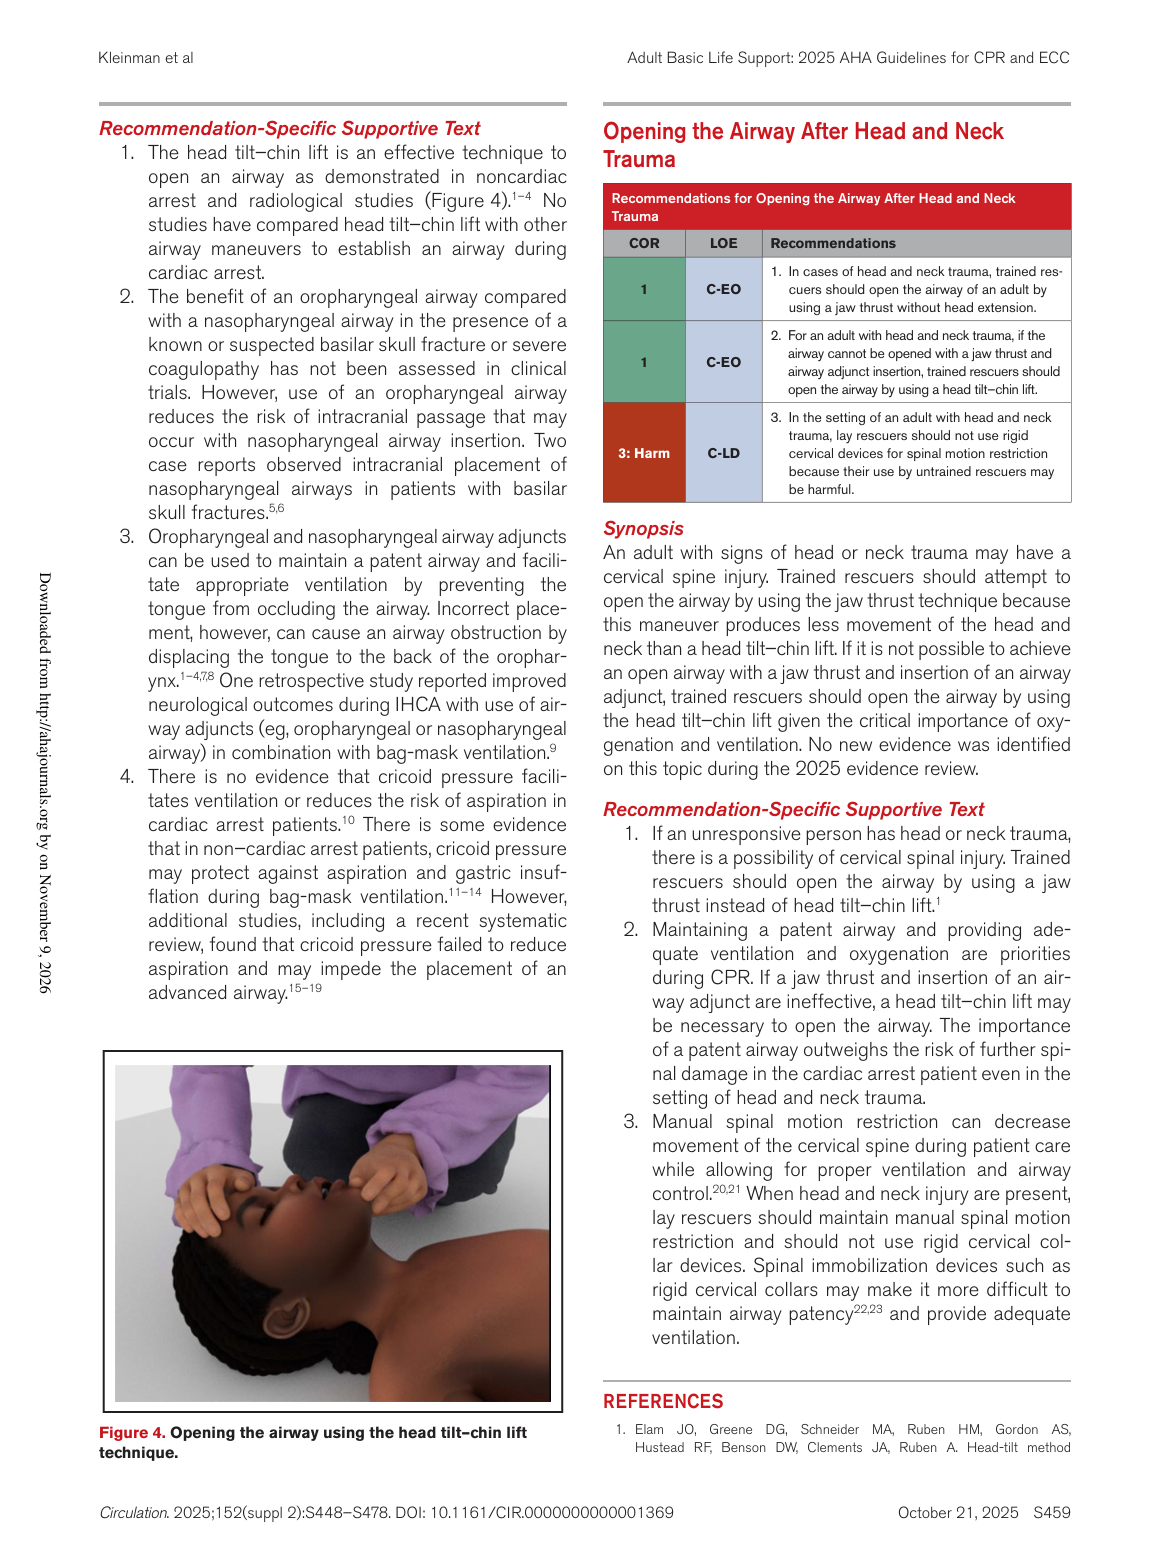

Page 12 rendered successfully.


In [32]:
import fitz
from IPython.display import display, Image

pdf_path = "/content/lifesupport.pdf"

# Open original PDF
pdf = fitz.open(pdf_path)

# PDF page 12 (Python uses zero-based indexing)
page = pdf[11]

# Render at high resolution
pix = page.get_pixmap(matrix=fitz.Matrix(2, 2))

# Save image
image_path = "/content/page12.png"
pix.save(image_path)

# Display image
display(Image(filename=image_path))

print("Page 12 rendered successfully.")

In [33]:
import pandas as pd

path = "/content/guideline_rag_research/data/recommendation_annotations.csv"
df = pd.read_csv(path)

updates = {
    "UNIT_018": {
        "population": "Trained rescuers assisting adults with head and neck trauma",
        "verification_status": "verified",
        "verification_notes": "Visually verified against 2025 AHA Adult BLS guideline, PDF page 12, printed page S459. Recommendation text, COR 1 and LOE C-EO confirmed."
    },
    "UNIT_019": {
        "population": "Trained rescuers assisting adults with head and neck trauma",
        "verification_status": "verified",
        "verification_notes": "Visually verified against 2025 AHA Adult BLS guideline, PDF page 12, printed page S459. Recommendation text, COR 1 and LOE C-EO confirmed."
    },
    "UNIT_020": {
        "population": "Lay rescuers assisting adults with head and neck trauma",
        "verification_status": "verified",
        "verification_notes": "Visually verified against 2025 AHA Adult BLS guideline, PDF page 12, printed page S459. Recommendation text, COR 3: Harm and LOE C-LD confirmed."
    }
}

for unit_id, values in updates.items():
    mask = df["unit_id"] == unit_id
    for column, value in values.items():
        df.loc[mask, column] = value

df.to_csv(path, index=False)

print("Page 12 verification completed.")
print(df["verification_status"].value_counts())

Page 12 verification completed.
verification_status
verified    20
pending     18
Name: count, dtype: int64


## PDF page 11

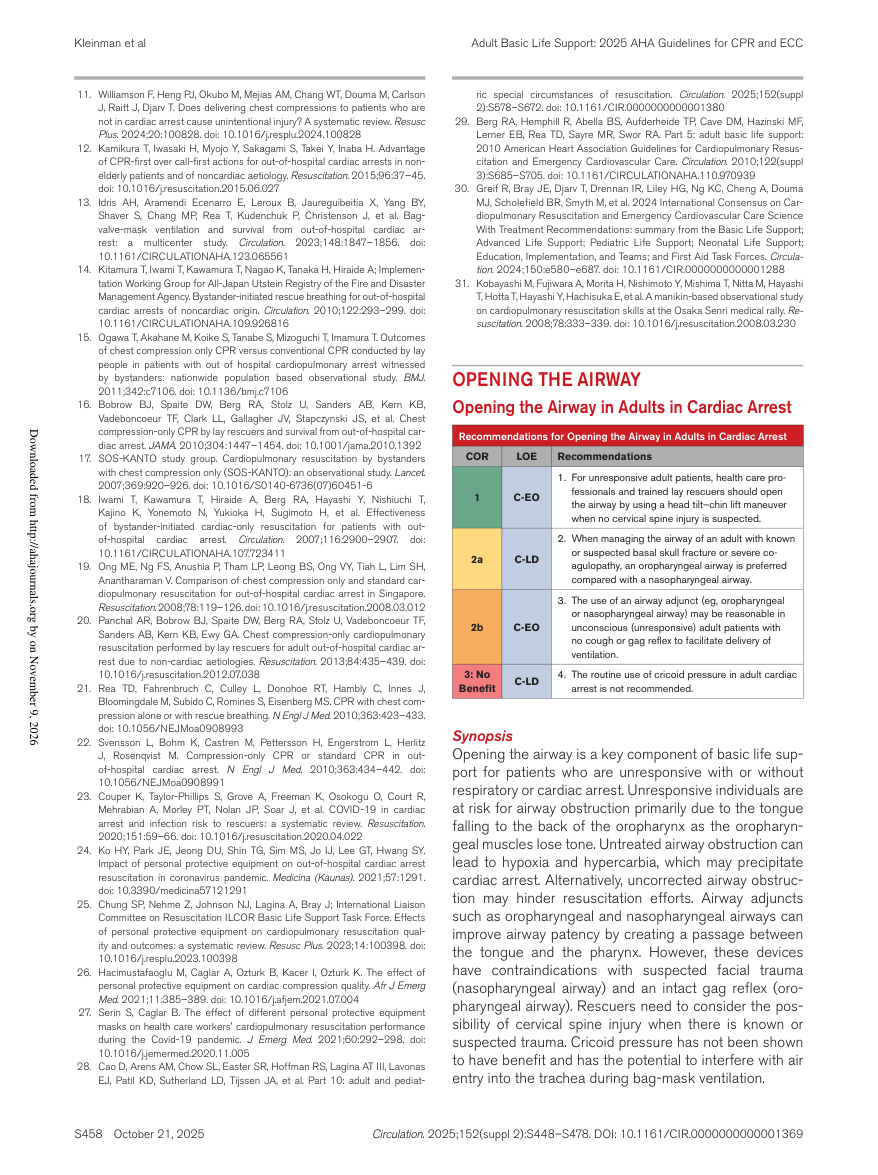

## PDF page 13

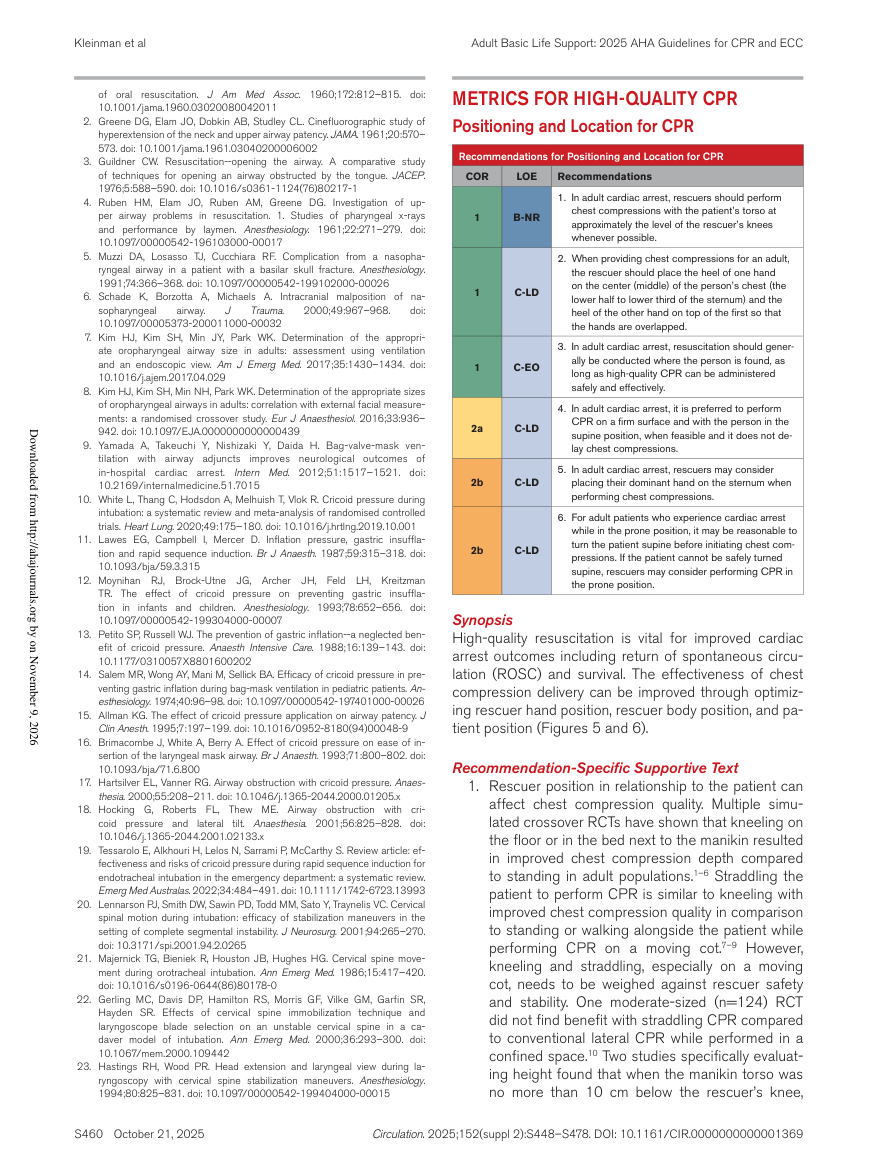

## PDF page 15

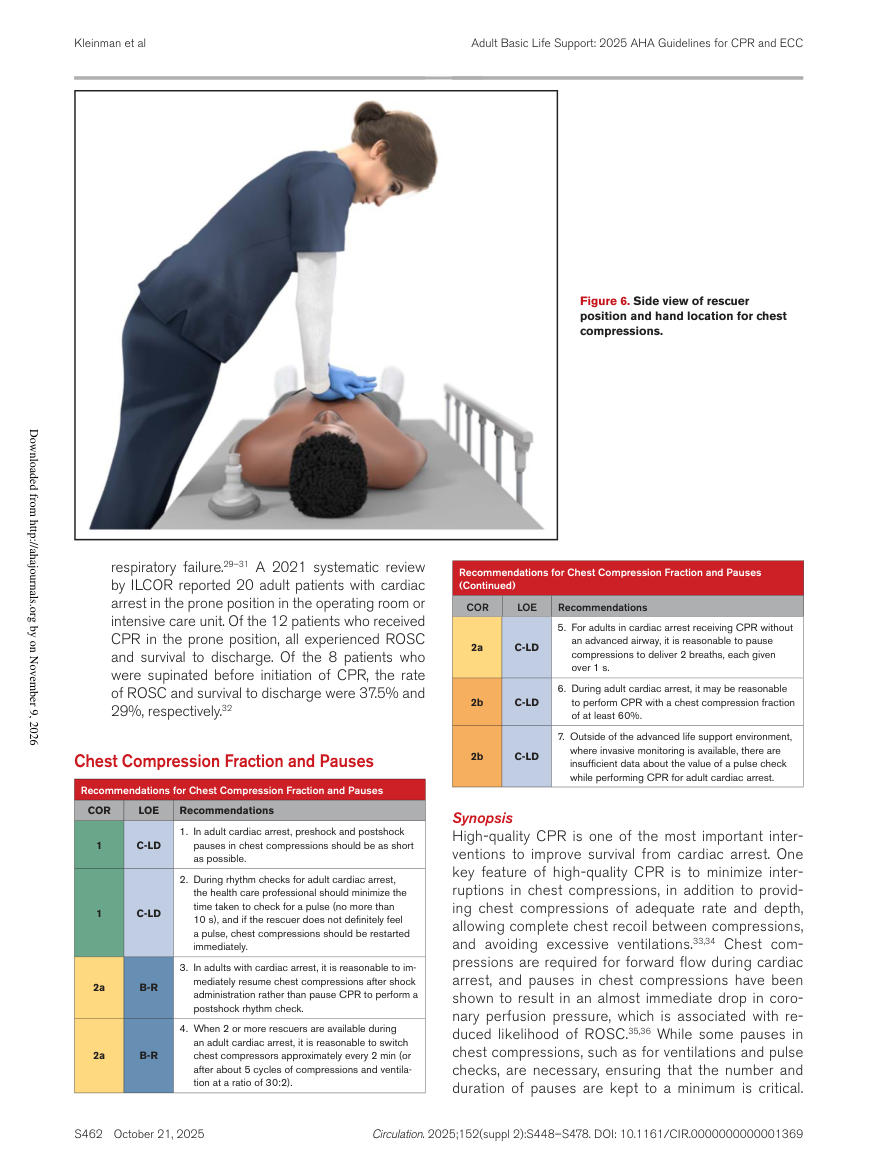

## PDF page 16

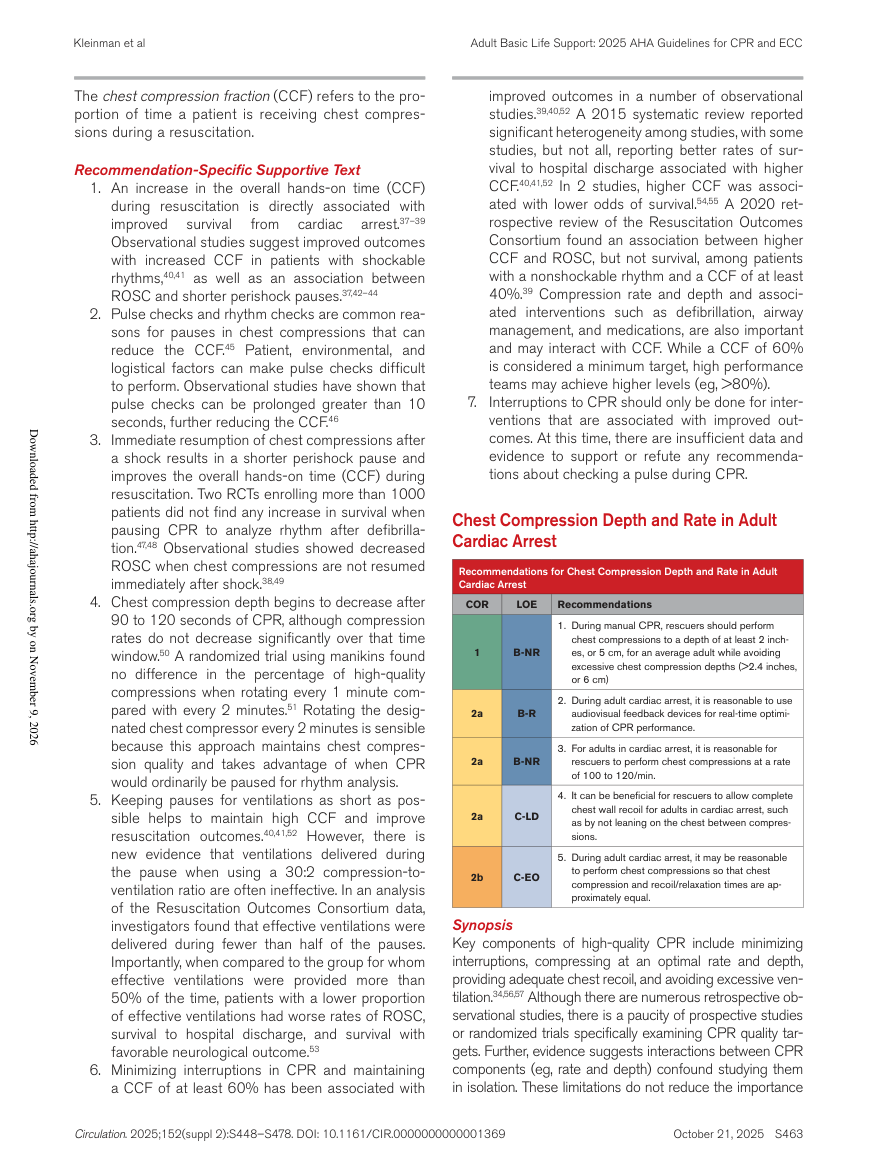

In [34]:
import fitz
from IPython.display import display, Markdown, Image

pdf = fitz.open("/content/lifesupport.pdf")

# Pages containing our pending recommendation records
pages = [11, 13, 15, 16]  # PDF page numbers

for page_num in pages:
    page = pdf[page_num - 1]

    pix = page.get_pixmap(matrix=fitz.Matrix(1.5, 1.5))
    image_path = f"/content/guideline_page_{page_num}.png"
    pix.save(image_path)

    display(Markdown(f"## PDF page {page_num}"))
    display(Image(filename=image_path))

In [35]:
import pandas as pd

path = "/content/guideline_rag_research/data/recommendation_annotations.csv"
df = pd.read_csv(path)

# 1. Verify the 18 existing recommendations on pages 13, 15 and 16
unit_ids = [f"UNIT_{i:03d}" for i in range(21, 39)]

for unit_id in unit_ids:
    mask = df["unit_id"] == unit_id
    if mask.sum() != 1:
        raise ValueError(f"Expected exactly one record for {unit_id}")

    df.loc[mask, "verification_status"] = "verified"
    df.loc[mask, "verification_notes"] = (
        "Visually verified against the original 2025 AHA Adult BLS guideline. "
        "Recommendation wording, COR and LOE confirmed. "
        "PDF pages 13, 15 or 16; printed pages S460, S462 or S463."
    )

# 2. Four additional recommendations from PDF page 11
new_records = [
    {
        "pdf_page": 11,
        "topic": "Opening the Airway in Adults in Cardiac Arrest",
        "recommendation_number": "1",
        "recommendation_text": (
            "For unresponsive adult patients, health care professionals and trained "
            "lay rescuers should open the airway by using a head tilt–chin lift maneuver "
            "when no cervical spine injury is suspected."
        ),
        "COR": "1",
        "LOE": "C-EO",
        "population": "Unresponsive adults without suspected cervical spine injury",
        "situation": "Opening the airway during adult cardiac arrest",
        "intervention": "Use a head tilt–chin lift maneuver"
    },
    {
        "pdf_page": 11,
        "topic": "Opening the Airway in Adults in Cardiac Arrest",
        "recommendation_number": "2",
        "recommendation_text": (
            "When managing the airway of an adult with known or suspected basal skull "
            "fracture or severe coagulopathy, an oropharyngeal airway is preferred "
            "compared with a nasopharyngeal airway."
        ),
        "COR": "2a",
        "LOE": "C-LD",
        "population": "Adults with known or suspected basal skull fracture or severe coagulopathy",
        "situation": "Airway adjunct selection",
        "intervention": "Prefer an oropharyngeal airway over a nasopharyngeal airway"
    },
    {
        "pdf_page": 11,
        "topic": "Opening the Airway in Adults in Cardiac Arrest",
        "recommendation_number": "3",
        "recommendation_text": (
            "The use of an airway adjunct (eg, oropharyngeal or nasopharyngeal airway) "
            "may be reasonable in unconscious adult patients with no cough or gag reflex "
            "to facilitate delivery of ventilation."
        ),
        "COR": "2b",
        "LOE": "C-EO",
        "population": "Unconscious adults without cough or gag reflex",
        "situation": "Facilitating ventilation",
        "intervention": "Consider use of an oropharyngeal or nasopharyngeal airway adjunct"
    },
    {
        "pdf_page": 11,
        "topic": "Opening the Airway in Adults in Cardiac Arrest",
        "recommendation_number": "4",
        "recommendation_text": (
            "The routine use of cricoid pressure in adult cardiac arrest "
            "is not recommended."
        ),
        "COR": "3: No Benefit",
        "LOE": "C-LD",
        "population": "Adults experiencing cardiac arrest",
        "situation": "Airway management during cardiac arrest",
        "intervention": "Do not routinely use cricoid pressure"
    }
]

# Check for existing page 11 recommendations to prevent duplicates
existing_page11 = df[
    (df["document"] == "lifesupport.pdf") &
    (df["pdf_page"] == 11)
]["recommendation_number"].astype(str).tolist()

rows_to_add = []

for rec in new_records:
    if str(rec["recommendation_number"]) in existing_page11:
        continue

    next_id = max(
        [int(x.split("_")[1]) for x in df["unit_id"].dropna()
         if str(x).startswith("UNIT_")],
        default=0
    ) + 1

    row = {col: None for col in df.columns}
    row.update({
        "unit_id": f"UNIT_{next_id:03d}",
        "document": "lifesupport.pdf",
        "guideline_title": "2025 AHA Guidelines for CPR and ECC",
        "guideline_year": 2025,
        "doi": "10.1161/CIR.0000000000001369",
        "pdf_page": rec["pdf_page"],
        "printed_page": "S458",
        "topic": rec["topic"],
        "recommendation_number": rec["recommendation_number"],
        "recommendation_text": rec["recommendation_text"],
        "COR": rec["COR"],
        "LOE": rec["LOE"],
        "population": rec["population"],
        "situation": rec["situation"],
        "intervention": rec["intervention"],
        "annotator": "Researcher",
        "verification_status": "verified",
        "verification_notes": (
            "Visually verified against the original 2025 AHA Adult BLS guideline, "
            "PDF page 11, printed page S458. Recommendation wording, COR and LOE "
            "checked against the source table."
        )
    })
    rows_to_add.append(row)
    existing_page11.append(str(rec["recommendation_number"]))

if rows_to_add:
    df = pd.concat([df, pd.DataFrame(rows_to_add)], ignore_index=True)

df.to_csv(path, index=False)

print("Dataset update completed.")
print("New page 11 records added:", len(rows_to_add))
print("Total records:", len(df))
print("\nVerification status:")
print(df["verification_status"].value_counts(dropna=False))

Dataset update completed.
New page 11 records added: 4
Total records: 42

Verification status:
verification_status
verified    42
Name: count, dtype: int64


In [36]:
import pandas as pd

path = "/content/guideline_rag_research/data/recommendation_annotations.csv"
df = pd.read_csv(path)

print("DATASET QUALITY AUDIT")
print("=" * 50)

print("Total records:", len(df))
print("Unique IDs:", df["unit_id"].nunique())
print("Duplicate IDs:", df["unit_id"].duplicated().sum())

print("\nVerification status:")
print(df["verification_status"].value_counts(dropna=False))

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate recommendation texts:",
      df["recommendation_text"].duplicated().sum())

print("\nRecords by document:")
print(df.groupby("document").size())

print("\nRecords by PDF page:")
print(df.groupby(["document", "pdf_page"]).size())

required = [
    "unit_id", "document", "pdf_page",
    "recommendation_text", "COR", "LOE",
    "population", "situation", "intervention"
]

print("\nMissing required fields:")
print(df[required].isnull().sum())

print("\nAudit complete.")

DATASET QUALITY AUDIT
Total records: 42
Unique IDs: 39
Duplicate IDs: 3

Verification status:
verification_status
verified    42
Name: count, dtype: int64

Missing values:
unit_id                   0
document                  0
guideline_title           0
guideline_year            0
doi                       0
pdf_page                  0
printed_page             38
topic                     0
recommendation_number     0
recommendation_text       0
COR                       0
LOE                       0
population                0
situation                 0
intervention              0
annotator                 0
second_reviewer          42
verification_status       0
verification_notes        0
dtype: int64

Duplicate recommendation texts: 0

Records by document:
document
AHA_Guidelines.pdf     8
lifesupport.pdf       34
dtype: int64

Records by PDF page:
document            pdf_page
AHA_Guidelines.pdf  15          3
                    44          5
lifesupport.pdf     8           2
 

In [37]:
import pandas as pd

path = "/content/guideline_rag_research/data/recommendation_annotations.csv"
df = pd.read_csv(path)

page_mapping = {
    8: "S455",
    9: "S456",
    10: "S457",
    11: "S458",
    12: "S459",
    13: "S460",
    15: "S462",
    16: "S463"
}

mask = df["document"] == "lifesupport.pdf"

df.loc[mask, "printed_page"] = (
    df.loc[mask, "pdf_page"].map(page_mapping)
)

df.to_csv(path, index=False)

print("Printed page references updated.")
print("\nMissing printed pages by document:")
print(df.groupby("document")["printed_page"].apply(
    lambda x: x.isna().sum()
))

Printed page references updated.

Missing printed pages by document:
document
AHA_Guidelines.pdf    8
lifesupport.pdf       0
Name: printed_page, dtype: int64


PDF page 15 footer:


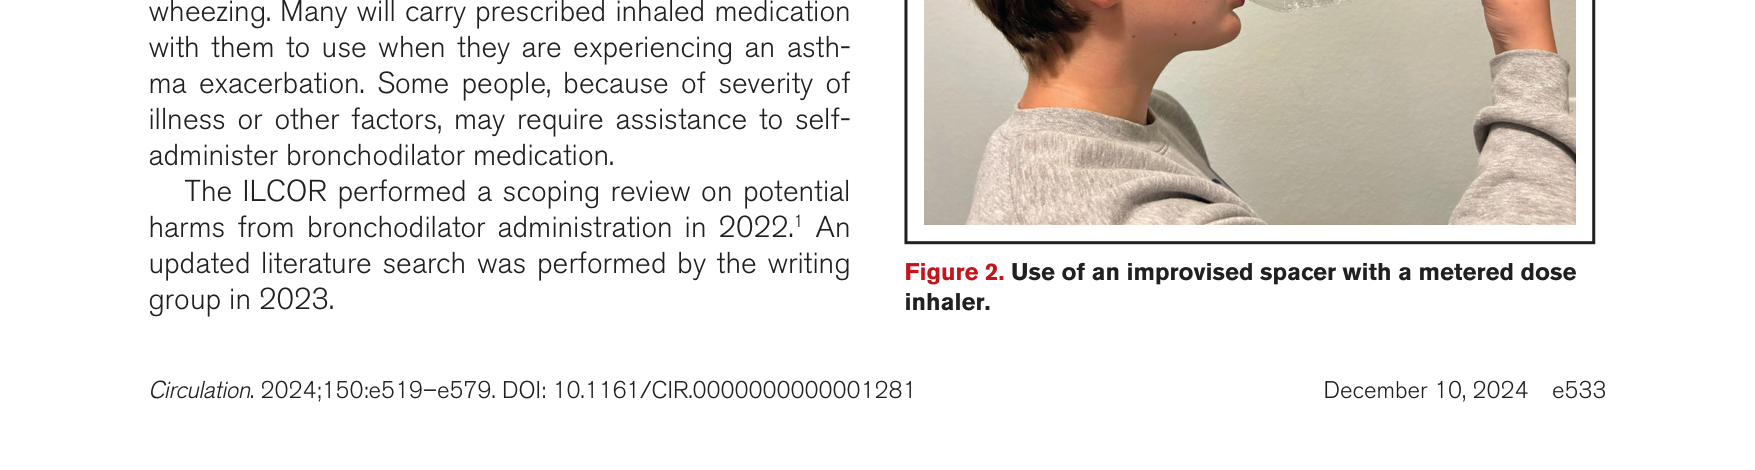

PDF page 44 footer:


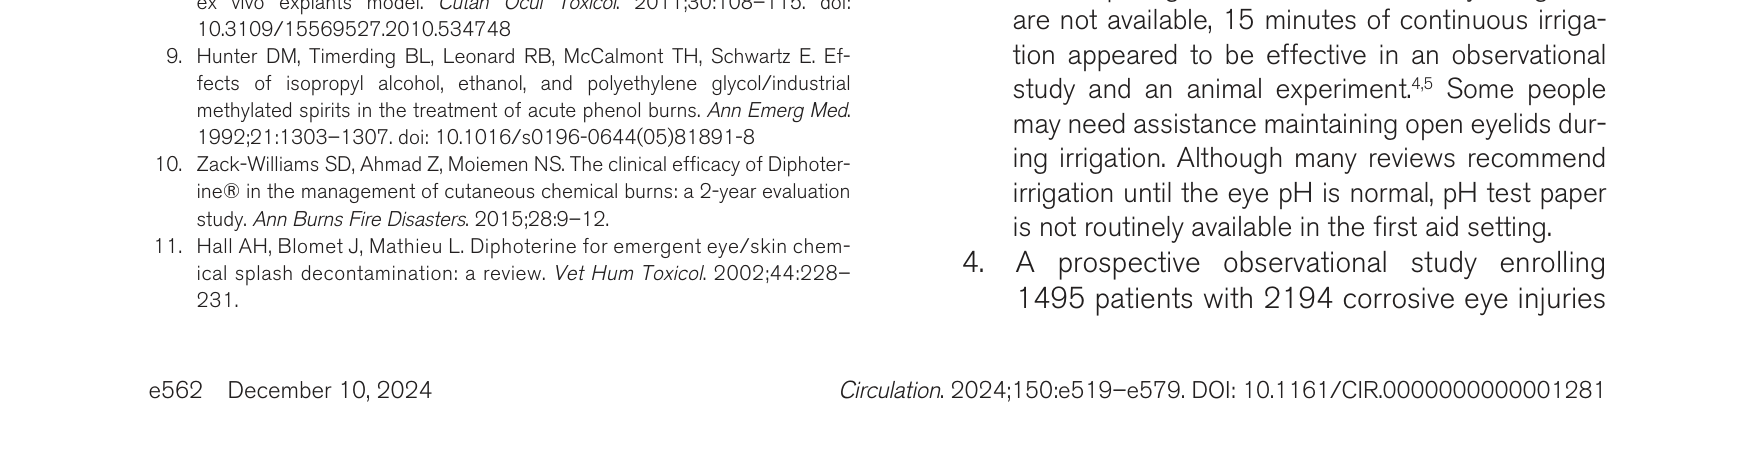

In [39]:
import fitz
from IPython.display import display, Image

pdf = fitz.open("/content/AHA_Guidelines.pdf")

for page_num in [15, 44]:
    page = pdf[page_num - 1]

    # Crop the bottom 20% of the page
    rect = page.rect
    footer = fitz.Rect(
        0,
        rect.height * 0.80,
        rect.width,
        rect.height
    )

    pix = page.get_pixmap(
        matrix=fitz.Matrix(3, 3),
        clip=footer
    )

    image_path = f"/content/first_aid_footer_{page_num}.png"
    pix.save(image_path)

    print(f"PDF page {page_num} footer:")
    display(Image(filename=image_path))

In [40]:
import pandas as pd

path = "/content/guideline_rag_research/data/recommendation_annotations.csv"
df = pd.read_csv(path)

mapping = {
    15: "e533",
    44: "e562"
}

mask = df["document"] == "AHA_Guidelines.pdf"

df.loc[mask, "printed_page"] = (
    df.loc[mask, "pdf_page"].map(mapping)
)

df.to_csv(path, index=False)

print("First Aid printed pages updated.")
print("\nMissing printed pages:")
print(df.groupby("document")["printed_page"].apply(
    lambda x: x.isna().sum()
))

print("\nFinal dataset:", len(df), "records")

First Aid printed pages updated.

Missing printed pages:
document
AHA_Guidelines.pdf    0
lifesupport.pdf       0
Name: printed_page, dtype: int64

Final dataset: 42 records


In [42]:
import pandas as pd
import os

folder = "/content/guideline_rag_research/data"

benchmark_path = os.path.join(
    folder, "independent_benchmark.csv"
)

corpus_path = os.path.join(
    folder, "recommendation_annotations.csv"
)

benchmark = pd.read_csv(benchmark_path)
corpus = pd.read_csv(corpus_path)

print("=" * 55)
print("INDEPENDENT BENCHMARK")
print("=" * 55)

print("Rows:", len(benchmark))
print("Columns:", benchmark.columns.tolist())

display(benchmark.head(10))

print("\n" + "=" * 55)
print("RECOMMENDATION CORPUS")
print("=" * 55)

print("Total recommendations:", len(corpus))
print("Unique recommendation IDs:", corpus["unit_id"].nunique())

display(
    corpus[[
        "unit_id",
        "document",
        "topic",
        "recommendation_text",
        "COR",
        "LOE"
    ]].head(10)
)

INDEPENDENT BENCHMARK
Rows: 0
Columns: ['query_id', 'question', 'split', 'question_author', 'reviewer', 'relevant_unit_ids', 'query_population', 'query_situation', 'query_intervention', 'is_answerable', 'expected_document', 'expected_page', 'question_type', 'review_status', 'review_notes']


,query_id,question,split,question_author,reviewer,relevant_unit_ids,query_population,query_situation,query_intervention,is_answerable,expected_document,expected_page,question_type,review_status,review_notes



RECOMMENDATION CORPUS
Total recommendations: 42
Unique recommendation IDs: 39


,unit_id,document,topic,recommendation_text,COR,LOE
0,UNIT_001,AHA_Guidelines.pdf,Bronchodilators for Asthma With Shortness of B...,First aid providers should assist a person wit...,1,B-R
1,UNIT_002,AHA_Guidelines.pdf,Bronchodilators for Asthma With Shortness of B...,It is reasonable to use either an inhaler with...,2a,B-R
2,UNIT_003,AHA_Guidelines.pdf,Bronchodilators for Asthma With Shortness of B...,If a commercially available spacer is not avai...,2a,B-R
3,UNIT_004,AHA_Guidelines.pdf,First Aid for Chemical Exposure to the Eye,Decontamination by irrigation should be perfor...,1,B-NR
4,UNIT_005,AHA_Guidelines.pdf,First Aid for Chemical Exposure to the Eye,Unless otherwise recommended by local guidelin...,1,C-LD
5,UNIT_006,AHA_Guidelines.pdf,First Aid for Chemical Exposure to the Eye,When providing first aid for chemical eye inju...,1,C-EO
6,UNIT_007,AHA_Guidelines.pdf,First Aid for Chemical Exposure to the Eye,"Eye irrigation with normal saline, Ringer's la...",2a,B-NR
7,UNIT_008,AHA_Guidelines.pdf,First Aid for Chemical Exposure to the Eye,It is reasonable for individuals with ocular e...,2a,C-LD
8,UNIT_009,lifesupport.pdf,Recognition of Cardiac Arrest,"If an adult is unconscious/unresponsive, with ...",1,C-LD
9,UNIT_010,lifesupport.pdf,Recognition of Cardiac Arrest,"If an adult is unconscious/unresponsive, with ...",1,C-LD


In [43]:
import pandas as pd

path = "/content/guideline_rag_research/data/recommendation_annotations.csv"
df = pd.read_csv(path)

duplicates = df[
    df["unit_id"].duplicated(keep=False)
].sort_values("unit_id")

print("Duplicate ID records:")
display(
    duplicates[
        [
            "unit_id",
            "pdf_page",
            "printed_page",
            "topic",
            "recommendation_number",
            "recommendation_text"
        ]
    ]
)

print("\nDuplicate ID counts:")
print(df["unit_id"].value_counts()[lambda x: x > 1])

Duplicate ID records:


,unit_id,pdf_page,printed_page,topic,recommendation_number,recommendation_text
38,UNIT_039,11,S458,Opening the Airway in Adults in Cardiac Arrest,1,"For unresponsive adult patients, health care p..."
39,UNIT_039,11,S458,Opening the Airway in Adults in Cardiac Arrest,2,When managing the airway of an adult with know...
40,UNIT_039,11,S458,Opening the Airway in Adults in Cardiac Arrest,3,"The use of an airway adjunct (eg, oropharyngea..."
41,UNIT_039,11,S458,Opening the Airway in Adults in Cardiac Arrest,4,The routine use of cricoid pressure in adult c...



Duplicate ID counts:
unit_id
UNIT_039    4
Name: count, dtype: int64


In [44]:
import pandas as pd

path = "/content/guideline_rag_research/data/recommendation_annotations.csv"
df = pd.read_csv(path)

# Identify the four page 11 records
mask = (
    (df["document"] == "lifesupport.pdf") &
    (df["pdf_page"] == 11)
)

page11 = df[mask].copy()

if len(page11) != 4:
    raise ValueError(f"Expected 4 page 11 records, found {len(page11)}")

# Assign unique IDs based on recommendation number
new_ids = {
    "1": "UNIT_039",
    "2": "UNIT_040",
    "3": "UNIT_041",
    "4": "UNIT_042"
}

for idx in page11.index:
    rec_num = str(df.loc[idx, "recommendation_number"])
    if rec_num not in new_ids:
        raise ValueError(f"Unexpected recommendation number: {rec_num}")
    df.loc[idx, "unit_id"] = new_ids[rec_num]

# Validate before saving
if df["unit_id"].duplicated().any():
    raise ValueError("Duplicate IDs still exist. File not saved.")

if len(df) != 42 or df["unit_id"].nunique() != 42:
    raise ValueError("Dataset integrity check failed. File not saved.")

df.to_csv(path, index=False)

print("IDs corrected successfully.")
print("Total records:", len(df))
print("Unique IDs:", df["unit_id"].nunique())
print("Duplicate IDs:", df["unit_id"].duplicated().sum())

display(
    df[mask][["unit_id", "recommendation_number", "recommendation_text"]]
)

IDs corrected successfully.
Total records: 42
Unique IDs: 42
Duplicate IDs: 0


,unit_id,recommendation_number,recommendation_text
38,UNIT_039,1,"For unresponsive adult patients, health care p..."
39,UNIT_040,2,When managing the airway of an adult with know...
40,UNIT_041,3,"The use of an airway adjunct (eg, oropharyngea..."
41,UNIT_042,4,The routine use of cricoid pressure in adult c...


In [45]:
import pandas as pd
import os
import shutil
import hashlib
from datetime import datetime

folder = "/content/guideline_rag_research/data"

source = os.path.join(
    folder, "recommendation_annotations.csv"
)

backup = os.path.join(
    folder, "recommendation_annotations_v1_frozen.csv"
)

df = pd.read_csv(source)

# Validate corpus
assert len(df) == 42
assert df["unit_id"].nunique() == 42
assert df["unit_id"].duplicated().sum() == 0
assert (df["verification_status"] == "verified").all()
assert df["printed_page"].notna().all()

# Preserve frozen version
shutil.copy2(source, backup)

# Calculate reproducibility checksum
with open(backup, "rb") as f:
    checksum = hashlib.sha256(f.read()).hexdigest()

print("Frozen corpus created successfully.")
print("Records:", len(df))
print("Unique IDs:", df["unit_id"].nunique())
print("Verified:", (df["verification_status"] == "verified").sum())
print("SHA256:", checksum)
print("Backup:", backup)

Frozen corpus created successfully.
Records: 42
Unique IDs: 42
Verified: 42
SHA256: d7a9b54fdc4d2dffd01a503b69fb457a9d4fe64dd50473ddc4f99153733a35e3
Backup: /content/guideline_rag_research/data/recommendation_annotations_v1_frozen.csv


**Phase 2 — Independent benchmark creation**

In [46]:
import pandas as pd

path = "/content/guideline_rag_research/data/recommendation_annotations_v1_frozen.csv"

df = pd.read_csv(path)

for _, row in df.iterrows():
    print("\n" + "=" * 90)
    print("UNIT ID:", row["unit_id"])
    print("DOCUMENT:", row["document"])
    print("PAGE:", row["printed_page"])
    print("TOPIC:", row["topic"])
    print("RECOMMENDATION:", row["recommendation_text"])
    print("COR:", row["COR"], "| LOE:", row["LOE"])
    print("POPULATION:", row["population"])
    print("SITUATION:", row["situation"])
    print("INTERVENTION:", row["intervention"])


UNIT ID: UNIT_001
DOCUMENT: AHA_Guidelines.pdf
PAGE: e533
TOPIC: Bronchodilators for Asthma With Shortness of Breath
RECOMMENDATION: First aid providers should assist a person with asthma who is having difficulty breathing with the administration of their own prescribed bronchodilators as needed.
COR: 1 | LOE: B-R
POPULATION: Person with asthma
SITUATION: Difficulty breathing
INTERVENTION: Assist with administration of prescribed bronchodilators

UNIT ID: UNIT_002
DOCUMENT: AHA_Guidelines.pdf
PAGE: e533
TOPIC: Bronchodilators for Asthma With Shortness of Breath
RECOMMENDATION: It is reasonable to use either an inhaler with a spacer or a nebulizer when assisting a person with asthma to use their own inhaled bronchodilator medication, in preference to using an inhaler alone.
COR: 2a | LOE: B-R
POPULATION: Person with asthma
SITUATION: Assistance with inhaled bronchodilator medication
INTERVENTION: Use an inhaler with spacer or a nebulizer rather than an inhaler alone

UNIT ID: UNIT_003


In [47]:
import pandas as pd
import os

folder = "/content/guideline_rag_research/data"

corpus_path = os.path.join(
    folder, "recommendation_annotations_v1_frozen.csv"
)
benchmark_path = os.path.join(
    folder, "independent_benchmark.csv"
)

corpus = pd.read_csv(corpus_path)
existing = pd.read_csv(benchmark_path)

if len(existing) > 0:
    raise ValueError(
        "Benchmark already contains rows. Backup and inspect it before replacing."
    )

# Each tuple: (question, relevant recommendation ID, population,
# situation, intervention)

questions = {
"direct": [
("What should a first aid provider do when an adult with asthma is having difficulty breathing?", "UNIT_001", "Person with asthma", "Difficulty breathing", "Assist with prescribed bronchodilator"),
("Which delivery methods are preferred over using an inhaler alone when assisting someone with an inhaled bronchodilator?", "UNIT_002", "Person with asthma", "Assistance with inhaled bronchodilator", "Spacer inhaler or nebulizer"),
("What can be used as a substitute when a commercial spacer is unavailable during an asthma attack?", "UNIT_003", "Person experiencing an asthma attack", "Commercial spacer unavailable", "Improvised spacer"),
("What immediate first aid action is recommended after a chemical enters someone's eyes?", "UNIT_004", "Person with chemical eye exposure", "Immediately after exposure", "Irrigation"),
("How long should copious tap-water irrigation be performed after chemical eye exposure, unless local guidance says otherwise?", "UNIT_005", "Person with chemical eye exposure", "Chemical exposure to eyes", "Irrigate with tap water for 15 minutes"),
("What should first aid providers do to prevent spreading a caustic substance during treatment of a chemical eye injury?", "UNIT_006", "Person with chemical eye injury and first aid providers", "During first aid", "Avoid cross-contamination"),
("Which alternative solutions may be used for eye irrigation if immediately available?", "UNIT_007", "Person with chemical eye exposure", "Alternative solution immediately available", "Saline, Ringer's lactate or commercial eye wash"),
("What guidance should people follow after industrial chemicals enter their eyes?", "UNIT_008", "Person with industrial chemical eye exposure", "Industrial chemical ocular exposure", "Local guidance or poison centre recommendations"),
("What should a lay rescuer assume when an adult is unresponsive and has absent or abnormal breathing?", "UNIT_009", "Unresponsive adult", "Absent or abnormal breathing", "Assume cardiac arrest"),
("How long should a healthcare professional check an unresponsive adult's pulse when breathing is absent or abnormal?", "UNIT_010", "Unresponsive adult", "Absent or abnormal breathing", "Pulse check no longer than 10 seconds"),
("What should lay rescuers provide for an adult with presumed cardiac arrest?", "UNIT_011", "Adult with presumed cardiac arrest", "Lay rescuer response", "Chest compressions"),
("What should a lone responder do first after identifying an adult in cardiac arrest?", "UNIT_012", "Adult in cardiac arrest", "Lone responder identifies cardiac arrest", "Activate emergency response system, then CPR"),
],

"paraphrased": [
("Someone with asthma is struggling to breathe. How should a bystander help them use their prescribed reliever medication?", "UNIT_001", "Person with asthma", "Difficulty breathing", "Assist with prescribed bronchodilator"),
("When helping a person take their inhaled asthma medicine, what options improve delivery compared with using the inhaler by itself?", "UNIT_002", "Person with asthma", "Inhaled bronchodilator assistance", "Spacer inhaler or nebulizer"),
("There is no manufactured spacer available during an asthma episode. What alternative does the guideline consider reasonable?", "UNIT_003", "Person experiencing asthma attack", "Commercial spacer unavailable", "Improvised spacer"),
("A chemical has splashed into a person's eye. Should eye decontamination be delayed?", "UNIT_004", "Person with chemical eye exposure", "Immediately after exposure", "Immediate irrigation"),
("What is the recommended duration for flushing a chemically exposed eye with plenty of tap water?", "UNIT_005", "Person with chemical eye exposure", "Chemical exposure to eyes", "Tap-water irrigation for 15 minutes"),
("During treatment of a chemical eye injury, how can the helper avoid transferring the chemical to another person or the unaffected eye?", "UNIT_006", "Person with chemical eye injury and first aid providers", "During first aid", "Avoid cross-contamination"),
("If saline or a prepared eyewash is readily available, can it be used instead of tap water for eye irrigation?", "UNIT_007", "Person with chemical eye exposure", "Alternative solution immediately available", "Use an accepted alternative irrigation solution"),
("For an eye injury caused by an industrial chemical, where should a person obtain specific guidance?", "UNIT_008", "Person with industrial chemical eye exposure", "Industrial chemical ocular exposure", "Local guidance or poison centre"),
("An adult is unconscious and only gasping. What should a layperson conclude?", "UNIT_009", "Unresponsive adult", "Absent or abnormal breathing", "Assume cardiac arrest"),
("In an unresponsive adult who is not breathing normally, what is the maximum pulse-assessment time for a healthcare professional?", "UNIT_010", "Unresponsive adult", "Absent or abnormal breathing", "Pulse check no longer than 10 seconds"),
("What form of CPR action should every lay rescuer provide when an adult is presumed to be in cardiac arrest?", "UNIT_011", "Adult with presumed cardiac arrest", "Lay rescuer response", "Chest compressions"),
("A single responder recognises adult cardiac arrest. What sequence of actions is recommended?", "UNIT_012", "Adult in cardiac arrest", "Lone responder identifies cardiac arrest", "Activate emergency response system, then CPR"),
],

"context_dependent": [
("A person with asthma is breathless and has their own prescribed inhaled bronchodilator. What assistance does the first aid guideline recommend?", "UNIT_001", "Person with asthma", "Difficulty breathing", "Assist with prescribed bronchodilator"),
("A person with asthma needs help taking an inhaled bronchodilator, and both a spacer and nebulizer are available. Which delivery approaches are supported?", "UNIT_002", "Person with asthma", "Assistance with inhaled bronchodilator", "Spacer inhaler or nebulizer"),
("During an asthma attack, the person has their prescribed inhaler but no commercial spacer. What alternative is supported?", "UNIT_003", "Person experiencing asthma attack", "Commercial spacer unavailable", "Improvised spacer"),
("A chemical exposure to the eye has just occurred. What action should be initiated immediately?", "UNIT_004", "Person with chemical eye exposure", "Immediately after exposure", "Immediate irrigation"),
("A person has a chemical eye injury and no different local instruction applies. What irrigation method and duration are specified?", "UNIT_005", "Person with chemical eye exposure", "Chemical exposure to eyes", "Copious tap water for 15 minutes"),
("A helper is irrigating one eye after chemical exposure. What precautions should be taken to protect other people, surfaces and the other eye?", "UNIT_006", "Person with chemical eye injury and first aid providers", "During first aid", "Avoid cross-contamination"),
("After chemical eye exposure, normal saline is immediately available. What does the recommendation say about using it?", "UNIT_007", "Person with chemical eye exposure", "Alternative solution immediately available", "Use saline as an alternative irrigation solution"),
("An industrial chemical has entered someone's eye. What additional source of instructions does the guideline identify?", "UNIT_008", "Person with industrial chemical eye exposure", "Industrial chemical ocular exposure", "Local guidance or poison centre"),
("A lay rescuer finds an unresponsive adult who is gasping. What should the rescuer presume?", "UNIT_009", "Unresponsive adult", "Absent or abnormal breathing, including gasping", "Assume cardiac arrest"),
("A healthcare professional assesses an unresponsive adult with abnormal breathing but cannot confidently detect a pulse within the permitted check. What should be presumed?", "UNIT_010", "Unresponsive adult", "Absent or abnormal breathing", "Check pulse for no more than 10 seconds and assume cardiac arrest if no definite pulse"),
("A bystander without a stated CPR-training requirement encounters an adult with presumed cardiac arrest. What action should the lay rescuer provide?", "UNIT_011", "Adult with presumed cardiac arrest", "Lay rescuer response", "Chest compressions"),
("One responder is alone when adult cardiac arrest is identified. Which action should precede starting CPR?", "UNIT_012", "Adult in cardiac arrest", "Lone responder identifies cardiac arrest", "Activate emergency response system, then begin CPR"),
],

"hard_negative": [
("A person with asthma is breathless. Should the helper administer someone else's bronchodilator, or assist with the person's own prescribed medication?", "UNIT_001", "Person with asthma", "Difficulty breathing", "Assist with the person's own prescribed bronchodilator"),
("For an asthma patient using their own inhaler, is an inhaler with a spacer or nebulizer preferred over an inhaler alone?", "UNIT_002", "Person with asthma", "Inhaled bronchodilator assistance", "Spacer or nebulizer rather than inhaler alone"),
("A commercial spacer is available during an asthma attack. Does the recommendation about an improvised spacer apply in this situation?", "UNIT_003", "Person experiencing asthma attack", "Commercial spacer availability", "Improvised spacer only when commercial spacer is unavailable"),
("After a chemical enters the eye, should irrigation wait until the chemical is identified, or begin immediately?", "UNIT_004", "Person with chemical eye exposure", "Immediately after exposure", "Immediate irrigation"),
("For chemical eye exposure, is the specified 15-minute irrigation recommendation about tap water or about waiting 15 minutes before irrigation?", "UNIT_005", "Person with chemical eye exposure", "Chemical exposure to eyes", "Irrigate with copious tap water for 15 minutes"),
("When treating a chemical eye injury, should the helper avoid contaminating only the injured person, or also other people, areas and the other eye?", "UNIT_006", "Person with chemical eye injury and first aid providers", "During first aid", "Avoid cross-contamination"),
("If commercial eye wash is immediately available, does the recommendation support it as an irrigation option or require tap water exclusively?", "UNIT_007", "Person with chemical eye exposure", "Alternative solution immediately available", "Commercial eye wash is an acceptable alternative"),
("For industrial chemical exposure to the eye, does the recommendation specify a universal treatment duration or refer to local guidance or a poison centre?", "UNIT_008", "Person with industrial chemical eye exposure", "Industrial chemical ocular exposure", "Follow local guidance or poison centre recommendations"),
("An unresponsive adult is gasping. Should a lay rescuer wait for a healthcare professional to check the pulse before assuming cardiac arrest?", "UNIT_009", "Unresponsive adult", "Absent or abnormal breathing, including gasping", "Lay rescuer assumes cardiac arrest"),
("An unresponsive adult has abnormal breathing. Is the 10-second pulse-check instruction for the lay rescuer or the healthcare professional?", "UNIT_010", "Unresponsive adult", "Absent or abnormal breathing", "Healthcare professional checks pulse for no more than 10 seconds"),
("An adult is in presumed cardiac arrest. Does the recommendation for all lay rescuers concern chest compressions or ventilation alone?", "UNIT_011", "Adult with presumed cardiac arrest", "Lay rescuer response", "Provide chest compressions"),
("A lone responder identifies adult cardiac arrest. Should CPR begin before activating the emergency response system, or should the system be activated first?", "UNIT_012", "Adult in cardiac arrest", "Lone responder identifies cardiac arrest", "Activate emergency response system first, then CPR"),
],

"out_of_scope": [
("What is the recommended CPR compression rate for an infant in cardiac arrest?", None, "Infant", "Infant cardiac arrest", "Not represented in this corpus"),
("Which medication dose should be administered to a child experiencing an asthma attack?", None, "Child with asthma", "Paediatric asthma attack", "Not represented in this corpus"),
("What is the recommended treatment for a person who has swallowed a household cleaning product?", None, "Person with ingestion exposure", "Chemical ingestion", "Not represented in this corpus"),
("Which dressing should be applied to control severe bleeding from a deep leg wound?", None, "Person with severe bleeding", "Deep leg wound", "Not represented in this corpus"),
("What is the recommended first aid treatment for a suspected spinal fracture after a fall?", None, "Person with suspected spinal fracture", "Fall-related spinal injury", "Not represented in this corpus"),
("What is the recommended management for an adult experiencing a severe allergic reaction with anaphylaxis?", None, "Adult with suspected anaphylaxis", "Anaphylactic reaction", "Not represented in this corpus"),
("What is the recommended compression-to-ventilation ratio for a child receiving CPR?", None, "Child in cardiac arrest", "Paediatric CPR", "Not represented in this corpus"),
("What should a first aider do when a person is choking and cannot speak or cough?", None, "Person with airway obstruction", "Choking", "Not represented in this corpus"),
("What is the recommended first aid approach for a suspected stroke?", None, "Person with suspected stroke", "Possible stroke", "Not represented in this corpus"),
("How should a first aider manage a suspected burn caused by hot liquid?", None, "Person with thermal burn", "Scald injury", "Not represented in this corpus"),
("What is the recommended treatment for a person experiencing heat stroke?", None, "Person with heat stroke", "Heat-related illness", "Not represented in this corpus"),
("What is the recommended CPR approach for a pregnant adult in cardiac arrest?", None, "Pregnant adult", "Cardiac arrest during pregnancy", "Not represented in this corpus"),
]
}

# Build a lookup from the frozen corpus
corpus_index = corpus.set_index("unit_id").to_dict("index")

rows = []
counter = 1

for category, items in questions.items():
    for question, unit_id, population, situation, intervention in items:

        if unit_id is None:
            document = ""
            page = ""
            relevant_ids = ""
            answerable = False
            notes = "Draft out-of-scope query; verify that no supporting unit exists in the frozen corpus."
        else:
            if unit_id not in corpus_index:
                raise ValueError(f"Unknown recommendation ID: {unit_id}")

            source = corpus_index[unit_id]
            document = source["document"]
            page = source["printed_page"]
            relevant_ids = unit_id
            answerable = True
            notes = "Draft answer mapping; independently review question wording and relevance."

        rows.append({
            "query_id": f"Q{counter:03d}",
            "question": question,
            "split": "test",
            "question_author": "Researcher-generated draft",
            "reviewer": "",
            "relevant_unit_ids": relevant_ids,
            "query_population": population,
            "query_situation": situation,
            "query_intervention": intervention,
            "is_answerable": answerable,
            "expected_document": document,
            "expected_page": page,
            "question_type": category,
            "review_status": "pending",
            "review_notes": notes
        })
        counter += 1

benchmark = pd.DataFrame(rows)

# Validate benchmark
assert len(benchmark) == 60
assert benchmark["query_id"].nunique() == 60
assert benchmark["review_status"].eq("pending").all()

for _, row in benchmark[benchmark["is_answerable"]].iterrows():
    assert row["relevant_unit_ids"] in corpus_index

benchmark.to_csv(benchmark_path, index=False)

print("BENCHMARK DRAFT CREATED")
print("=" * 45)
print("Total questions:", len(benchmark))
print("\nQuestion counts:")
print(benchmark["question_type"].value_counts())
print("\nAnswerable:", benchmark["is_answerable"].sum())
print("Out of scope:", (~benchmark["is_answerable"]).sum())
print("Review status:")
print(benchmark["review_status"].value_counts())
print("\nSaved to:", benchmark_path)

display(benchmark.head(10))

BENCHMARK DRAFT CREATED
Total questions: 60

Question counts:
question_type
direct               12
paraphrased          12
context_dependent    12
hard_negative        12
out_of_scope         12
Name: count, dtype: int64

Answerable: 48
Out of scope: 12
Review status:
review_status
pending    60
Name: count, dtype: int64

Saved to: /content/guideline_rag_research/data/independent_benchmark.csv


,query_id,question,split,question_author,reviewer,relevant_unit_ids,query_population,query_situation,query_intervention,is_answerable,expected_document,expected_page,question_type,review_status,review_notes
0,Q001,What should a first aid provider do when an ad...,test,Researcher-generated draft,,UNIT_001,Person with asthma,Difficulty breathing,Assist with prescribed bronchodilator,True,AHA_Guidelines.pdf,e533,direct,pending,Draft answer mapping; independently review que...
1,Q002,Which delivery methods are preferred over usin...,test,Researcher-generated draft,,UNIT_002,Person with asthma,Assistance with inhaled bronchodilator,Spacer inhaler or nebulizer,True,AHA_Guidelines.pdf,e533,direct,pending,Draft answer mapping; independently review que...
2,Q003,What can be used as a substitute when a commer...,test,Researcher-generated draft,,UNIT_003,Person experiencing an asthma attack,Commercial spacer unavailable,Improvised spacer,True,AHA_Guidelines.pdf,e533,direct,pending,Draft answer mapping; independently review que...
3,Q004,What immediate first aid action is recommended...,test,Researcher-generated draft,,UNIT_004,Person with chemical eye exposure,Immediately after exposure,Irrigation,True,AHA_Guidelines.pdf,e562,direct,pending,Draft answer mapping; independently review que...
4,Q005,How long should copious tap-water irrigation b...,test,Researcher-generated draft,,UNIT_005,Person with chemical eye exposure,Chemical exposure to eyes,Irrigate with tap water for 15 minutes,True,AHA_Guidelines.pdf,e562,direct,pending,Draft answer mapping; independently review que...
5,Q006,What should first aid providers do to prevent ...,test,Researcher-generated draft,,UNIT_006,Person with chemical eye injury and first aid ...,During first aid,Avoid cross-contamination,True,AHA_Guidelines.pdf,e562,direct,pending,Draft answer mapping; independently review que...
6,Q007,Which alternative solutions may be used for ey...,test,Researcher-generated draft,,UNIT_007,Person with chemical eye exposure,Alternative solution immediately available,"Saline, Ringer's lactate or commercial eye wash",True,AHA_Guidelines.pdf,e562,direct,pending,Draft answer mapping; independently review que...
7,Q008,What guidance should people follow after indus...,test,Researcher-generated draft,,UNIT_008,Person with industrial chemical eye exposure,Industrial chemical ocular exposure,Local guidance or poison centre recommendations,True,AHA_Guidelines.pdf,e562,direct,pending,Draft answer mapping; independently review que...
8,Q009,What should a lay rescuer assume when an adult...,test,Researcher-generated draft,,UNIT_009,Unresponsive adult,Absent or abnormal breathing,Assume cardiac arrest,True,lifesupport.pdf,S455,direct,pending,Draft answer mapping; independently review que...
9,Q010,How long should a healthcare professional chec...,test,Researcher-generated draft,,UNIT_010,Unresponsive adult,Absent or abnormal breathing,Pulse check no longer than 10 seconds,True,lifesupport.pdf,S455,direct,pending,Draft answer mapping; independently review que...


In [49]:
import pandas as pd

folder = "/content/guideline_rag_research/data"

corpus = pd.read_csv(
    f"{folder}/recommendation_annotations_v1_frozen.csv"
)

benchmark = pd.read_csv(
    f"{folder}/independent_benchmark.csv"
)

answerable = benchmark[
    benchmark["is_answerable"] == True
].copy()

used_ids = set()

for value in answerable["relevant_unit_ids"].dropna():
    for unit_id in str(value).split(";"):
        if unit_id.strip():
            used_ids.add(unit_id.strip())

all_ids = set(corpus["unit_id"])

unused_ids = sorted(all_ids - used_ids)

print("BENCHMARK COVERAGE AUDIT")
print("=" * 45)

print("Total corpus units:", len(all_ids))
print("Units represented:", len(used_ids))
print("Units not represented:", len(unused_ids))

print("\nCoverage percentage:",
      round(len(used_ids) / len(all_ids) * 100, 2), "%")

print("\nUnused recommendation IDs:")
print(unused_ids)

print("\nQuestion distribution:")
print(benchmark["question_type"].value_counts())

print("\nQuestions by relevant recommendation:")
print(answerable["relevant_unit_ids"].value_counts())

BENCHMARK COVERAGE AUDIT
Total corpus units: 42
Units represented: 12
Units not represented: 30

Coverage percentage: 28.57 %

Unused recommendation IDs:
['UNIT_013', 'UNIT_014', 'UNIT_015', 'UNIT_016', 'UNIT_017', 'UNIT_018', 'UNIT_019', 'UNIT_020', 'UNIT_021', 'UNIT_022', 'UNIT_023', 'UNIT_024', 'UNIT_025', 'UNIT_026', 'UNIT_027', 'UNIT_028', 'UNIT_029', 'UNIT_030', 'UNIT_031', 'UNIT_032', 'UNIT_033', 'UNIT_034', 'UNIT_035', 'UNIT_036', 'UNIT_037', 'UNIT_038', 'UNIT_039', 'UNIT_040', 'UNIT_041', 'UNIT_042']

Question distribution:
question_type
direct               12
paraphrased          12
context_dependent    12
hard_negative        12
out_of_scope         12
Name: count, dtype: int64

Questions by relevant recommendation:
relevant_unit_ids
UNIT_001    4
UNIT_002    4
UNIT_003    4
UNIT_004    4
UNIT_005    4
UNIT_006    4
UNIT_007    4
UNIT_008    4
UNIT_009    4
UNIT_010    4
UNIT_011    4
UNIT_012    4
Name: count, dtype: int64


In [50]:
import pandas as pd
import os

folder = "/content/guideline_rag_research/data"

corpus = pd.read_csv(
    f"{folder}/recommendation_annotations_v1_frozen.csv"
)

# Create a coverage worksheet with every recommendation
coverage = corpus[[
    "unit_id",
    "document",
    "printed_page",
    "topic",
    "recommendation_text",
    "population",
    "situation",
    "intervention",
    "COR",
    "LOE"
]].copy()

coverage["direct_question"] = ""
coverage["paraphrased_question"] = ""
coverage["context_question"] = ""
coverage["hard_negative_question"] = ""
coverage["selected_question_types"] = ""
coverage["review_status"] = "pending"
coverage["review_notes"] = ""

output = f"{folder}/benchmark_coverage_review.csv"
coverage.to_csv(output, index=False)

print("Coverage review sheet created.")
print("Recommendation units:", len(coverage))
print("Unique recommendation IDs:", coverage["unit_id"].nunique())
print("Missing recommendation IDs:", coverage["unit_id"].isna().sum())
print("Output:", output)

display(coverage[[
    "unit_id", "topic", "population",
    "situation", "intervention", "review_status"
]])

Coverage review sheet created.
Recommendation units: 42
Unique recommendation IDs: 42
Missing recommendation IDs: 0
Output: /content/guideline_rag_research/data/benchmark_coverage_review.csv


,unit_id,topic,population,situation,intervention,review_status
0,UNIT_001,Bronchodilators for Asthma With Shortness of B...,Person with asthma,Difficulty breathing,Assist with administration of prescribed bronc...,pending
1,UNIT_002,Bronchodilators for Asthma With Shortness of B...,Person with asthma,Assistance with inhaled bronchodilator medication,Use an inhaler with spacer or a nebulizer rath...,pending
2,UNIT_003,Bronchodilators for Asthma With Shortness of B...,Person experiencing an asthma attack,Commercially available spacer is unavailable,Use an improvised spacer,pending
3,UNIT_004,First Aid for Chemical Exposure to the Eye,Person with chemical eye exposure,Immediately after chemical exposure,Perform immediate irrigation,pending
4,UNIT_005,First Aid for Chemical Exposure to the Eye,Person with chemical eye exposure,Chemical exposure to the eyes,Irrigate with copious tap water for 15 minutes,pending
5,UNIT_006,First Aid for Chemical Exposure to the Eye,Person with chemical eye injury and first aid ...,During first aid for chemical eye injury,Avoid cross-contamination,pending
6,UNIT_007,First Aid for Chemical Exposure to the Eye,Person with chemical eye exposure,An alternative irrigation solution is immediat...,"Use saline, Ringer's lactate, or commercial ey...",pending
7,UNIT_008,First Aid for Chemical Exposure to the Eye,Individuals with industrial chemical eye exposure,Ocular exposure to industrial chemicals,Follow local guidelines or poison center recom...,pending
8,UNIT_009,Recognition of Cardiac Arrest,Unresponsive adult,"Absent or abnormal breathing, including gasping",Lay rescuer should assume cardiac arrest,pending
9,UNIT_010,Recognition of Cardiac Arrest,Unresponsive adult,Absent or abnormal breathing,Healthcare professional checks pulse for no mo...,pending


In [52]:
import pandas as pd
from pathlib import Path

path = Path("/content/guideline_rag_research/data/benchmark_coverage_review.csv")
df = pd.read_csv(path)

questions = {
    "UNIT_001": ("direct", "What should a first aid provider do to help a person with asthma who is having difficulty breathing?"),
    "UNIT_002": ("paraphrased", "When helping someone use their prescribed inhaled bronchodilator, which delivery method is preferred over using an inhaler by itself?"),
    "UNIT_003": ("context", "A person having an asthma attack needs their prescribed inhaled bronchodilator, but no commercial spacer is available. What alternative does the guideline consider reasonable?"),
    "UNIT_004": ("direct", "What immediate decontamination action is recommended after a chemical substance enters a person's eye?"),
    "UNIT_005": ("paraphrased", "For chemical exposure to the eyes, what irrigation fluid and duration are recommended unless local guidelines specify otherwise?"),
    "UNIT_006": ("context", "While helping someone whose eye has been exposed to a caustic chemical, what precautions should be taken to prevent the substance from spreading to other people, areas, or the other eye?"),
    "UNIT_007": ("hard_negative", "For chemical eye exposure, if normal saline, Ringer's lactate, or commercial eyewash is immediately available, what does the guideline say about using these alternatives?"),
    "UNIT_008": ("hard_negative", "Does the guideline give a universal irrigation procedure for every industrial chemical eye exposure, or does it direct providers to follow local guidance and consult a poison center?"),
    "UNIT_009": ("direct", "According to the guideline, when should a lay rescuer presume that an unresponsive adult is in cardiac arrest?"),
    "UNIT_010": ("hard_negative", "During adult cardiac arrest assessment, how long should a healthcare professional check for a pulse before assuming cardiac arrest if no definite pulse is detected?"),
    "UNIT_011": ("paraphrased", "What is the recommended role of lay rescuers in providing chest compressions when an adult is presumed to be in cardiac arrest?"),
    "UNIT_012": ("context", "A lone responder witnesses an adult collapse and suspects cardiac arrest. What should the responder do first regarding activation of the emergency response system and starting CPR?"),
    "UNIT_013": ("hard_negative", "How does the recommended sequence differ for a lone rescuer who has a mobile phone available to activate the emergency response system while beginning CPR?"),
    "UNIT_014": ("paraphrased", "For a trained lay rescuer responding to an adult in cardiac arrest, what does the guideline say about providing both rescue breaths and chest compressions?")
}

# Convert blank columns to text-compatible types
text_columns = [
    "direct_question",
    "paraphrased_question",
    "context_question",
    "hard_negative_question",
    "selected_question_types",
    "review_status",
    "review_notes"
]

for col in text_columns:
    if col in df.columns:
        df[col] = df[col].astype("object")

assert df["unit_id"].is_unique, "Duplicate unit IDs found."
assert set(questions).issubset(set(df["unit_id"])), "Some unit IDs are missing."

for unit_id, (qtype, question) in questions.items():
    idx = df.index[df["unit_id"] == unit_id][0]
    column = f"{qtype}_question"

    existing = df.at[idx, column]
    if pd.notna(existing) and str(existing).strip():
        raise ValueError(f"{unit_id} already contains a question in {column}.")

    df.at[idx, column] = question
    df.at[idx, "selected_question_types"] = qtype
    df.at[idx, "review_status"] = "pending"
    df.at[idx, "review_notes"] = "Batch 1 draft; requires source and ambiguity review."

df.to_csv(path, index=False)

print("Batch 1 saved successfully.")
print("Questions added:", len(questions))
print("\nQuestion type distribution:")
print(df[df["unit_id"].isin(questions)]
      ["selected_question_types"].value_counts())

Batch 1 saved successfully.
Questions added: 14

Question type distribution:
selected_question_types
paraphrased      4
hard_negative    4
direct           3
context          3
Name: count, dtype: int64


In [53]:
df_check = pd.read_csv(path)

display(
    df_check[df_check["unit_id"].isin(questions.keys())][
        ["unit_id", "selected_question_types",
         "direct_question", "paraphrased_question",
         "context_question", "hard_negative_question"]
    ]
)

print("Total corpus units:", len(df_check))
print("Questions populated:", df_check["selected_question_types"].notna().sum())

,unit_id,selected_question_types,direct_question,paraphrased_question,context_question,hard_negative_question
0,UNIT_001,direct,What should a first aid provider do to help a ...,NaN,NaN,NaN
1,UNIT_002,paraphrased,NaN,When helping someone use their prescribed inha...,NaN,NaN
2,UNIT_003,context,NaN,NaN,A person having an asthma attack needs their p...,NaN
3,UNIT_004,direct,What immediate decontamination action is recom...,NaN,NaN,NaN
4,UNIT_005,paraphrased,NaN,"For chemical exposure to the eyes, what irriga...",NaN,NaN
5,UNIT_006,context,NaN,NaN,While helping someone whose eye has been expos...,NaN
6,UNIT_007,hard_negative,NaN,NaN,NaN,"For chemical eye exposure, if normal saline, R..."
7,UNIT_008,hard_negative,NaN,NaN,NaN,Does the guideline give a universal irrigation...
8,UNIT_009,direct,"According to the guideline, when should a lay ...",NaN,NaN,NaN
9,UNIT_010,hard_negative,NaN,NaN,NaN,"During adult cardiac arrest assessment, how lo..."


Total corpus units: 42
Questions populated: 14


In [54]:
import pandas as pd
from pathlib import Path

path = Path("/content/guideline_rag_research/data/benchmark_coverage_review.csv")
df = pd.read_csv(path)

questions_batch2 = {
    "UNIT_015": ("context",
        "Two rescuers are preparing to perform CPR on an adult. If personal protective equipment is immediately available, what does the guideline say about using it?"),

    "UNIT_016": ("hard_negative",
        "When a lone healthcare professional begins adult cardiac arrest resuscitation, should the initial action prioritize chest compressions or ventilation?"),

    "UNIT_017": ("paraphrased",
        "For adult cardiac arrest caused by either cardiac or noncardiac conditions, what does the guideline consider reasonable for healthcare professionals to provide?"),

    "UNIT_018": ("context",
        "A trained rescuer is managing the airway of an adult with suspected head or neck trauma during cardiac arrest. Which airway-opening manoeuvre is recommended without extending the head?"),

    "UNIT_019": ("hard_negative",
        "If a jaw-thrust manoeuvre and airway adjunct insertion are unsuccessful in an adult with head or neck trauma, which alternative airway-opening manoeuvre should a trained rescuer use?"),

    "UNIT_020": ("hard_negative",
        "For a lay rescuer assisting an adult with suspected spinal injury, does the guideline recommend using a rigid cervical device to restrict spinal movement?"),

    "UNIT_021": ("direct",
        "During adult chest compressions, what approximate height should the person's torso be positioned at relative to the rescuer's knees?"),

    "UNIT_022": ("direct",
        "Where should the rescuer place their hands when performing chest compressions on an adult, and how should the hands be positioned?"),

    "UNIT_023": ("context",
        "An adult experiences cardiac arrest in a location where CPR can be performed safely and effectively. Where should resuscitation generally take place?"),

    "UNIT_024": ("paraphrased",
        "What surface and body position are preferred for adult CPR when they can be achieved without delaying resuscitation?"),

    "UNIT_025": ("hard_negative",
        "Does the guideline state that a rescuer may consider placing their dominant hand on the sternum during adult chest compressions?"),

    "UNIT_026": ("context",
        "An adult is found in cardiac arrest while lying prone, and turning the person supine is not possible safely. What CPR approach may be considered?"),

    "UNIT_027": ("direct",
        "What does the guideline recommend about the duration of pauses immediately before and after a defibrillation shock?"),

    "UNIT_028": ("hard_negative",
        "During adult CPR rhythm checks, what is the maximum recommended duration for a pulse check before chest compressions should be restarted if no definite pulse is detected?")
}

# Convert relevant columns to object dtype before inserting text
text_columns = [
    "direct_question", "paraphrased_question",
    "context_question", "hard_negative_question",
    "selected_question_types", "review_status", "review_notes"
]

for col in text_columns:
    df[col] = df[col].astype("object")

assert df["unit_id"].is_unique, "Duplicate unit IDs found."
assert set(questions_batch2).issubset(set(df["unit_id"])), "Some unit IDs are missing."

for unit_id, (qtype, question) in questions_batch2.items():
    idx = df.index[df["unit_id"] == unit_id][0]
    column = f"{qtype}_question"

    existing = df.at[idx, column]
    if pd.notna(existing) and str(existing).strip():
        raise ValueError(f"{unit_id} already has a question in {column}.")

    df.at[idx, column] = question
    df.at[idx, "selected_question_types"] = qtype
    df.at[idx, "review_status"] = "pending"
    df.at[idx, "review_notes"] = "Batch 2 draft; requires source and ambiguity review."

df.to_csv(path, index=False)

print("Batch 2 saved successfully.")
print("Questions added:", len(questions_batch2))
print("\nQuestion type distribution:")
print(df[df["unit_id"].isin(questions_batch2)]
      ["selected_question_types"].value_counts())

print("\nTotal questions populated:",
      df["selected_question_types"].notna().sum())

Batch 2 saved successfully.
Questions added: 14

Question type distribution:
selected_question_types
hard_negative    5
context          4
direct           3
paraphrased      2
Name: count, dtype: int64

Total questions populated: 28


In [55]:
df_check = pd.read_csv(path)

display(
    df_check[df_check["unit_id"].isin(questions_batch2.keys())][
        ["unit_id", "selected_question_types",
         "direct_question", "paraphrased_question",
         "context_question", "hard_negative_question"]
    ]
)

,unit_id,selected_question_types,direct_question,paraphrased_question,context_question,hard_negative_question
14,UNIT_015,context,NaN,NaN,Two rescuers are preparing to perform CPR on a...,NaN
15,UNIT_016,hard_negative,NaN,NaN,NaN,When a lone healthcare professional begins adu...
16,UNIT_017,paraphrased,NaN,For adult cardiac arrest caused by either card...,NaN,NaN
17,UNIT_018,context,NaN,NaN,A trained rescuer is managing the airway of an...,NaN
18,UNIT_019,hard_negative,NaN,NaN,NaN,If a jaw-thrust manoeuvre and airway adjunct i...
19,UNIT_020,hard_negative,NaN,NaN,NaN,For a lay rescuer assisting an adult with susp...
20,UNIT_021,direct,"During adult chest compressions, what approxim...",NaN,NaN,NaN
21,UNIT_022,direct,Where should the rescuer place their hands whe...,NaN,NaN,NaN
22,UNIT_023,context,NaN,NaN,An adult experiences cardiac arrest in a locat...,NaN
23,UNIT_024,paraphrased,NaN,What surface and body position are preferred f...,NaN,NaN


In [56]:
df_check = pd.read_csv(path)

print("Total records:", len(df_check))
print("Unique recommendation IDs:", df_check["unit_id"].nunique())
print("Questions populated:", df_check["selected_question_types"].notna().sum())
print("Pending reviews:", (df_check["review_status"] == "pending").sum())

print("\nQuestion type distribution:")
print(df_check["selected_question_types"].value_counts(dropna=False))

print("\nMissing question assignments:")
display(df_check[df_check["selected_question_types"].isna()][["unit_id", "topic"]])

print("\nCoverage by document:")
display(df_check.groupby("document")["unit_id"].count())


Total records: 42
Unique recommendation IDs: 42
Questions populated: 28
Pending reviews: 42

Question type distribution:
selected_question_types
NaN              14
hard_negative     9
context           7
direct            6
paraphrased       6
Name: count, dtype: int64

Missing question assignments:


,unit_id,topic
28,UNIT_029,Chest Compression Fraction and Pauses
29,UNIT_030,Chest Compression Fraction and Pauses
30,UNIT_031,Chest Compression Fraction and Pauses
31,UNIT_032,Chest Compression Fraction and Pauses
32,UNIT_033,Chest Compression Fraction and Pauses
33,UNIT_034,Chest Compression Depth and Rate in Adult Card...
34,UNIT_035,Chest Compression Depth and Rate in Adult Card...
35,UNIT_036,Chest Compression Depth and Rate in Adult Card...
36,UNIT_037,Chest Compression Depth and Rate in Adult Card...
37,UNIT_038,Chest Compression Depth and Rate in Adult Card...



Coverage by document:


document
AHA_Guidelines.pdf     8
lifesupport.pdf       34
Name: unit_id, dtype: int64

In [57]:
import pandas as pd
from pathlib import Path

path = Path("/content/guideline_rag_research/data/benchmark_coverage_review.csv")
df = pd.read_csv(path)

batch3 = {
    "UNIT_029": ("hard_negative", "After an adult receives a defibrillation shock during cardiac arrest, should rescuers immediately resume chest compressions or pause to check the rhythm first?"),
    "UNIT_030": ("direct", "When two or more rescuers are providing adult CPR, how often should they switch the person performing chest compressions?"),
    "UNIT_031": ("context", "During adult CPR without an advanced airway, a rescuer needs to provide two breaths. What does the guideline recommend about pausing chest compressions and the duration of each breath?"),
    "UNIT_032": ("paraphrased", "What minimum chest compression fraction may be reasonable during adult CPR, according to the guideline?"),
    "UNIT_033": ("hard_negative", "For adult CPR outside advanced life support settings with invasive monitoring, does the guideline establish a definite benefit from checking the pulse during CPR?"),
    "UNIT_034": ("direct", "What compression depth is recommended for adults, including the minimum depth and the depth that rescuers should avoid exceeding?"),
    "UNIT_035": ("paraphrased", "What role may audiovisual feedback devices play in improving the quality of adult CPR in real time?"),
    "UNIT_036": ("direct", "What is the recommended chest compression rate per minute for adults receiving CPR?"),
    "UNIT_037": ("context", "A rescuer is leaning on an adult's chest between compressions, preventing it from returning fully to its normal position. What does the guideline recommend about chest recoil?"),
    "UNIT_038": ("hard_negative", "During adult CPR, what relationship between the time spent compressing the chest and the time allowing it to recoil may be reasonable?"),
    "UNIT_039": ("context", "When opening the airway of an adult in cardiac arrest, with no suspected cervical spine injury, which manoeuvre is recommended?"),
    "UNIT_040": ("hard_negative", "For an adult in cardiac arrest with a suspected basal skull fracture or severe coagulopathy, which type of airway adjunct does the guideline prefer: an oropharyngeal or a nasopharyngeal airway?"),
    "UNIT_041": ("paraphrased", "In an unconscious adult who has no cough or gag reflex, under what circumstances may using an airway adjunct be reasonable to facilitate ventilation?"),
    "UNIT_042": ("direct", "What does the guideline recommend about routinely applying cricoid pressure during adult cardiac arrest?")
}

text_columns = [
    "direct_question", "paraphrased_question",
    "context_question", "hard_negative_question",
    "selected_question_types", "review_status", "review_notes"
]

for col in text_columns:
    df[col] = df[col].astype("object")

assert df["unit_id"].is_unique
assert set(batch3).issubset(set(df["unit_id"]))

for unit_id, (qtype, question) in batch3.items():
    idx = df.index[df["unit_id"] == unit_id][0]
    column = f"{qtype}_question"

    existing = df.at[idx, column]
    if pd.notna(existing) and str(existing).strip():
        raise ValueError(f"{unit_id} already has a question. Stopping to avoid overwrite.")

    df.at[idx, column] = question
    df.at[idx, "selected_question_types"] = qtype
    df.at[idx, "review_status"] = "pending"
    df.at[idx, "review_notes"] = "Batch 3 draft; requires source and ambiguity review."

df.to_csv(path, index=False)

print("Batch 3 saved successfully.")
print("Questions added:", len(batch3))
print("Total populated:", df["selected_question_types"].notna().sum())

Batch 3 saved successfully.
Questions added: 14
Total populated: 42


In [58]:
df_check = pd.read_csv(path)

print("Total records:", len(df_check))
print("Unique IDs:", df_check["unit_id"].nunique())
print("Questions populated:", df_check["selected_question_types"].notna().sum())
print("\nRemaining missing units:")
display(df_check[df_check["selected_question_types"].isna()][["unit_id", "topic"]])

Total records: 42
Unique IDs: 42
Questions populated: 42

Remaining missing units:


,unit_id,topic


In [59]:
import pandas as pd
from pathlib import Path

data_dir = Path("/content/guideline_rag_research/data")
source_path = data_dir / "benchmark_coverage_review.csv"
output_path = data_dir / "benchmark_core_42_review.csv"

df = pd.read_csv(source_path)

type_to_column = {
    "direct": "direct_question",
    "paraphrased": "paraphrased_question",
    "context": "context_question",
    "hard_negative": "hard_negative_question"
}

# Select the actual question from the assigned question-type column
def get_question(row):
    qtype = row["selected_question_types"]
    column = type_to_column.get(qtype)
    return row[column] if column else None

review = pd.DataFrame({
    "query_id": df["unit_id"],
    "question": df.apply(get_question, axis=1),
    "question_type": df["selected_question_types"],
    "relevant_unit_id": df["unit_id"],
    "document": df["document"],
    "printed_page": df["printed_page"],
    "source_recommendation": df["recommendation_text"],
    "population": df["population"],
    "situation": df["situation"],
    "intervention": df["intervention"],
    "COR": df["COR"],
    "LOE": df["LOE"],
    "review_status": "pending",
    "review_notes": ""
})

# Basic integrity checks
assert len(review) == 42
assert review["query_id"].nunique() == 42
assert review["question"].notna().all()
assert review["question"].astype(str).str.strip().ne("").all()

review.to_csv(output_path, index=False)

print("Core review sheet created:", output_path)
print("Total questions:", len(review))
print("\nQuestion type distribution:")
print(review["question_type"].value_counts())

print("\nFirst 10 questions:")
display(review[[
    "query_id", "question_type", "question",
    "relevant_unit_id", "printed_page"
]].head(10))

Core review sheet created: /content/guideline_rag_research/data/benchmark_core_42_review.csv
Total questions: 42

Question type distribution:
question_type
hard_negative    13
direct           10
context          10
paraphrased       9
Name: count, dtype: int64

First 10 questions:


,query_id,question_type,question,relevant_unit_id,printed_page
0,UNIT_001,direct,What should a first aid provider do to help a ...,UNIT_001,e533
1,UNIT_002,paraphrased,When helping someone use their prescribed inha...,UNIT_002,e533
2,UNIT_003,context,A person having an asthma attack needs their p...,UNIT_003,e533
3,UNIT_004,direct,What immediate decontamination action is recom...,UNIT_004,e562
4,UNIT_005,paraphrased,"For chemical exposure to the eyes, what irriga...",UNIT_005,e562
5,UNIT_006,context,While helping someone whose eye has been expos...,UNIT_006,e562
6,UNIT_007,hard_negative,"For chemical eye exposure, if normal saline, R...",UNIT_007,e562
7,UNIT_008,hard_negative,Does the guideline give a universal irrigation...,UNIT_008,e562
8,UNIT_009,direct,"According to the guideline, when should a lay ...",UNIT_009,S455
9,UNIT_010,hard_negative,"During adult cardiac arrest assessment, how lo...",UNIT_010,S455


In [60]:
import pandas as pd
from pathlib import Path
from IPython.display import display

path = Path(
    "/content/guideline_rag_research/data/benchmark_core_42_review.csv"
)

review = pd.read_csv(path)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 50)
pd.set_option("display.width", 250)

audit_columns = [
    "query_id",
    "question_type",
    "question",
    "relevant_unit_id",
    "source_recommendation",
    "population",
    "situation",
    "intervention",
    "document",
    "printed_page"
]

display(review[audit_columns])

,query_id,question_type,question,relevant_unit_id,source_recommendation,population,situation,intervention,document,printed_page
0,UNIT_001,direct,What should a first aid provider do to help a person with asthma who is having difficulty breathing?,UNIT_001,First aid providers should assist a person with asthma who is having difficulty breathing with the administration of their own prescribed bronchodilators as needed.,Person with asthma,Difficulty breathing,Assist with administration of prescribed bronchodilators,AHA_Guidelines.pdf,e533
1,UNIT_002,paraphrased,"When helping someone use their prescribed inhaled bronchodilator, which delivery method is preferred over using an inhaler by itself?",UNIT_002,"It is reasonable to use either an inhaler with a spacer or a nebulizer when assisting a person with asthma to use their own inhaled bronchodilator medication, in preference to using an inhaler alone.",Person with asthma,Assistance with inhaled bronchodilator medication,Use an inhaler with spacer or a nebulizer rather than an inhaler alone,AHA_Guidelines.pdf,e533
2,UNIT_003,context,"A person having an asthma attack needs their prescribed inhaled bronchodilator, but no commercial spacer is available. What alternative does the guideline consider reasonable?",UNIT_003,"If a commercially available spacer is not available, it is reasonable to use an improvised spacer when assisting a person who is having an asthma attack to use their own inhaled bronchodilator medication.",Person experiencing an asthma attack,Commercially available spacer is unavailable,Use an improvised spacer,AHA_Guidelines.pdf,e533
3,UNIT_004,direct,What immediate decontamination action is recommended after a chemical substance enters a person's eye?,UNIT_004,Decontamination by irrigation should be performed immediately after chemical exposure to the eyes.,Person with chemical eye exposure,Immediately after chemical exposure,Perform immediate irrigation,AHA_Guidelines.pdf,e562
4,UNIT_005,paraphrased,"For chemical exposure to the eyes, what irrigation fluid and duration are recommended unless local guidelines specify otherwise?",UNIT_005,"Unless otherwise recommended by local guidelines, irrigation with a copious amount of tap water for 15 minutes should be performed.",Person with chemical eye exposure,Chemical exposure to the eyes,Irrigate with copious tap water for 15 minutes,AHA_Guidelines.pdf,e562
5,UNIT_006,context,"While helping someone whose eye has been exposed to a caustic chemical, what precautions should be taken to prevent the substance from spreading to other people, areas, or the other eye?",UNIT_006,"When providing first aid for chemical eye injury, first aid providers should avoid contaminating other individuals, areas, or the other eye with the caustic substance.",Person with chemical eye injury and first aid providers,During first aid for chemical eye injury,Avoid cross-contamination,AHA_Guidelines.pdf,e562
6,UNIT_007,hard_negative,"For chemical eye exposure, if normal saline, Ringer's lactate, or commercial eyewash is immediately available, what does the guideline say about using these alternatives?",UNIT_007,"Eye irrigation with normal saline, Ringer's lactate solution, or a commercial eye wash solution if immediately available is reasonable.",Person with chemical eye exposure,An alternative irrigation solution is immediately available,"Use saline, Ringer's lactate, or commercial eye wash",AHA_Guidelines.pdf,e562
7,UNIT_008,hard_negative,"Does the guideline give a universal irrigation procedure for every industrial chemical eye exposure, or does it direct providers to follow local guidance and consult a poison center?",UNIT_008,It is reasonable for individuals with ocular exposure to industrial chemicals to adhere to local guidelines or recommendations from a poison center.,Individuals with industrial chemical eye exposure,Ocular exposure to industrial chemicals,Follow local guidelines or poison center recommendations,AHA_Guidelines.pdf,e562
8,UNI

In [62]:
import pandas as pd
from pathlib import Path

path = Path(
    "/content/guideline_rag_research/data/benchmark_core_42_review.csv"
)

review = pd.read_csv(path)

# Convert text columns to object dtype
text_columns = [
    "question",
    "question_type",
    "review_status",
    "review_notes"
]

for col in text_columns:
    review[col] = review[col].astype("object")

# Reclassifications from the audit
changes = {
    "UNIT_007": "paraphrased",
    "UNIT_008": "context",
    "UNIT_020": "context",
    "UNIT_025": "direct",
    "UNIT_033": "paraphrased"
}

for unit_id, new_type in changes.items():
    review.loc[
        review["query_id"] == unit_id,
        "question_type"
    ] = new_type

# Revised wording for UNIT_013
review.loc[
    review["query_id"] == "UNIT_013",
    "question"
] = (
    "A lone rescuer has a mobile phone while responding to an "
    "adult in cardiac arrest. What actions should the rescuer "
    "take using the phone, and how should CPR begin?"
)

# Record audit history
revised_ids = list(changes.keys()) + ["UNIT_013"]

mask = review["query_id"].isin(revised_ids)

review.loc[mask, "review_status"] = "revised_pending_final_review"
review.loc[mask, "review_notes"] = (
    "Category or wording revised during researcher audit."
)

review.to_csv(path, index=False)

print("Audit revisions saved successfully.")
print("\nUpdated question type distribution:")
print(review["question_type"].value_counts())

print("\nRevised records:")
display(
    review[mask][
        ["query_id", "question_type", "question",
         "review_status", "review_notes"]
    ]
)

Audit revisions saved successfully.

Updated question type distribution:
question_type
context          12
direct           11
paraphrased      11
hard_negative     8
Name: count, dtype: int64

Revised records:


,query_id,question_type,question,review_status,review_notes
6,UNIT_007,paraphrased,"For chemical eye exposure, if normal saline, Ringer's lactate, or commercial eyewash is immediately available, what does the guideline say about using these alternatives?",revised_pending_final_review,Category or wording revised during researcher audit.
7,UNIT_008,context,"Does the guideline give a universal irrigation procedure for every industrial chemical eye exposure, or does it direct providers to follow local guidance and consult a poison center?",revised_pending_final_review,Category or wording revised during researcher audit.
12,UNIT_013,hard_negative,"A lone rescuer has a mobile phone while responding to an adult in cardiac arrest. What actions should the rescuer take using the phone, and how should CPR begin?",revised_pending_final_review,Category or wording revised during researcher audit.
19,UNIT_020,context,"For a lay rescuer assisting an adult with suspected spinal injury, does the guideline recommend using a rigid cervical device to restrict spinal movement?",revised_pending_final_review,Category or wording revised during researcher audit.
24,UNIT_025,direct,Does the guideline state that a rescuer may consider placing their dominant hand on the sternum during adult chest compressions?,revised_pending_final_review,Category or wording revised during researcher audit.
32,UNIT_033,paraphrased,"For adult CPR outside advanced life support settings with invasive monitoring, does the guideline establish a definite benefit from checking the pulse during CPR?",revised_pending_final_review,Category or wording revised during researcher audit.


In [63]:
import pandas as pd
from pathlib import Path

data_dir = Path("/content/guideline_rag_research/data")

core_path = data_dir / "benchmark_core_42_review.csv"
output_path = data_dir / "benchmark_contrastive_6.csv"

core = pd.read_csv(core_path)

contrastive_questions = [
    {
        "query_id": "CQ_001",
        "question": (
            "An unresponsive adult has absent or abnormal breathing. "
            "What should a lay rescuer do to identify presumed cardiac arrest, "
            "and how does the assessment differ for a healthcare professional?"
        ),
        "relevant_unit_id": "UNIT_009",
        "competing_unit_ids": "UNIT_010",
        "contrast": "Lay rescuer recognition versus healthcare professional pulse assessment"
    },
    {
        "query_id": "CQ_002",
        "question": (
            "For an adult with head or neck trauma, which airway-opening "
            "manoeuvre should a trained rescuer initially use, and what "
            "alternative is recommended if jaw thrust and airway adjunct "
            "insertion do not open the airway?"
        ),
        "relevant_unit_id": "UNIT_018",
        "competing_unit_ids": "UNIT_019",
        "contrast": "Initial jaw thrust versus fallback head tilt-chin lift"
    },
    {
        "query_id": "CQ_003",
        "question": (
            "What does the guideline recommend about minimizing compression "
            "pauses around defibrillation, and what should rescuers do "
            "immediately after a shock?"
        ),
        "relevant_unit_id": "UNIT_029",
        "competing_unit_ids": "UNIT_027",
        "contrast": "General pause minimization versus immediate post-shock resumption"
    },
    {
        "query_id": "CQ_004",
        "question": (
            "What are the recommended adult manual CPR compression depth "
            "limits, rather than the recommended number of compressions per minute?"
        ),
        "relevant_unit_id": "UNIT_034",
        "competing_unit_ids": "UNIT_036",
        "contrast": "Compression depth versus compression rate"
    },
    {
        "query_id": "CQ_005",
        "question": (
            "During adult CPR, what specific action helps ensure complete "
            "chest wall recoil, rather than describing the recommended "
            "relationship between compression time and recoil time?"
        ),
        "relevant_unit_id": "UNIT_037",
        "competing_unit_ids": "UNIT_038",
        "contrast": "Complete recoil behaviour versus compression/recoil timing"
    },
    {
        "query_id": "CQ_006",
        "question": (
            "For an adult with a known or suspected basal skull fracture "
            "or severe coagulopathy, which airway adjunct is preferred "
            "over the alternative?"
        ),
        "relevant_unit_id": "UNIT_040",
        "competing_unit_ids": "UNIT_041",
        "contrast": "Specific airway adjunct preference versus general adjunct use"
    }
]

# Build lookup from the core review sheet
lookup = core.set_index("query_id")

rows = []

for item in contrastive_questions:
    target = lookup.loc[item["relevant_unit_id"]]
    competitor_ids = item["competing_unit_ids"].split(";")

    rows.append({
        "query_id": item["query_id"],
        "question": item["question"],
        "question_type": "contrastive",
        "relevant_unit_id": item["relevant_unit_id"],
        "competing_unit_ids": item["competing_unit_ids"],
        "contrast": item["contrast"],
        "document": target["document"],
        "printed_page": target["printed_page"],
        "source_recommendation": target["source_recommendation"],
        "review_status": "pending",
        "review_notes": "Researcher-generated contrastive draft; requires review."
    })

contrastive = pd.DataFrame(rows)

assert len(contrastive) == 6
assert contrastive["query_id"].is_unique
assert contrastive["relevant_unit_id"].isin(core["query_id"]).all()

contrastive.to_csv(output_path, index=False)

print("Contrastive questions saved:", output_path)
print("Total contrastive questions:", len(contrastive))
print("\nContrastive question review:")
display(contrastive[
    ["query_id", "question", "relevant_unit_id",
     "competing_unit_ids", "contrast", "review_status"]
])

Contrastive questions saved: /content/guideline_rag_research/data/benchmark_contrastive_6.csv
Total contrastive questions: 6

Contrastive question review:


,query_id,question,relevant_unit_id,competing_unit_ids,contrast,review_status
0,CQ_001,"An unresponsive adult has absent or abnormal breathing. What should a lay rescuer do to identify presumed cardiac arrest, and how does the assessment differ for a healthcare professional?",UNIT_009,UNIT_010,Lay rescuer recognition versus healthcare professional pulse assessment,pending
1,CQ_002,"For an adult with head or neck trauma, which airway-opening manoeuvre should a trained rescuer initially use, and what alternative is recommended if jaw thrust and airway adjunct insertion do not open the airway?",UNIT_018,UNIT_019,Initial jaw thrust versus fallback head tilt-chin lift,pending
2,CQ_003,"What does the guideline recommend about minimizing compression pauses around defibrillation, and what should rescuers do immediately after a shock?",UNIT_029,UNIT_027,General pause minimization versus immediate post-shock resumption,pending
3,CQ_004,"What are the recommended adult manual CPR compression depth limits, rather than the recommended number of compressions per minute?",UNIT_034,UNIT_036,Compression depth versus compression rate,pending
4,CQ_005,"During adult CPR, what specific action helps ensure complete chest wall recoil, rather than describing the recommended relationship between compression time and recoil time?",UNIT_037,UNIT_038,Complete recoil behaviour versus compression/recoil timing,pending
5,CQ_006,"For an adult with a known or suspected basal skull fracture or severe coagulopathy, which airway adjunct is preferred over the alternative?",UNIT_040,UNIT_041,Specific airway adjunct preference versus general adjunct use,pending


In [64]:
import pandas as pd
from pathlib import Path

path = Path(
    "/content/guideline_rag_research/data/benchmark_contrastive_6.csv"
)

df = pd.read_csv(path)

revised_questions = {
    "CQ_001": "For an unresponsive adult with absent or abnormal breathing, what should a lay rescuer assume?",
    "CQ_002": "For an adult with head and neck trauma, which airway-opening manoeuvre should a trained rescuer initially use without extending the head?",
    "CQ_003": "Immediately after a defibrillation shock in adult cardiac arrest, what should rescuers do?",
    "CQ_004": "What manual chest compression depth should rescuers target for an average adult, and what maximum depth should they avoid exceeding?",
    "CQ_005": "What should rescuers do between compressions to support complete chest wall recoil?",
    "CQ_006": "In an adult with a suspected basal skull fracture or severe coagulopathy, which airway adjunct is preferred?"
}

for col in ["question", "review_status", "review_notes"]:
    df[col] = df[col].astype("object")

for query_id, question in revised_questions.items():
    mask = df["query_id"] == query_id
    assert mask.sum() == 1, f"Unexpected query count for {query_id}"

    df.loc[mask, "question"] = question
    df.loc[mask, "review_status"] = "revised_pending_final_review"
    df.loc[mask, "review_notes"] = (
        "Question narrowed to one intended recommendation; "
        "competing recommendation retained as retrieval distractor."
    )

df.to_csv(path, index=False)

print("Contrastive question revisions saved.")
print("Total contrastive questions:", len(df))
display(df[[
    "query_id", "question",
    "relevant_unit_id", "competing_unit_ids",
    "review_status"
]])

Contrastive question revisions saved.
Total contrastive questions: 6


,query_id,question,relevant_unit_id,competing_unit_ids,review_status
0,CQ_001,"For an unresponsive adult with absent or abnormal breathing, what should a lay rescuer assume?",UNIT_009,UNIT_010,revised_pending_final_review
1,CQ_002,"For an adult with head and neck trauma, which airway-opening manoeuvre should a trained rescuer initially use without extending the head?",UNIT_018,UNIT_019,revised_pending_final_review
2,CQ_003,"Immediately after a defibrillation shock in adult cardiac arrest, what should rescuers do?",UNIT_029,UNIT_027,revised_pending_final_review
3,CQ_004,"What manual chest compression depth should rescuers target for an average adult, and what maximum depth should they avoid exceeding?",UNIT_034,UNIT_036,revised_pending_final_review
4,CQ_005,What should rescuers do between compressions to support complete chest wall recoil?,UNIT_037,UNIT_038,revised_pending_final_review
5,CQ_006,"In an adult with a suspected basal skull fracture or severe coagulopathy, which airway adjunct is preferred?",UNIT_040,UNIT_041,revised_pending_final_review


In [65]:
import pandas as pd
from pathlib import Path

data_dir = Path("/content/guideline_rag_research/data")
core_path = data_dir / "benchmark_core_42_review.csv"
output_path = data_dir / "benchmark_out_of_scope_12.csv"

core = pd.read_csv(core_path)

oos_questions = [
    ("OOS_001", "What is the recommended chest compression depth for an infant in cardiac arrest?", "Infant CPR"),
    ("OOS_002", "What is the recommended chest compression rate for a child in cardiac arrest?", "Child CPR"),
    ("OOS_003", "How should a rescuer manage a newborn who requires resuscitation immediately after birth?", "Neonatal resuscitation"),
    ("OOS_004", "What medication dose of epinephrine is recommended during adult cardiac arrest?", "Cardiac arrest medication"),
    ("OOS_005", "What is the recommended defibrillation energy setting for an adult using a biphasic defibrillator?", "Defibrillation energy"),
    ("OOS_006", "What is the recommended treatment for a person experiencing a suspected stroke?", "Stroke management"),
    ("OOS_007", "How should a first aid provider manage a person with a suspected fracture of the femur?", "Fracture management"),
    ("OOS_008", "What is the recommended first aid treatment for a person with a snakebite?", "Snakebite management"),
    ("OOS_009", "What oxygen saturation target should be maintained in an adult receiving supplemental oxygen?", "Oxygen therapy"),
    ("OOS_010", "What is the recommended treatment protocol for an adult experiencing anaphylaxis?", "Anaphylaxis management"),
    ("OOS_011", "What is the recommended fluid resuscitation volume for an adult with severe dehydration?", "Fluid resuscitation"),
    ("OOS_012", "What is the recommended management of a person experiencing a generalized epileptic seizure?", "Seizure first aid")
]

rows = []

for query_id, question, topic in oos_questions:
    rows.append({
        "query_id": query_id,
        "question": question,
        "question_type": "out_of_scope",
        "relevant_unit_id": "",
        "competing_unit_ids": "",
        "out_of_scope_topic": topic,
        "is_answerable_from_corpus": False,
        "review_status": "pending",
        "review_notes": (
            "Researcher-generated out-of-scope draft; "
            "must be checked against all 42 corpus units."
        )
    })

oos = pd.DataFrame(rows)

assert len(oos) == 12
assert oos["query_id"].is_unique

oos.to_csv(output_path, index=False)

print("Out-of-scope questions saved:", output_path)
print("Total questions:", len(oos))
display(oos)

Out-of-scope questions saved: /content/guideline_rag_research/data/benchmark_out_of_scope_12.csv
Total questions: 12


,query_id,question,question_type,relevant_unit_id,competing_unit_ids,out_of_scope_topic,is_answerable_from_corpus,review_status,review_notes
0,OOS_001,What is the recommended chest compression depth for an infant in cardiac arrest?,out_of_scope,,,Infant CPR,False,pending,Researcher-generated out-of-scope draft; must be checked against all 42 corpus units.
1,OOS_002,What is the recommended chest compression rate for a child in cardiac arrest?,out_of_scope,,,Child CPR,False,pending,Researcher-generated out-of-scope draft; must be checked against all 42 corpus units.
2,OOS_003,How should a rescuer manage a newborn who requires resuscitation immediately after birth?,out_of_scope,,,Neonatal resuscitation,False,pending,Researcher-generated out-of-scope draft; must be checked against all 42 corpus units.
3,OOS_004,What medication dose of epinephrine is recommended during adult cardiac arrest?,out_of_scope,,,Cardiac arrest medication,False,pending,Researcher-generated out-of-scope draft; must be checked against all 42 corpus units.
4,OOS_005,What is the recommended defibrillation energy setting for an adult using a biphasic defibrillator?,out_of_scope,,,Defibrillation energy,False,pending,Researcher-generated out-of-scope draft; must be checked against all 42 corpus units.
5,OOS_006,What is the recommended treatment for a person experiencing a suspected stroke?,out_of_scope,,,Stroke management,False,pending,Researcher-generated out-of-scope draft; must be checked against all 42 corpus units.
6,OOS_007,How should a first aid provider manage a person with a suspected fracture of the femur?,out_of_scope,,,Fracture management,False,pending,Researcher-generated out-of-scope draft; must be checked against all 42 corpus units.
7,OOS_008,What is the recommended first aid treatment for a person with a snakebite?,out_of_scope,,,Snakebite management,False,pending,Researcher-generated out-of-scope draft; must be checked against all 42 corpus units.
8,OOS_009,What oxygen saturation target should be maintained in an adult receiving supplemental oxygen?,out_of_scope,,,Oxygen therapy,False,pending,Researcher-generated out-of-scope draft; must be checked against all 42 corpus units.
9,OOS_010,What is the recommended treatment protocol for an adult experiencing anaphylaxis?,out_of_scope,,,Anaphylaxis management,False,pending,Researcher-generated out-of-scope draft; must be checked against all 42 corpus units.


In [66]:
import pandas as pd
from pathlib import Path

path = Path(
    "/content/guideline_rag_research/data/benchmark_out_of_scope_12.csv"
)

df = pd.read_csv(path)

audit_rationales = {
    "OOS_001": "Corpus contains adult CPR recommendations, not infant compression depth.",
    "OOS_002": "Corpus contains adult CPR recommendations, not child compression rate.",
    "OOS_003": "Neonatal resuscitation is not covered by the 42 recommendation units.",
    "OOS_004": "Cardiac arrest response is covered, but epinephrine dosage is not.",
    "OOS_005": "Defibrillation-related CPR is covered, but energy settings are not.",
    "OOS_006": "Stroke management is not represented in the corpus.",
    "OOS_007": "Femur fracture management is not represented in the corpus.",
    "OOS_008": "Snakebite management is not represented in the corpus.",
    "OOS_009": "Oxygen saturation targets and supplemental oxygen protocols are not represented.",
    "OOS_010": "Anaphylaxis management is not represented in the corpus.",
    "OOS_011": "Fluid resuscitation and dehydration management are not represented.",
    "OOS_012": "Seizure first aid is not represented in the corpus."
}

df["scope_audit_result"] = df["query_id"].map(
    lambda x: "candidate_out_of_scope"
)

df["scope_audit_rationale"] = df["query_id"].map(audit_rationales)

df["review_status"] = "scope_checked_pending_final_review"

df["review_notes"] = (
    "Checked against the 42-unit recommendation corpus; "
    "requires final researcher confirmation."
)

df.to_csv(path, index=False)

print("Scope audit recorded.")
print("Total candidates:", len(df))
print("\nScope audit results:")
print(df["scope_audit_result"].value_counts())

display(df[[
    "query_id",
    "question",
    "scope_audit_result",
    "scope_audit_rationale",
    "review_status"
]])

Scope audit recorded.
Total candidates: 12

Scope audit results:
scope_audit_result
candidate_out_of_scope    12
Name: count, dtype: int64


,query_id,question,scope_audit_result,scope_audit_rationale,review_status
0,OOS_001,What is the recommended chest compression depth for an infant in cardiac arrest?,candidate_out_of_scope,"Corpus contains adult CPR recommendations, not infant compression depth.",scope_checked_pending_final_review
1,OOS_002,What is the recommended chest compression rate for a child in cardiac arrest?,candidate_out_of_scope,"Corpus contains adult CPR recommendations, not child compression rate.",scope_checked_pending_final_review
2,OOS_003,How should a rescuer manage a newborn who requires resuscitation immediately after birth?,candidate_out_of_scope,Neonatal resuscitation is not covered by the 42 recommendation units.,scope_checked_pending_final_review
3,OOS_004,What medication dose of epinephrine is recommended during adult cardiac arrest?,candidate_out_of_scope,"Cardiac arrest response is covered, but epinephrine dosage is not.",scope_checked_pending_final_review
4,OOS_005,What is the recommended defibrillation energy setting for an adult using a biphasic defibrillator?,candidate_out_of_scope,"Defibrillation-related CPR is covered, but energy settings are not.",scope_checked_pending_final_review
5,OOS_006,What is the recommended treatment for a person experiencing a suspected stroke?,candidate_out_of_scope,Stroke management is not represented in the corpus.,scope_checked_pending_final_review
6,OOS_007,How should a first aid provider manage a person with a suspected fracture of the femur?,candidate_out_of_scope,Femur fracture management is not represented in the corpus.,scope_checked_pending_final_review
7,OOS_008,What is the recommended first aid treatment for a person with a snakebite?,candidate_out_of_scope,Snakebite management is not represented in the corpus.,scope_checked_pending_final_review
8,OOS_009,What oxygen saturation target should be maintained in an adult receiving supplemental oxygen?,candidate_out_of_scope,Oxygen saturation targets and supplemental oxygen protocols are not represented.,scope_checked_pending_final_review
9,OOS_010,What is the recommended treatment protocol for an adult experiencing anaphylaxis?,candidate_out_of_scope,Anaphylaxis management is not represented in the corpus.,scope_checked_pending_final_review


In [67]:
import pandas as pd
from pathlib import Path

data_dir = Path("/content/guideline_rag_research/data")

core_path = data_dir / "benchmark_core_42_review.csv"
contrast_path = data_dir / "benchmark_contrastive_6.csv"
oos_path = data_dir / "benchmark_out_of_scope_12.csv"

output_path = data_dir / "benchmark_master_60_draft.csv"

# Load the three source files
core = pd.read_csv(core_path)
contrast = pd.read_csv(contrast_path)
oos = pd.read_csv(oos_path)

# Standardized master columns
columns = [
    "query_id",
    "benchmark_section",
    "question",
    "question_type",
    "relevant_unit_id",
    "competing_unit_ids",
    "is_answerable_from_corpus",
    "document",
    "printed_page",
    "source_recommendation",
    "population",
    "situation",
    "intervention",
    "COR",
    "LOE",
    "out_of_scope_topic",
    "scope_audit_rationale",
    "review_status",
    "review_notes"
]

# Convert core questions
core_master = pd.DataFrame({
    "query_id": core["query_id"],
    "benchmark_section": "core_coverage",
    "question": core["question"],
    "question_type": core["question_type"],
    "relevant_unit_id": core["relevant_unit_id"],
    "competing_unit_ids": "",
    "is_answerable_from_corpus": True,
    "document": core["document"],
    "printed_page": core["printed_page"],
    "source_recommendation": core["source_recommendation"],
    "population": core["population"],
    "situation": core["situation"],
    "intervention": core["intervention"],
    "COR": core["COR"],
    "LOE": core["LOE"],
    "out_of_scope_topic": "",
    "scope_audit_rationale": "",
    "review_status": core["review_status"],
    "review_notes": core["review_notes"]
})

# Convert contrastive questions
contrast_master = pd.DataFrame({
    "query_id": contrast["query_id"],
    "benchmark_section": "contrastive",
    "question": contrast["question"],
    "question_type": "contrastive",
    "relevant_unit_id": contrast["relevant_unit_id"],
    "competing_unit_ids": contrast["competing_unit_ids"],
    "is_answerable_from_corpus": True,
    "document": contrast["document"],
    "printed_page": contrast["printed_page"],
    "source_recommendation": contrast["source_recommendation"],
    "population": "",
    "situation": "",
    "intervention": "",
    "COR": "",
    "LOE": "",
    "out_of_scope_topic": "",
    "scope_audit_rationale": "",
    "review_status": contrast["review_status"],
    "review_notes": contrast["review_notes"]
})

# Convert out-of-scope questions
oos_master = pd.DataFrame({
    "query_id": oos["query_id"],
    "benchmark_section": "out_of_scope",
    "question": oos["question"],
    "question_type": "out_of_scope",
    "relevant_unit_id": "",
    "competing_unit_ids": "",
    "is_answerable_from_corpus": False,
    "document": "",
    "printed_page": "",
    "source_recommendation": "",
    "population": "",
    "situation": "",
    "intervention": "",
    "COR": "",
    "LOE": "",
    "out_of_scope_topic": oos["out_of_scope_topic"],
    "scope_audit_rationale": oos["scope_audit_rationale"],
    "review_status": oos["review_status"],
    "review_notes": oos["review_notes"]
})

# Combine all three sections
master = pd.concat(
    [core_master, contrast_master, oos_master],
    ignore_index=True
)

master = master[columns]

# Integrity checks
assert len(core_master) == 42
assert len(contrast_master) == 6
assert len(oos_master) == 12
assert len(master) == 60
assert master["query_id"].is_unique
assert master["question"].notna().all()
assert master["question"].astype(str).str.strip().ne("").all()

assert master["is_answerable_from_corpus"].sum() == 48
assert (~master["is_answerable_from_corpus"]).sum() == 12

# Save draft master file
master.to_csv(output_path, index=False)

print("MASTER BENCHMARK CREATED")
print("File:", output_path)
print("\nTotal questions:", len(master))
print("Unique query IDs:", master["query_id"].nunique())

print("\nBenchmark section distribution:")
print(master["benchmark_section"].value_counts())

print("\nQuestion type distribution:")
print(master["question_type"].value_counts())

print("\nAnswerability distribution:")
print(master["is_answerable_from_corpus"].value_counts())

print("\nReview status distribution:")
print(master["review_status"].value_counts())

print("\nFirst 5 records:")
display(master.head())

MASTER BENCHMARK CREATED
File: /content/guideline_rag_research/data/benchmark_master_60_draft.csv

Total questions: 60
Unique query IDs: 60

Benchmark section distribution:
benchmark_section
core_coverage    42
out_of_scope     12
contrastive       6
Name: count, dtype: int64

Question type distribution:
question_type
context          12
out_of_scope     12
direct           11
paraphrased      11
hard_negative     8
contrastive       6
Name: count, dtype: int64

Answerability distribution:
is_answerable_from_corpus
True     48
False    12
Name: count, dtype: int64

Review status distribution:
review_status
pending                               36
revised_pending_final_review          12
scope_checked_pending_final_review    12
Name: count, dtype: int64

First 5 records:


,query_id,benchmark_section,question,question_type,relevant_unit_id,competing_unit_ids,is_answerable_from_corpus,document,printed_page,source_recommendation,population,situation,intervention,COR,LOE,out_of_scope_topic,scope_audit_rationale,review_status,review_notes
0,UNIT_001,core_coverage,What should a first aid provider do to help a person with asthma who is having difficulty breathing?,direct,UNIT_001,,True,AHA_Guidelines.pdf,e533,First aid providers should assist a person with asthma who is having difficulty breathing with the administration of their own prescribed bronchodilators as needed.,Person with asthma,Difficulty breathing,Assist with administration of prescribed bronchodilators,1,B-R,,,pending,NaN
1,UNIT_002,core_coverage,"When helping someone use their prescribed inhaled bronchodilator, which delivery method is preferred over using an inhaler by itself?",paraphrased,UNIT_002,,True,AHA_Guidelines.pdf,e533,"It is reasonable to use either an inhaler with a spacer or a nebulizer when assisting a person with asthma to use their own inhaled bronchodilator medication, in preference to using an inhaler alone.",Person with asthma,Assistance with inhaled bronchodilator medication,Use an inhaler with spacer or a nebulizer rather than an inhaler alone,2a,B-R,,,pending,NaN
2,UNIT_003,core_coverage,"A person having an asthma attack needs their prescribed inhaled bronchodilator, but no commercial spacer is available. What alternative does the guideline consider reasonable?",context,UNIT_003,,True,AHA_Guidelines.pdf,e533,"If a commercially available spacer is not available, it is reasonable to use an improvised spacer when assisting a person who is having an asthma attack to use their own inhaled bronchodilator medication.",Person experiencing an asthma attack,Commercially available spacer is unavailable,Use an improvised spacer,2a,B-R,,,pending,NaN
3,UNIT_004,core_coverage,What immediate decontamination action is recommended after a chemical substance enters a person's eye?,direct,UNIT_004,,True,AHA_Guidelines.pdf,e562,Decontamination by irrigation should be performed immediately after chemical exposure to the eyes.,Person with chemical eye exposure,Immediately after chemical exposure,Perform immediate irrigation,1,B-NR,,,pending,NaN
4,UNIT_005,core_coverage,"For chemical exposure to the eyes, what irrigation fluid and duration are recommended unless local guidelines specify otherwise?",paraphrased,UNIT_005,,True,AHA_Guidelines.pdf,e562,"Unless otherwise recommended by local guidelines, irrigation with a copious amount of tap water for 15 minutes should be performed.",Person with chemical eye exposure,Chemical exposure to the eyes,Irrigate with copious tap water for 15 minutes,1,C-LD,,,pending,NaN


In [68]:
import pandas as pd
from pathlib import Path

data_dir = Path("/content/guideline_rag_research/data")

master_path = data_dir / "benchmark_master_60_draft.csv"
core_path = data_dir / "benchmark_core_42_review.csv"

master = pd.read_csv(master_path)
core = pd.read_csv(core_path)

# Fields that must be present for every core question
required_fields = [
    "question",
    "relevant_unit_id",
    "document",
    "printed_page",
    "source_recommendation",
    "population",
    "situation",
    "intervention",
    "COR",
    "LOE"
]

core_master = master[
    master["benchmark_section"] == "core_coverage"
].copy()

# Identify missing required values
missing_records = []

for _, row in core_master.iterrows():
    missing = [
        field for field in required_fields
        if pd.isna(row[field]) or str(row[field]).strip() == ""
    ]

    if missing:
        missing_records.append({
            "query_id": row["query_id"],
            "missing_fields": ", ".join(missing)
        })

print("CORE RECORDS:", len(core_master))
print("CORE RECORDS WITH MISSING FIELDS:", len(missing_records))

if missing_records:
    display(pd.DataFrame(missing_records))
else:
    print("All required core fields are populated.")

# Compare master against original core review sheet
comparison = core_master.merge(
    core,
    on="query_id",
    how="left",
    suffixes=("_master", "_original"),
    indicator=True
)

print("\nCORE SOURCE MATCH:")
print(comparison["_merge"].value_counts())

# Check contrastive target and competitor IDs
contrast = master[
    master["benchmark_section"] == "contrastive"
].copy()

valid_ids = set(core["query_id"])

contrast_errors = []

for _, row in contrast.iterrows():
    target = row["relevant_unit_id"]
    competitors = str(row["competing_unit_ids"]).split(";")

    if target not in valid_ids:
        contrast_errors.append((row["query_id"], "Invalid target ID"))

    for competitor in competitors:
        if competitor.strip() and competitor.strip() not in valid_ids:
            contrast_errors.append(
                (row["query_id"], f"Invalid competitor: {competitor}")
            )

print("\nCONTRASTIVE MAPPING ERRORS:", len(contrast_errors))
if contrast_errors:
    display(pd.DataFrame(
        contrast_errors,
        columns=["query_id", "error"]
    ))

# Check out-of-scope records
oos = master[master["benchmark_section"] == "out_of_scope"]

print("\nOUT-OF-SCOPE RECORDS:", len(oos))
print(
    "Out-of-scope records with target IDs:",
    oos["relevant_unit_id"].notna().sum()
)

print("\nAUDIT COMPLETE — NO FILES MODIFIED.")

CORE RECORDS: 42
CORE RECORDS WITH MISSING FIELDS: 0
All required core fields are populated.

CORE SOURCE MATCH:
_merge
both          42
left_only      0
right_only     0
Name: count, dtype: int64

CONTRASTIVE MAPPING ERRORS: 0

OUT-OF-SCOPE RECORDS: 12
Out-of-scope records with target IDs: 0

AUDIT COMPLETE — NO FILES MODIFIED.


In [69]:
import pandas as pd
from pathlib import Path

data_dir = Path("/content/guideline_rag_research/data")

master = pd.read_csv(data_dir / "benchmark_master_60_draft.csv")
core = pd.read_csv(data_dir / "benchmark_core_42_review.csv")

master_core = master[
    master["benchmark_section"] == "core_coverage"
].copy()

comparison_fields = [
    ("question", "question"),
    ("question_type", "question_type"),
    ("relevant_unit_id", "relevant_unit_id"),
    ("document", "document"),
    ("printed_page", "printed_page"),
    ("source_recommendation", "source_recommendation"),
    ("population", "population"),
    ("situation", "situation"),
    ("intervention", "intervention"),
    ("COR", "COR"),
    ("LOE", "LOE")
]

merged = master_core.merge(
    core,
    on="query_id",
    how="inner",
    suffixes=("_master", "_original"),
    validate="one_to_one"
)

def normalize(value):
    if pd.isna(value):
        return ""
    return str(value).strip()

mismatches = []

for _, row in merged.iterrows():
    for master_col, original_col in comparison_fields:
        left = normalize(row[f"{master_col}_master"])
        right = normalize(row[f"{original_col}_original"])

        if left != right:
            mismatches.append({
                "query_id": row["query_id"],
                "field": master_col,
                "master_value": left,
                "original_value": right
            })

print("Records compared:", len(merged))
print("Fields compared per record:", len(comparison_fields))
print("Total field comparisons:", len(merged) * len(comparison_fields))
print("Mismatches:", len(mismatches))

if mismatches:
    display(pd.DataFrame(mismatches))
else:
    print("PASS: All compared fields match exactly.")

Records compared: 42
Fields compared per record: 11
Total field comparisons: 462
Mismatches: 0
PASS: All compared fields match exactly.


In [70]:
import pandas as pd
from pathlib import Path

data_dir = Path("/content/guideline_rag_research/data")

master_path = data_dir / "benchmark_master_60_draft.csv"
review_path = data_dir / "benchmark_final_review.csv"

df = pd.read_csv(master_path)

review_columns = [
    "query_id",
    "benchmark_section",
    "question",
    "question_type",
    "relevant_unit_id",
    "competing_unit_ids",
    "document",
    "printed_page",
    "source_recommendation",
    "query_population",
    "query_situation",
    "query_intervention",
    "is_answerable",
    "expected_document",
    "expected_page",
    "review_status",
    "review_notes"
]

# Retain only columns that exist in the master file
review_columns = [c for c in review_columns if c in df.columns]
review = df[review_columns].copy()

# Add explicit final-review fields
review["question_is_clear"] = ""
review["answer_supported_by_source"] = ""
review["correct_recommendation_mapping"] = ""
review["question_type_is_appropriate"] = ""
review["final_decision"] = "pending"
review["reviewer_comments"] = ""

review.to_csv(review_path, index=False)

print("Final review checklist created.")
print("File:", review_path)
print("Total questions:", len(review))
print("\nQuestions by section:")
print(review["benchmark_section"].value_counts(dropna=False))
print("\nQuestions by type:")
print(review["question_type"].value_counts(dropna=False))
print("\nFinal review status:")
print(review["final_decision"].value_counts(dropna=False))

display(review.head(10))

Final review checklist created.
File: /content/guideline_rag_research/data/benchmark_final_review.csv
Total questions: 60

Questions by section:
benchmark_section
core_coverage    42
out_of_scope     12
contrastive       6
Name: count, dtype: int64

Questions by type:
question_type
context          12
out_of_scope     12
direct           11
paraphrased      11
hard_negative     8
contrastive       6
Name: count, dtype: int64

Final review status:
final_decision
pending    60
Name: count, dtype: int64


,query_id,benchmark_section,question,question_type,relevant_unit_id,competing_unit_ids,document,printed_page,source_recommendation,review_status,review_notes,question_is_clear,answer_supported_by_source,correct_recommendation_mapping,question_type_is_appropriate,final_decision,reviewer_comments
0,UNIT_001,core_coverage,What should a first aid provider do to help a person with asthma who is having difficulty breathing?,direct,UNIT_001,NaN,AHA_Guidelines.pdf,e533,First aid providers should assist a person with asthma who is having difficulty breathing with the administration of their own prescribed bronchodilators as needed.,pending,NaN,,,,,pending,
1,UNIT_002,core_coverage,"When helping someone use their prescribed inhaled bronchodilator, which delivery method is preferred over using an inhaler by itself?",paraphrased,UNIT_002,NaN,AHA_Guidelines.pdf,e533,"It is reasonable to use either an inhaler with a spacer or a nebulizer when assisting a person with asthma to use their own inhaled bronchodilator medication, in preference to using an inhaler alone.",pending,NaN,,,,,pending,
2,UNIT_003,core_coverage,"A person having an asthma attack needs their prescribed inhaled bronchodilator, but no commercial spacer is available. What alternative does the guideline consider reasonable?",context,UNIT_003,NaN,AHA_Guidelines.pdf,e533,"If a commercially available spacer is not available, it is reasonable to use an improvised spacer when assisting a person who is having an asthma attack to use their own inhaled bronchodilator medication.",pending,NaN,,,,,pending,
3,UNIT_004,core_coverage,What immediate decontamination action is recommended after a chemical substance enters a person's eye?,direct,UNIT_004,NaN,AHA_Guidelines.pdf,e562,Decontamination by irrigation should be performed immediately after chemical exposure to the eyes.,pending,NaN,,,,,pending,
4,UNIT_005,core_coverage,"For chemical exposure to the eyes, what irrigation fluid and duration are recommended unless local guidelines specify otherwise?",paraphrased,UNIT_005,NaN,AHA_Guidelines.pdf,e562,"Unless otherwise recommended by local guidelines, irrigation with a copious amount of tap water for 15 minutes should be performed.",pending,NaN,,,,,pending,
5,UNIT_006,core_coverage,"While helping someone whose eye has been exposed to a caustic chemical, what precautions should be taken to prevent the substance from spreading to other people, areas, or the other eye?",context,UNIT_006,NaN,AHA_Guidelines.pdf,e562,"When providing first aid for chemical eye injury, first aid providers should avoid contaminating other individuals, areas, or the other eye with the caustic substance.",pending,NaN,,,,,pending,
6,UNIT_007,core_coverage,"For chemical eye exposure, if normal saline, Ringer's lactate, or commercial eyewash is immediately available, what does the guideline say about using these alternatives?",paraphrased,UNIT_007,NaN,AHA_Guidelines.pdf,e562,"Eye irrigation with normal saline, Ringer's lactate solution, or a commercial eye wash solution if immediately available is reasonable.",revised_pending_final_review,Category or wording revised during researcher audit.,,,,,pending,
7,UNIT_008,core_coverage,"Does the guideline give a universal irrigation procedure for every industrial chemical eye exposure, or does it direct providers to follow local guidance and consult a poison center?",context,UNIT_008,NaN,AHA_Guidelines.pdf,e562,It is reasonable for individuals with ocular exposure to industrial chemicals to adhere to local guidelines or recommendations from a poison center.,revised_pending_final_review,Category or wording revised during researcher audit.,,,,,pending,
8,UNIT_009,core_coverage,"According to the guideline, when should a lay rescuer presume that an unresponsive adult is in cardiac arrest?",direct,UNIT_009,NaN,lifesupport.pdf,S455,"If an adult is unconscious/unresponsive, with absent or abnormal breathing (ie, only gasping), the lay rescuer should assume the person is in cardiac arre

In [71]:
import pandas as pd
from pathlib import Path

path = Path(
    "/content/guideline_rag_data/data/benchmark_final_review.csv"
)

# Fallback to the actual project directory if needed
if not path.exists():
    path = Path(
        "/content/guideline_rag_research/data/benchmark_final_review.csv"
    )

df = pd.read_csv(path)

batch = df[
    df["query_id"].isin(
        [f"UNIT_{i:03d}" for i in range(11, 21)]
    )
]

display(batch[
    [
        "query_id",
        "question",
        "question_type",
        "relevant_unit_id",
        "source_recommendation",
        "review_status"
    ]
].to_string(index=False))

'query_id                                                                                                                                                                                 question question_type relevant_unit_id                                                                                                                                                                          source_recommendation                review_status\nUNIT_011                                                          What is the recommended role of lay rescuers in providing chest compressions when an adult is presumed to be in cardiac arrest?   paraphrased         UNIT_011                                                                                                    All lay rescuers should provide chest compressions for adults with presumed cardiac arrest.                      pending\nUNIT_012     A lone responder witnesses an adult collapse and suspects cardiac arrest. What should the resp

In [73]:
import pandas as pd
from pathlib import Path

path = Path("/content/guideline_rag_research/data/benchmark_final_review.csv")

df = pd.read_csv(path)

# Convert review columns to object to allow text values
review_fields = [
    "question",
    "question_type",
    "review_status",
    "question_is_clear",
    "answer_supported_by_source",
    "correct_recommendation_mapping",
    "question_type_is_appropriate",
    "final_decision",
    "reviewer_comments"
]

for col in review_fields:
    if col in df.columns:
        df[col] = df[col].astype("object")

revisions = {
    "UNIT_013": {
        "question": "A lone rescuer responding to an adult in cardiac arrest has a mobile phone available. What should the rescuer do to activate the emergency response system and begin CPR?",
        "question_type": "context",
        "comment": "Reclassified from hard_negative to context because the question presents a specific scenario."
    },
    "UNIT_016": {
        "question": "When a lone healthcare professional begins resuscitation for an adult in cardiac arrest, what should the professional begin with?",
        "question_type": "direct",
        "comment": "Reclassified from hard_negative to direct because it directly asks about the initial action."
    },
    "UNIT_019": {
        "question": "If a jaw-thrust manoeuvre and airway adjunct insertion do not open the airway of an adult with head and neck trauma, which manoeuvre should a trained rescuer use next?",
        "question_type": "direct",
        "comment": "Reclassified from hard_negative to direct because it directly tests the specified fallback manoeuvre."
    },
    "UNIT_020": {
        "question": "When assisting an adult with head and neck trauma, what should a lay rescuer avoid using for spinal motion restriction, and why?",
        "question_type": "context",
        "comment": "Reworded as an open-ended contextual question to avoid a leading yes/no formulation."
    }
}

batch_ids = [f"UNIT_{i:03d}" for i in range(11, 21)]

# Update the four revised questions
for query_id, revision in revisions.items():
    mask = df["query_id"] == query_id

    df.loc[mask, "question"] = revision["question"]
    df.loc[mask, "question_type"] = revision["question_type"]
    df.loc[mask, "review_status"] = "revised_pending_final_review"
    df.loc[mask, "reviewer_comments"] = revision["comment"]
    df.loc[mask, "final_decision"] = "revised_pending_final_review"

# Record review checks for all ten questions
for field in [
    "question_is_clear",
    "answer_supported_by_source",
    "correct_recommendation_mapping",
    "question_type_is_appropriate"
]:
    df.loc[df["query_id"].isin(batch_ids), field] = "yes"

# Accept the six unchanged questions provisionally
unchanged_ids = [x for x in batch_ids if x not in revisions]
df.loc[df["query_id"].isin(unchanged_ids), "final_decision"] = "accepted"

# Save only after successful updates
df.to_csv(path, index=False)

print("SUCCESS: Review file updated.")
print("Updated file:", path)
print("\nBatch 11–20:")
display(df[df["query_id"].isin(batch_ids)][
    ["query_id", "question_type", "final_decision", "reviewer_comments"]
])

SUCCESS: Review file updated.
Updated file: /content/guideline_rag_research/data/benchmark_final_review.csv

Batch 11–20:


,query_id,question_type,final_decision,reviewer_comments
10,UNIT_011,paraphrased,accepted,NaN
11,UNIT_012,context,accepted,NaN
12,UNIT_013,context,revised_pending_final_review,Reclassified from hard_negative to context because the question presents a specific scenario.
13,UNIT_014,paraphrased,accepted,NaN
14,UNIT_015,context,accepted,NaN
15,UNIT_016,direct,revised_pending_final_review,Reclassified from hard_negative to direct because it directly asks about the initial action.
16,UNIT_017,paraphrased,accepted,NaN
17,UNIT_018,context,accepted,NaN
18,UNIT_019,direct,revised_pending_final_review,Reclassified from hard_negative to direct because it directly tests the specified fallback manoeuvre.
19,UNIT_020,context,revised_pending_final_review,Reworded as an open-ended contextual question to avoid a leading yes/no formulation.


In [74]:
import pandas as pd
from pathlib import Path

path = Path("/content/guideline_rag_research/data/benchmark_final_review.csv")

df = pd.read_csv(path)

batch_ids = [f"UNIT_{i:03d}" for i in range(21, 31)]

batch = df[df["query_id"].isin(batch_ids)]

display(batch[
    [
        "query_id",
        "question",
        "question_type",
        "relevant_unit_id",
        "source_recommendation",
        "review_status",
        "final_decision"
    ]
].to_string(index=False))

"query_id                                                                                                                                                                   question question_type relevant_unit_id                                                                                                                                                                                                                                                          source_recommendation                review_status final_decision\nUNIT_021                                       During adult chest compressions, what approximate height should the person's torso be positioned at relative to the rescuer's knees?        direct         UNIT_021                                                                                                              In adult cardiac arrest, rescuers should perform chest compressions with the patient's torso at approximately the level of the rescuer's knees whenever 

In [75]:
import pandas as pd
from pathlib import Path

path = Path("/content/guideline_rag_research/data/benchmark_final_review.csv")
df = pd.read_csv(path)

# Prevent pandas dtype errors
review_fields = [
    "question", "question_type", "review_status",
    "question_is_clear", "answer_supported_by_source",
    "correct_recommendation_mapping",
    "question_type_is_appropriate",
    "final_decision", "reviewer_comments"
]

for col in review_fields:
    df[col] = df[col].astype("object")

batch_ids = [f"UNIT_{i:03d}" for i in range(21, 31)]

# Mark the reviewed questions as provisionally accepted
for field in [
    "question_is_clear",
    "answer_supported_by_source",
    "correct_recommendation_mapping",
    "question_type_is_appropriate"
]:
    df.loc[df["query_id"].isin(batch_ids), field] = "yes"

df.loc[df["query_id"].isin(batch_ids), "final_decision"] = "accepted"

# Revise UNIT_025
mask = df["query_id"] == "UNIT_025"

df.loc[mask, "question"] = (
    "How may a rescuer position their hands on the sternum "
    "when performing chest compressions on an adult, according to the guideline?"
)
df.loc[mask, "review_status"] = "revised_pending_final_review"
df.loc[mask, "final_decision"] = "revised_pending_final_review"
df.loc[mask, "reviewer_comments"] = (
    "Reworded from a leading yes/no question to an open-ended direct question."
)

df.to_csv(path, index=False)

print("Review update saved.")
print("\nUNIT_021–UNIT_030:")
display(df[df["query_id"].isin(batch_ids)][
    ["query_id", "question_type", "final_decision", "reviewer_comments"]
])

Review update saved.

UNIT_021–UNIT_030:


,query_id,question_type,final_decision,reviewer_comments
20,UNIT_021,direct,accepted,NaN
21,UNIT_022,direct,accepted,NaN
22,UNIT_023,context,accepted,NaN
23,UNIT_024,paraphrased,accepted,NaN
24,UNIT_025,direct,revised_pending_final_review,Reworded from a leading yes/no question to an open-ended direct question.
25,UNIT_026,context,accepted,NaN
26,UNIT_027,direct,accepted,NaN
27,UNIT_028,hard_negative,accepted,NaN
28,UNIT_029,hard_negative,accepted,NaN
29,UNIT_030,direct,accepted,NaN


In [76]:
import pandas as pd
from pathlib import Path

path = Path("/content/guideline_rag_research/data/benchmark_final_review.csv")

df = pd.read_csv(path)

batch_ids = [f"UNIT_{i:03d}" for i in range(31, 43)]

batch = df[df["query_id"].isin(batch_ids)]

display(batch[
    [
        "query_id",
        "question",
        "question_type",
        "relevant_unit_id",
        "source_recommendation",
        "review_status",
        "final_decision"
    ]
].to_string(index=False))

"query_id                                                                                                                                                                                          question question_type relevant_unit_id                                                                                                                                                                                  source_recommendation                review_status final_decision\nUNIT_031          During adult CPR without an advanced airway, a rescuer needs to provide two breaths. What does the guideline recommend about pausing chest compressions and the duration of each breath?       context         UNIT_031                                               For adults in cardiac arrest receiving CPR without an advanced airway, it is reasonable to pause compressions to deliver 2 breaths, each given over 1 s.                      pending        pending\nUNIT_032                                   

In [77]:
import pandas as pd
from pathlib import Path

path = Path("/content/guideline_rag_research/data/benchmark_final_review.csv")
df = pd.read_csv(path)

# Ensure text columns accept strings
review_fields = [
    "question", "question_type", "review_status",
    "question_is_clear", "answer_supported_by_source",
    "correct_recommendation_mapping",
    "question_type_is_appropriate",
    "final_decision", "reviewer_comments"
]

for col in review_fields:
    df[col] = df[col].astype("object")

batch_ids = [f"UNIT_{i:03d}" for i in range(31, 43)]

# Record review checks
for field in [
    "question_is_clear",
    "answer_supported_by_source",
    "correct_recommendation_mapping",
    "question_type_is_appropriate"
]:
    df.loc[df["query_id"].isin(batch_ids), field] = "yes"

# Provisionally accept the batch
df.loc[df["query_id"].isin(batch_ids), "final_decision"] = "accepted"

# Apply revisions
revisions = {
    "UNIT_033": {
        "question": (
            "What does the guideline say about the evidence for pulse checks "
            "during adult CPR outside an advanced life support environment "
            "with invasive monitoring?"
        ),
        "question_type": "paraphrased",
        "comment": "Reworded to an open-ended question while preserving the evidence limitation."
    },
    "UNIT_038": {
        "question_type": "direct",
        "comment": "Reclassified from hard_negative to direct; it directly tests the compression and recoil time recommendation."
    },
    "UNIT_039": {
        "question_type": "direct",
        "comment": "Reclassified from context to direct; it directly asks for the recommended airway manoeuvre."
    },
    "UNIT_040": {
        "question_type": "direct",
        "comment": "Reclassified from hard_negative to direct; the comparison between adjunct types does not itself establish a hard-negative query."
    }
}

for query_id, revision in revisions.items():
    mask = df["query_id"] == query_id

    for field, value in revision.items():
        if field != "comment":
            df.loc[mask, field] = value

    df.loc[mask, "review_status"] = "revised_pending_final_review"
    df.loc[mask, "final_decision"] = "revised_pending_final_review"
    df.loc[mask, "reviewer_comments"] = revision["comment"]

df.to_csv(path, index=False)

print("Review update saved.")
display(df[df["query_id"].isin(batch_ids)][
    ["query_id", "question_type", "final_decision", "reviewer_comments"]
])

Review update saved.


,query_id,question_type,final_decision,reviewer_comments
30,UNIT_031,context,accepted,NaN
31,UNIT_032,paraphrased,accepted,NaN
32,UNIT_033,paraphrased,revised_pending_final_review,Reworded to an open-ended question while preserving the evidence limitation.
33,UNIT_034,direct,accepted,NaN
34,UNIT_035,paraphrased,accepted,NaN
35,UNIT_036,direct,accepted,NaN
36,UNIT_037,context,accepted,NaN
37,UNIT_038,direct,revised_pending_final_review,Reclassified from hard_negative to direct; it directly tests the compression and recoil time recommendation.
38,UNIT_039,direct,revised_pending_final_review,Reclassified from context to direct; it directly asks for the recommended airway manoeuvre.
39,UNIT_040,direct,revised_pending_final_review,Reclassified from hard_negative to direct; the comparison between adjunct types does not itself establish a hard-negative query.


In [78]:
import pandas as pd
from pathlib import Path

path = Path("/content/guideline_rag_research/data/benchmark_final_review.csv")

df = pd.read_csv(path)

contrastive = df[
    df["benchmark_section"] == "contrastive"
]

display(contrastive[
    [
        "query_id",
        "question",
        "question_type",
        "relevant_unit_id",
        "competing_unit_ids",
        "source_recommendation",
        "review_status",
        "final_decision"
    ]
].to_string(index=False))

'query_id                                                                                                                                  question question_type relevant_unit_id competing_unit_ids                                                                                                                                                                                  source_recommendation                review_status final_decision\n  CQ_001                                            For an unresponsive adult with absent or abnormal breathing, what should a lay rescuer assume?   contrastive         UNIT_009           UNIT_010                                          If an adult is unconscious/unresponsive, with absent or abnormal breathing (ie, only gasping), the lay rescuer should assume the person is in cardiac arrest. revised_pending_final_review        pending\n  CQ_002 For an adult with head and neck trauma, which airway-opening manoeuvre should a trained rescuer initially us

In [81]:
import pandas as pd
from pathlib import Path

path = Path("/content/guideline_rag_research/data/benchmark_final_review.csv")
df = pd.read_csv(path)

print("AVAILABLE COLUMNS:")
print(df.columns.tolist())

oos = df[df["benchmark_section"] == "out_of_scope"].copy()

print("\nOUT-OF-SCOPE QUESTION COUNT:", len(oos))

# Display only columns that actually exist
preferred_columns = [
    "query_id",
    "question",
    "question_type",
    "relevant_unit_id",
    "competing_unit_ids",
    "is_answerable_from_corpus",
    "answerable",
    "document",
    "printed_page",
    "review_status",
    "review_notes",
    "final_decision"
]

available_columns = [
    col for col in preferred_columns if col in oos.columns
]

display(oos[available_columns].to_string(index=False))

AVAILABLE COLUMNS:
['query_id', 'benchmark_section', 'question', 'question_type', 'relevant_unit_id', 'competing_unit_ids', 'document', 'printed_page', 'source_recommendation', 'review_status', 'review_notes', 'question_is_clear', 'answer_supported_by_source', 'correct_recommendation_mapping', 'question_type_is_appropriate', 'final_decision', 'reviewer_comments']

OUT-OF-SCOPE QUESTION COUNT: 12


'query_id                                                                                           question question_type relevant_unit_id competing_unit_ids document printed_page                      review_status                                                                               review_notes final_decision\n OOS_001                   What is the recommended chest compression depth for an infant in cardiac arrest?  out_of_scope              NaN                NaN      NaN          NaN scope_checked_pending_final_review Checked against the 42-unit recommendation corpus; requires final researcher confirmation.        pending\n OOS_002                      What is the recommended chest compression rate for a child in cardiac arrest?  out_of_scope              NaN                NaN      NaN          NaN scope_checked_pending_final_review Checked against the 42-unit recommendation corpus; requires final researcher confirmation.        pending\n OOS_003          How should a re

In [82]:
import pandas as pd
from pathlib import Path

path = Path("/content/guideline_rag_research/data/benchmark_final_review.csv")
df = pd.read_csv(path)

mask = df["benchmark_section"] == "out_of_scope"

assert mask.sum() == 12, f"Expected 12 OOS questions, found {mask.sum()}"

# Ensure text columns can accept strings
fields = [
    "question_is_clear",
    "answer_supported_by_source",
    "correct_recommendation_mapping",
    "question_type_is_appropriate",
    "final_decision",
    "review_status",
    "reviewer_comments",
    "review_notes"
]

for col in fields:
    if col in df.columns:
        df[col] = df[col].astype("object")

# Record corpus-relative out-of-scope review
for col in [
    "question_is_clear",
    "answer_supported_by_source",
    "correct_recommendation_mapping",
    "question_type_is_appropriate"
]:
    if col in df.columns:
        df.loc[mask, col] = "yes"

df.loc[mask, "final_decision"] = "accepted"
df.loc[mask, "review_status"] = "reviewed_out_of_scope"

comment = (
    "Confirmed as outside the scope of the selected 42-unit corpus. "
    "This does not establish absence from the complete source publications."
)

if "reviewer_comments" in df.columns:
    df.loc[mask, "reviewer_comments"] = comment

if "review_notes" in df.columns:
    df.loc[mask, "review_notes"] = comment

df.to_csv(path, index=False)

print("OUT-OF-SCOPE REVIEW SAVED")
print("Questions accepted:", int(mask.sum()))
print("\nFinal decisions:")
print(df["final_decision"].value_counts(dropna=False))

display(df.loc[mask, [
    "query_id", "question", "final_decision", "review_status"
]])

OUT-OF-SCOPE REVIEW SAVED
Questions accepted: 12

Final decisions:
final_decision
accepted                        35
pending                         16
revised_pending_final_review     9
Name: count, dtype: int64


,query_id,question,final_decision,review_status
48,OOS_001,What is the recommended chest compression depth for an infant in cardiac arrest?,accepted,reviewed_out_of_scope
49,OOS_002,What is the recommended chest compression rate for a child in cardiac arrest?,accepted,reviewed_out_of_scope
50,OOS_003,How should a rescuer manage a newborn who requires resuscitation immediately after birth?,accepted,reviewed_out_of_scope
51,OOS_004,What medication dose of epinephrine is recommended during adult cardiac arrest?,accepted,reviewed_out_of_scope
52,OOS_005,What is the recommended defibrillation energy setting for an adult using a biphasic defibrillator?,accepted,reviewed_out_of_scope
53,OOS_006,What is the recommended treatment for a person experiencing a suspected stroke?,accepted,reviewed_out_of_scope
54,OOS_007,How should a first aid provider manage a person with a suspected fracture of the femur?,accepted,reviewed_out_of_scope
55,OOS_008,What is the recommended first aid treatment for a person with a snakebite?,accepted,reviewed_out_of_scope
56,OOS_009,What oxygen saturation target should be maintained in an adult receiving supplemental oxygen?,accepted,reviewed_out_of_scope
57,OOS_010,What is the recommended treatment protocol for an adult experiencing anaphylaxis?,accepted,reviewed_out_of_scope


In [83]:
import pandas as pd
from pathlib import Path

path = Path("/content/guideline_rag_research/data/benchmark_final_review.csv")
df = pd.read_csv(path)

unresolved = df[
    df["final_decision"].isin(
        ["pending", "revised_pending_final_review"]
    )
].copy()

print("TOTAL QUESTIONS:", len(df))
print("UNRESOLVED QUESTIONS:", len(unresolved))
print("\nUNRESOLVED BY STATUS:")
print(unresolved["final_decision"].value_counts())

display(unresolved[
    ["query_id", "question", "question_type", "final_decision"]
].to_string(index=False))

TOTAL QUESTIONS: 60
UNRESOLVED QUESTIONS: 25

UNRESOLVED BY STATUS:
final_decision
pending                         16
revised_pending_final_review     9
Name: count, dtype: int64


"query_id                                                                                                                                                                                          question question_type               final_decision\nUNIT_001                                                                                              What should a first aid provider do to help a person with asthma who is having difficulty breathing?        direct                      pending\nUNIT_002                                                             When helping someone use their prescribed inhaled bronchodilator, which delivery method is preferred over using an inhaler by itself?   paraphrased                      pending\nUNIT_003                   A person having an asthma attack needs their prescribed inhaled bronchodilator, but no commercial spacer is available. What alternative does the guideline consider reasonable?       context                      pending\nUNIT_004   

In [84]:
import pandas as pd
from pathlib import Path

path = Path("/content/guideline_rag_research/data/benchmark_final_review.csv")
df = pd.read_csv(path)

# Make review columns writable as text
text_columns = [
    "question", "question_type", "review_status",
    "question_is_clear", "answer_supported_by_source",
    "correct_recommendation_mapping",
    "question_type_is_appropriate",
    "final_decision", "reviewer_comments"
]

for col in text_columns:
    if col in df.columns:
        df[col] = df[col].astype("object")

# Identify all unresolved records
unresolved_mask = df["final_decision"].isin(
    ["pending", "revised_pending_final_review"]
)

unresolved_count = int(unresolved_mask.sum())
assert unresolved_count == 25, (
    f"Expected 25 unresolved records, found {unresolved_count}. "
    "Stop and inspect before updating."
)

# Final wording and classification corrections
df.loc[df["query_id"] == "UNIT_008", "question"] = (
    "What guidance should individuals follow when dealing with "
    "ocular exposure to industrial chemicals?"
)

df.loc[df["query_id"] == "UNIT_010", "question_type"] = "direct"

df.loc[df["query_id"] == "UNIT_008", "reviewer_comments"] = (
    "Final wording revised to an open-ended question."
)

df.loc[df["query_id"] == "UNIT_010", "reviewer_comments"] = (
    "Reclassified as direct because it asks directly for the pulse-check duration."
)

# Finalize all 25 records after the completed review
for col in [
    "question_is_clear",
    "answer_supported_by_source",
    "correct_recommendation_mapping",
    "question_type_is_appropriate"
]:
    df.loc[unresolved_mask, col] = "yes"

df.loc[unresolved_mask, "final_decision"] = "accepted"
df.loc[unresolved_mask, "review_status"] = "reviewed_final"

df.to_csv(path, index=False)

# Verify closure
check = pd.read_csv(path)

print("FINAL REVIEW UPDATE COMPLETE")
print("Total questions:", len(check))
print("Unique query IDs:", check["query_id"].nunique())
print("\nFinal decisions:")
print(check["final_decision"].value_counts(dropna=False))

print("\nRemaining unresolved:",
      check["final_decision"].isin(
          ["pending", "revised_pending_final_review"]
      ).sum())

print("\nUNIT_008 and UNIT_010:")
display(check[check["query_id"].isin(["UNIT_008", "UNIT_010"])][
    ["query_id", "question", "question_type", "final_decision"]
])

FINAL REVIEW UPDATE COMPLETE
Total questions: 60
Unique query IDs: 60

Final decisions:
final_decision
accepted    60
Name: count, dtype: int64

Remaining unresolved: 0

UNIT_008 and UNIT_010:


,query_id,question,question_type,final_decision
7,UNIT_008,What guidance should individuals follow when dealing with ocular exposure to industrial chemicals?,context,accepted
9,UNIT_010,"During adult cardiac arrest assessment, how long should a healthcare professional check for a pulse before assuming cardiac arrest if no definite pulse is detected?",direct,accepted


In [85]:
import pandas as pd
from pathlib import Path

data_dir = Path("/content/guideline_rag_research/data")

review_path = data_dir / "benchmark_final_review.csv"
corpus_path = data_dir / "recommendation_annotations_v1_frozen.csv"

df = pd.read_csv(review_path)
corpus = pd.read_csv(corpus_path)

# 1. Overall integrity
print("TOTAL QUESTIONS:", len(df))
print("UNIQUE QUERY IDs:", df["query_id"].nunique())
print("DUPLICATE QUERY IDs:", df["query_id"].duplicated().sum())

# 2. Section counts
print("\nSECTION COUNTS:")
print(df["benchmark_section"].value_counts())

# 3. Final decisions
print("\nFINAL DECISIONS:")
print(df["final_decision"].value_counts(dropna=False))

# 4. Core recommendation coverage
core = df[df["benchmark_section"] == "core_coverage"]
corpus_ids = set(corpus["unit_id"].astype(str))
core_ids = set(core["relevant_unit_id"].dropna().astype(str))

missing_units = sorted(corpus_ids - core_ids)
invalid_units = sorted(core_ids - corpus_ids)

print("\nCORPUS UNITS:", len(corpus_ids))
print("CORE UNITS REPRESENTED:", len(core_ids))
print("MISSING CORPUS UNITS:", missing_units)
print("INVALID CORE UNIT IDs:", invalid_units)

# 5. Contrastive mappings
contrast = df[df["benchmark_section"] == "contrastive"]
contrast_errors = []

for _, row in contrast.iterrows():
    target = str(row["relevant_unit_id"])
    competitors = str(row["competing_unit_ids"]).split(";")

    if target not in corpus_ids:
        contrast_errors.append((row["query_id"], "Invalid target"))

    for competitor in competitors:
        competitor = competitor.strip()
        if competitor and competitor not in corpus_ids:
            contrast_errors.append((row["query_id"], f"Invalid competitor: {competitor}"))

print("\nCONTRASTIVE QUESTIONS:", len(contrast))
print("CONTRASTIVE MAPPING ERRORS:", len(contrast_errors))

# 6. Out-of-scope checks
oos = df[df["benchmark_section"] == "out_of_scope"]

print("\nOUT-OF-SCOPE QUESTIONS:", len(oos))
print("OUT-OF-SCOPE QUESTIONS WITH TARGET IDS:",
      oos["relevant_unit_id"].notna().sum())

# 7. Review field checks
review_fields = [
    "question_is_clear",
    "answer_supported_by_source",
    "correct_recommendation_mapping",
    "question_type_is_appropriate"
]

for col in review_fields:
    if col in df.columns:
        print(f"{col}:",
              (df[col].astype(str).str.lower() == "yes").sum(), "/", len(df))

# 8. Overall pass/fail
checks = {
    "60 questions": len(df) == 60,
    "60 unique IDs": df["query_id"].nunique() == 60,
    "42 core questions": len(core) == 42,
    "6 contrastive questions": len(contrast) == 6,
    "12 out-of-scope questions": len(oos) == 12,
    "All 60 accepted": (df["final_decision"] == "accepted").all(),
    "All corpus units represented": len(missing_units) == 0,
    "No invalid core IDs": len(invalid_units) == 0,
    "No contrastive mapping errors": len(contrast_errors) == 0,
    "No OOS target IDs": oos["relevant_unit_id"].isna().all()
}

print("\nFINAL AUDIT:")
for name, passed in checks.items():
    print(("PASS" if passed else "FAIL"), "-", name)

print("\nOVERALL RESULT:",
      "PASS — READY TO FREEZE" if all(checks.values())
      else "FAIL — INVESTIGATE BEFORE FREEZING")

TOTAL QUESTIONS: 60
UNIQUE QUERY IDs: 60
DUPLICATE QUERY IDs: 0

SECTION COUNTS:
benchmark_section
core_coverage    42
out_of_scope     12
contrastive       6
Name: count, dtype: int64

FINAL DECISIONS:
final_decision
accepted    60
Name: count, dtype: int64

CORPUS UNITS: 42
CORE UNITS REPRESENTED: 42
MISSING CORPUS UNITS: []
INVALID CORE UNIT IDs: []

CONTRASTIVE QUESTIONS: 6
CONTRASTIVE MAPPING ERRORS: 0

OUT-OF-SCOPE QUESTIONS: 12
OUT-OF-SCOPE QUESTIONS WITH TARGET IDS: 0
question_is_clear: 60 / 60
answer_supported_by_source: 60 / 60
correct_recommendation_mapping: 60 / 60
question_type_is_appropriate: 60 / 60

FINAL AUDIT:
PASS - 60 questions
PASS - 60 unique IDs
PASS - 42 core questions
PASS - 6 contrastive questions
PASS - 12 out-of-scope questions
PASS - All 60 accepted
PASS - All corpus units represented
PASS - No invalid core IDs
PASS - No contrastive mapping errors
PASS - No OOS target IDs

OVERALL RESULT: PASS — READY TO FREEZE


In [86]:
import pandas as pd
import hashlib
from pathlib import Path

data_dir = Path("/content/guideline_rag_research/data")

master_path = data_dir / "benchmark_master_60_draft.csv"
review_path = data_dir / "benchmark_final_review.csv"

frozen_path = data_dir / "benchmark_v1_frozen.csv"
checksum_path = data_dir / "benchmark_v1_frozen.sha256"

# Never silently overwrite an existing frozen version
if frozen_path.exists() or checksum_path.exists():
    raise FileExistsError(
        "A frozen benchmark file already exists. "
        "Inspect it before creating another version."
    )

master = pd.read_csv(master_path)
review = pd.read_csv(review_path)

# Validate IDs and review decisions
assert len(master) == 60
assert len(review) == 60
assert master["query_id"].is_unique
assert review["query_id"].is_unique
assert set(master["query_id"]) == set(review["query_id"])
assert (review["final_decision"] == "accepted").all()

# Check section and recommendation mapping consistency
check = master.merge(
    review[[
        "query_id", "benchmark_section",
        "relevant_unit_id", "competing_unit_ids"
    ]],
    on="query_id",
    how="inner",
    suffixes=("_master", "_review"),
    validate="one_to_one"
)

assert (
    check["benchmark_section_master"].fillna("")
    == check["benchmark_section_review"].fillna("")
).all()

for col in ["relevant_unit_id", "competing_unit_ids"]:
    if col in master.columns and col in review.columns:
        assert (
            check[f"{col}_master"].fillna("").astype(str).str.strip()
            == check[f"{col}_review"].fillna("").astype(str).str.strip()
        ).all(), f"Mapping mismatch in {col}"

# Synchronize approved question wording and classification
review_index = review.set_index("query_id")

for col in ["question", "question_type"]:
    master[col] = master["query_id"].map(review_index[col])

# Preserve final review evidence in the frozen artifact
review_metadata = [
    "final_decision",
    "final_review_status",
    "question_is_clear",
    "answer_supported_by_source",
    "correct_recommendation_mapping",
    "question_type_is_appropriate",
    "reviewer_comments"
]

for col in review_metadata:
    source_col = "review_status" if col == "final_review_status" else col

    if source_col in review.columns:
        master[col] = master["query_id"].map(
            review_index[source_col]
        )

master["benchmark_version"] = "v1.0"

# Save the frozen artifact
master.to_csv(frozen_path, index=False)

# Calculate SHA-256 checksum
file_hash = hashlib.sha256(
    frozen_path.read_bytes()
).hexdigest()

checksum_path.write_text(
    f"{file_hash}  {frozen_path.name}\n"
)

# Verify saved artifact
frozen = pd.read_csv(frozen_path)

assert len(frozen) == 60
assert frozen["query_id"].is_unique
assert (frozen["final_decision"] == "accepted").all()

verified_hash = hashlib.sha256(
    frozen_path.read_bytes()
).hexdigest()

assert verified_hash == file_hash

print("BENCHMARK FROZEN SUCCESSFULLY")
print("Version: v1.0")
print("Questions:", len(frozen))
print("Unique IDs:", frozen["query_id"].nunique())
print("Question sections:")
print(frozen["benchmark_section"].value_counts())
print("\nSHA-256:", file_hash)
print("\nFrozen file:", frozen_path)
print("Checksum file:", checksum_path)
print("\nVerification: PASS")

BENCHMARK FROZEN SUCCESSFULLY
Version: v1.0
Questions: 60
Unique IDs: 60
Question sections:
benchmark_section
core_coverage    42
out_of_scope     12
contrastive       6
Name: count, dtype: int64

SHA-256: 36f94545a6ee04f56806275d899c49d77769411acddaf4e3119884a6f6ffb6e7

Frozen file: /content/guideline_rag_research/data/benchmark_v1_frozen.csv
Checksum file: /content/guideline_rag_research/data/benchmark_v1_frozen.sha256

Verification: PASS


In [87]:
from pathlib import Path
import pandas as pd
import importlib.util
import hashlib

data_dir = Path("/content/guideline_rag_research/data")

corpus_path = data_dir / "recommendation_annotations_v1_frozen.csv"
benchmark_path = data_dir / "benchmark_v1_frozen.csv"
checksum_path = data_dir / "benchmark_v1_frozen.sha256"

print("RESEARCH ENVIRONMENT CHECK")
print("-" * 45)

# Frozen corpus
assert corpus_path.exists(), "Frozen recommendation corpus missing."
corpus = pd.read_csv(corpus_path)
print("Corpus records:", len(corpus))
print("Corpus columns:", corpus.columns.tolist())

# Frozen benchmark
assert benchmark_path.exists(), "Frozen benchmark missing."
benchmark = pd.read_csv(benchmark_path)
print("Benchmark records:", len(benchmark))
print("Benchmark unique IDs:", benchmark["query_id"].nunique())

# Verify benchmark checksum
actual_hash = hashlib.sha256(
    benchmark_path.read_bytes()
).hexdigest()

expected_hash = checksum_path.read_text().split()[0]

print("Benchmark checksum verified:", actual_hash == expected_hash)

# ChromaDB
print("ChromaDB installed:",
      importlib.util.find_spec("chromadb") is not None)

# Google GenAI SDK
print("Google GenAI SDK installed:",
      importlib.util.find_spec("google.genai") is not None)

# Existing vector database
chroma_paths = [
    Path("/content/guideline_rag_data/chroma_db"),
    Path("/content/guideline_rag_research/chroma_db")
]

for p in chroma_paths:
    print(f"ChromaDB path {p}:",
          "EXISTS" if p.exists() else "NOT FOUND")

print("\nENVIRONMENT CHECK COMPLETE")

RESEARCH ENVIRONMENT CHECK
---------------------------------------------
Corpus records: 42
Corpus columns: ['unit_id', 'document', 'guideline_title', 'guideline_year', 'doi', 'pdf_page', 'printed_page', 'topic', 'recommendation_number', 'recommendation_text', 'COR', 'LOE', 'population', 'situation', 'intervention', 'annotator', 'second_reviewer', 'verification_status', 'verification_notes']
Benchmark records: 60
Benchmark unique IDs: 60
Benchmark checksum verified: True
ChromaDB installed: True
Google GenAI SDK installed: True
ChromaDB path /content/guideline_rag_data/chroma_db: NOT FOUND
ChromaDB path /content/guideline_rag_research/chroma_db: NOT FOUND

ENVIRONMENT CHECK COMPLETE


In [88]:
import os
import numpy as np
from pathlib import Path
import pandas as pd

from google import genai
from google.genai import types

# Retrieve API key from Colab Secrets
try:
    from google.colab import userdata
    api_key = userdata.get("GEMINI_API_KEY")
except Exception:
    api_key = os.environ.get("GEMINI_API_KEY")

assert api_key, (
    "GEMINI_API_KEY not found. Add it in Colab Secrets "
    "and enable notebook access."
)

client = genai.Client(api_key=api_key)

data_dir = Path("/content/guideline_rag_research/data")
corpus = pd.read_csv(
    data_dir / "recommendation_annotations_v1_frozen.csv"
)
benchmark = pd.read_csv(
    data_dir / "benchmark_v1_frozen.csv"
)

# Test one document embedding
doc_text = str(corpus.iloc[0]["recommendation_text"])

doc_response = client.models.embed_content(
    model="gemini-embedding-001",
    contents=doc_text,
    config=types.EmbedContentConfig(
        task_type="RETRIEVAL_DOCUMENT",
        output_dimensionality=3072
    )
)

# Test one query embedding
query_text = str(benchmark.iloc[0]["question"])

query_response = client.models.embed_content(
    model="gemini-embedding-001",
    contents=query_text,
    config=types.EmbedContentConfig(
        task_type="RETRIEVAL_QUERY",
        output_dimensionality=3072
    )
)

doc_vector = np.array(doc_response.embeddings[0].values)
query_vector = np.array(query_response.embeddings[0].values)

assert len(doc_vector) == 3072
assert len(query_vector) == 3072
assert np.isfinite(doc_vector).all()
assert np.isfinite(query_vector).all()

print("GEMINI EMBEDDING TEST: PASS")
print("Model: gemini-embedding-001")
print("Document vector dimensions:", len(doc_vector))
print("Query vector dimensions:", len(query_vector))
print("Document vector finite:", np.isfinite(doc_vector).all())
print("Query vector finite:", np.isfinite(query_vector).all())
print("Corpus records:", len(corpus))
print("Benchmark questions:", len(benchmark))

GEMINI EMBEDDING TEST: PASS
Model: gemini-embedding-001
Document vector dimensions: 3072
Query vector dimensions: 3072
Document vector finite: True
Query vector finite: True
Corpus records: 42
Benchmark questions: 60


In [89]:
import os
import numpy as np
import pandas as pd
import chromadb
from pathlib import Path
from google import genai
from google.genai import types

# Paths
data_dir = Path("/content/guideline_rag_research/data")
experiment_dir = Path("/content/guideline_rag_research/experiments")
experiment_dir.mkdir(parents=True, exist_ok=True)

corpus_path = data_dir / "recommendation_annotations_v1_frozen.csv"
benchmark_path = data_dir / "benchmark_v1_frozen.csv"

db_path = experiment_dir / "e1_baseline_chroma_db"

# Prevent accidental overwrite
if db_path.exists():
    raise FileExistsError(
        f"E1 database already exists: {db_path}. "
        "Inspect it before rebuilding."
    )

# Load frozen corpus
corpus = pd.read_csv(corpus_path)

assert len(corpus) == 42
assert corpus["unit_id"].is_unique
assert (corpus["verification_status"] == "verified").all()

# API key
try:
    from google.colab import userdata
    api_key = userdata.get("GEMINI_API_KEY")
except Exception:
    api_key = os.environ.get("GEMINI_API_KEY")

assert api_key, "GEMINI_API_KEY not found."

client = genai.Client(api_key=api_key)

# E1: recommendation text only
texts = corpus["recommendation_text"].astype(str).tolist()
unit_ids = corpus["unit_id"].astype(str).tolist()

# Generate embeddings in batches of 10
all_embeddings = []
batch_size = 10

for start in range(0, len(texts), batch_size):
    batch = texts[start:start + batch_size]

    response = client.models.embed_content(
        model="gemini-embedding-001",
        contents=batch,
        config=types.EmbedContentConfig(
            task_type="RETRIEVAL_DOCUMENT",
            output_dimensionality=3072
        )
    )

    batch_vectors = [
        np.asarray(item.values, dtype=np.float32)
        for item in response.embeddings
    ]

    assert len(batch_vectors) == len(batch)
    assert all(v.shape == (3072,) for v in batch_vectors)
    assert all(np.isfinite(v).all() for v in batch_vectors)

    all_embeddings.extend(batch_vectors)

    print(
        f"Embedded {min(start + len(batch), len(texts))}"
        f"/{len(texts)} recommendations"
    )

assert len(all_embeddings) == 42

# Create persistent ChromaDB collection
chroma_client = chromadb.PersistentClient(path=str(db_path))

collection = chroma_client.create_collection(
    name="e1_baseline_v1",
    metadata={"hnsw:space": "cosine"}
)

# Metadata retained for source provenance, not embedded in E1
metadata_columns = [
    "document",
    "printed_page",
    "topic",
    "COR",
    "LOE",
    "population",
    "situation",
    "intervention"
]

metadatas = []

for _, row in corpus.iterrows():
    metadata = {}

    for col in metadata_columns:
        value = row[col]
        metadata[col] = "" if pd.isna(value) else str(value)

    metadatas.append(metadata)

# Store vectors and recommendation text
collection.add(
    ids=unit_ids,
    embeddings=[v.tolist() for v in all_embeddings],
    documents=texts,
    metadatas=metadatas
)

# Verify persistence and record count
stored_count = collection.count()
stored_record = collection.get(
    ids=[unit_ids[0]],
    include=["documents", "metadatas"]
)

assert stored_count == 42
assert len(stored_record["ids"]) == 1

print("\nE1 INDEX BUILD: SUCCESS")
print("Collection:", collection.name)
print("Distance metric: cosine")
print("Embedding model: gemini-embedding-001")
print("Dimensions: 3072")
print("Embedded field: recommendation_text only")
print("Stored recommendations:", stored_count)
print("Database path:", db_path)

Embedded 10/42 recommendations
Embedded 20/42 recommendations
Embedded 30/42 recommendations
Embedded 40/42 recommendations
Embedded 42/42 recommendations

E1 INDEX BUILD: SUCCESS
Collection: e1_baseline_v1
Distance metric: cosine
Embedding model: gemini-embedding-001
Dimensions: 3072
Embedded field: recommendation_text only
Stored recommendations: 42
Database path: /content/guideline_rag_research/experiments/e1_baseline_chroma_db


In [90]:
import os
import numpy as np
import pandas as pd
import chromadb
from pathlib import Path
from google import genai
from google.genai import types

# Paths
data_dir = Path("/content/guideline_rag_research/data")
experiment_dir = Path("/content/guideline_rag_research/experiments")

benchmark_path = data_dir / "benchmark_v1_frozen.csv"
db_path = experiment_dir / "e1_baseline_chroma_db"
output_path = experiment_dir / "e1_top5_retrieval_results.csv"

if output_path.exists():
    raise FileExistsError(
        "E1 results file already exists. Inspect it before rerunning."
    )

# Load benchmark
benchmark = pd.read_csv(benchmark_path)
assert len(benchmark) == 60

# API key
try:
    from google.colab import userdata
    api_key = userdata.get("GEMINI_API_KEY")
except Exception:
    api_key = os.environ.get("GEMINI_API_KEY")

assert api_key, "GEMINI_API_KEY not found."

client = genai.Client(api_key=api_key)

# Reopen persistent E1 database
chroma_client = chromadb.PersistentClient(path=str(db_path))
collection = chroma_client.get_collection("e1_baseline_v1")

assert collection.count() == 42

results = []
batch_size = 10
top_k = 5

# Embed queries and retrieve Top 5
for start in range(0, len(benchmark), batch_size):

    batch = benchmark.iloc[start:start + batch_size]
    questions = batch["question"].astype(str).tolist()

    response = client.models.embed_content(
        model="gemini-embedding-001",
        contents=questions,
        config=types.EmbedContentConfig(
            task_type="RETRIEVAL_QUERY",
            output_dimensionality=3072
        )
    )

    query_vectors = [
        np.asarray(item.values, dtype=np.float32)
        for item in response.embeddings
    ]

    assert len(query_vectors) == len(questions)
    assert all(v.shape == (3072,) for v in query_vectors)

    retrieval = collection.query(
        query_embeddings=[v.tolist() for v in query_vectors],
        n_results=top_k,
        include=["documents", "metadatas", "distances"]
    )

    # Convert retrieval output into a flat results table
    for i, (_, query_row) in enumerate(batch.iterrows()):

        for rank, unit_id in enumerate(retrieval["ids"][i], start=1):

            metadata = retrieval["metadatas"][i][rank - 1]

            results.append({
                "query_id": query_row["query_id"],
                "benchmark_section": query_row["benchmark_section"],
                "question": query_row["question"],
                "question_type": query_row["question_type"],
                "relevant_unit_id": query_row.get("relevant_unit_id", ""),
                "competing_unit_ids": query_row.get("competing_unit_ids", ""),
                "retrieved_unit_id": unit_id,
                "rank": rank,
                "cosine_distance": retrieval["distances"][i][rank - 1],
                "retrieved_recommendation": retrieval["documents"][i][rank - 1],
                "source_document": metadata.get("document", ""),
                "printed_page": metadata.get("printed_page", ""),
                "topic": metadata.get("topic", ""),
                "population": metadata.get("population", ""),
                "situation": metadata.get("situation", ""),
                "intervention": metadata.get("intervention", "")
            })

    print(
        f"Processed {min(start + len(batch), len(benchmark))}"
        f"/{len(benchmark)} questions"
    )

# Save raw retrieval results
results_df = pd.DataFrame(results)
results_df.to_csv(output_path, index=False)

# Basic output integrity checks
assert len(results_df) == 60 * 5
assert results_df["query_id"].nunique() == 60
assert results_df.groupby("query_id").size().eq(5).all()

print("\nE1 RETRIEVAL COMPLETE")
print("Questions processed:", results_df["query_id"].nunique())
print("Top-K:", top_k)
print("Total retrieval rows:", len(results_df))
print("Unique retrieved recommendations:",
      results_df["retrieved_unit_id"].nunique())
print("Results saved:", output_path)

print("\nSAMPLE RESULTS:")
display(results_df.head(10))

Processed 10/60 questions
Processed 20/60 questions
Processed 30/60 questions
Processed 40/60 questions
Processed 50/60 questions
Processed 60/60 questions

E1 RETRIEVAL COMPLETE
Questions processed: 60
Top-K: 5
Total retrieval rows: 300
Unique retrieved recommendations: 42
Results saved: /content/guideline_rag_research/experiments/e1_top5_retrieval_results.csv

SAMPLE RESULTS:


,query_id,benchmark_section,question,question_type,relevant_unit_id,competing_unit_ids,retrieved_unit_id,rank,cosine_distance,retrieved_recommendation,source_document,printed_page,topic,population,situation,intervention
0,UNIT_001,core_coverage,What should a first aid provider do to help a person with asthma who is having difficulty breathing?,direct,UNIT_001,NaN,UNIT_001,1,0.181156,First aid providers should assist a person with asthma who is having difficulty breathing with the administration of their own prescribed bronchodilators as needed.,AHA_Guidelines.pdf,e533,Bronchodilators for Asthma With Shortness of Breath,Person with asthma,Difficulty breathing,Assist with administration of prescribed bronchodilators
1,UNIT_001,core_coverage,What should a first aid provider do to help a person with asthma who is having difficulty breathing?,direct,UNIT_001,NaN,UNIT_002,2,0.264786,"It is reasonable to use either an inhaler with a spacer or a nebulizer when assisting a person with asthma to use their own inhaled bronchodilator medication, in preference to using an inhaler alone.",AHA_Guidelines.pdf,e533,Bronchodilators for Asthma With Shortness of Breath,Person with asthma,Assistance with inhaled bronchodilator medication,Use an inhaler with spacer or a nebulizer rather than an inhaler alone
2,UNIT_001,core_coverage,What should a first aid provider do to help a person with asthma who is having difficulty breathing?,direct,UNIT_001,NaN,UNIT_003,3,0.265526,"If a commercially available spacer is not available, it is reasonable to use an improvised spacer when assisting a person who is having an asthma attack to use their own inhaled bronchodilator medication.",AHA_Guidelines.pdf,e533,Bronchodilators for Asthma With Shortness of Breath,Person experiencing an asthma attack,Commercially available spacer is unavailable,Use an improvised spacer
3,UNIT_001,core_coverage,What should a first aid provider do to help a person with asthma who is having difficulty breathing?,direct,UNIT_001,NaN,UNIT_009,4,0.329274,"If an adult is unconscious/unresponsive, with absent or abnormal breathing (ie, only gasping), the lay rescuer should assume the person is in cardiac arrest.",lifesupport.pdf,S455,Recognition of Cardiac Arrest,Unresponsive adult,"Absent or abnormal breathing, including gasping",Lay rescuer should assume cardiac arrest
4,UNIT_001,core_coverage,What should a first aid provider do to help a person with asthma who is having difficulty breathing?,direct,UNIT_001,NaN,UNIT_014,5,0.339873,"For lay rescuers trained in performing CPR, it is reasonable to provide ventilation (breaths) in addition to chest compressions for an adult in cardiac arrest.",lifesupport.pdf,S456,Initiation of Resuscitation: Lay Rescuer,Adults in cardiac arrest,Lay rescuer is trained in CPR,Provide ventilation in addition to chest compressions
5,UNIT_002,core_coverage,"When helping someone use their prescribed inhaled bronchodilator, which delivery method is preferred over using an inhaler by itself?",paraphrased,UNIT_002,NaN,UNIT_002,1,0.197996,"It is reasonable to use either an inhaler with a spacer or a nebulizer when assisting a person with asthma to use their own inhaled bronchodilator medication, in preference to using an inhaler alone.",AHA_Guidelines.pdf,e533,Bronchodilators for Asthma With Shortness of Breath,Person with asthma,Assistance with inhaled bronchodilator medication,Use an inhaler with spacer or a nebulizer rather than an inhaler alone
6,UNIT_002,core_coverage,"When helping someone use their prescribed inhaled bronchodilator, which delivery method is preferred over using an inhaler by itself?",paraphrased,UNIT_002,NaN,UNIT_003,2,0.275750,"If a commercially available spacer is not available, it is reasonable to use an improvised spacer when assisting a person who is having an asthma attack to use their own inhaled bronchodilator medication.",AHA_Guidelines.pdf,e533,Bronchodilators for Asthma With Shortness of Breath,Person experiencing an asthma attack,

In [91]:
import pandas as pd
import numpy as np
from pathlib import Path

experiment_dir = Path("/content/guideline_rag_research/experiments")

results_path = experiment_dir / "e1_top5_retrieval_results.csv"
results = pd.read_csv(results_path)

assert len(results) == 300
assert results["query_id"].nunique() == 60

# -------------------------------
# 1. Core retrieval evaluation
# -------------------------------

core = results[
    results["benchmark_section"] == "core_coverage"
].copy()

core_rows = []

for query_id, group in core.groupby("query_id"):
    group = group.sort_values("rank")

    relevant_id = str(group["relevant_unit_id"].iloc[0])
    retrieved_ids = group["retrieved_unit_id"].astype(str).tolist()

    relevant_ranks = [
        rank for rank, unit_id in enumerate(retrieved_ids, start=1)
        if unit_id == relevant_id
    ]

    rank = relevant_ranks[0] if relevant_ranks else None

    core_rows.append({
        "query_id": query_id,
        "question_type": group["question_type"].iloc[0],
        "relevant_unit_id": relevant_id,
        "relevant_rank": rank,
        "hit_at_1": int(rank is not None and rank <= 1),
        "hit_at_3": int(rank is not None and rank <= 3),
        "hit_at_5": int(rank is not None and rank <= 5),
        "reciprocal_rank": 1 / rank if rank else 0,
        "precision_at_5": (1 / 5) if rank else 0,
        "ndcg_at_5": (
            1 / np.log2(rank + 1) if rank else 0
        )
    })

core_eval = pd.DataFrame(core_rows)

core_metrics = pd.DataFrame([{
    "queries": len(core_eval),
    "hit_rate_at_1": core_eval["hit_at_1"].mean(),
    "hit_rate_at_3": core_eval["hit_at_3"].mean(),
    "hit_rate_at_5": core_eval["hit_at_5"].mean(),
    "precision_at_5": core_eval["precision_at_5"].mean(),
    "recall_at_5": core_eval["hit_at_5"].mean(),
    "mrr_at_5": core_eval["reciprocal_rank"].mean(),
    "ndcg_at_5": core_eval["ndcg_at_5"].mean()
}])

# -------------------------------
# 2. Question-type breakdown
# -------------------------------

type_metrics = (
    core_eval.groupby("question_type")
    .agg(
        queries=("query_id", "count"),
        hit_at_1=("hit_at_1", "mean"),
        hit_at_3=("hit_at_3", "mean"),
        hit_at_5=("hit_at_5", "mean"),
        mrr_at_5=("reciprocal_rank", "mean"),
        ndcg_at_5=("ndcg_at_5", "mean")
    )
    .reset_index()
)

# -------------------------------
# 3. Contrastive evaluation
# -------------------------------

contrast = results[
    results["benchmark_section"] == "contrastive"
].copy()

contrast_rows = []

for query_id, group in contrast.groupby("query_id"):
    group = group.sort_values("rank")

    target = str(group["relevant_unit_id"].iloc[0])
    competitor_value = group["competing_unit_ids"].iloc[0]
    competitor = str(competitor_value).split(";")[0].strip()

    ranks = dict(zip(
        group["retrieved_unit_id"].astype(str),
        group["rank"]
    ))

    target_rank = ranks.get(target)
    competitor_rank = ranks.get(competitor)

    contrast_rows.append({
        "query_id": query_id,
        "target_unit_id": target,
        "target_rank": target_rank,
        "competitor_unit_id": competitor,
        "competitor_rank": competitor_rank,
        "target_retrieved_top5": target_rank is not None,
        "target_beats_competitor": (
            target_rank is not None
            and (
                competitor_rank is None
                or target_rank < competitor_rank
            )
        )
    })

contrast_eval = pd.DataFrame(contrast_rows)

# -------------------------------
# 4. Out-of-scope retrieval profile
# -------------------------------

oos = results[
    results["benchmark_section"] == "out_of_scope"
].copy()

oos_summary = (
    oos.sort_values("rank")
    .groupby("query_id")
    .first()
    .reset_index()
)

# -------------------------------
# 5. Save evaluation outputs
# -------------------------------

core_eval.to_csv(
    experiment_dir / "e1_core_query_metrics.csv",
    index=False
)

contrast_eval.to_csv(
    experiment_dir / "e1_contrastive_metrics.csv",
    index=False
)

type_metrics.to_csv(
    experiment_dir / "e1_question_type_metrics.csv",
    index=False
)

oos_summary.to_csv(
    experiment_dir / "e1_out_of_scope_profile.csv",
    index=False
)

core_metrics.to_csv(
    experiment_dir / "e1_core_summary_metrics.csv",
    index=False
)

# -------------------------------
# 6. Display results
# -------------------------------

print("E1 CORE RETRIEVAL METRICS")
display(core_metrics.round(4))

print("\nE1 QUESTION-TYPE BREAKDOWN")
display(type_metrics.round(4))

print("\nE1 CONTRASTIVE RESULTS")
display(contrast_eval)

print("\nE1 OUT-OF-SCOPE NEAREST-RESULT PROFILE")
display(oos_summary[
    ["query_id", "question", "retrieved_unit_id",
     "cosine_distance", "source_document", "printed_page"]
])

print("\nE1 METRIC FILES SAVED.")

E1 CORE RETRIEVAL METRICS


,queries,hit_rate_at_1,hit_rate_at_3,hit_rate_at_5,precision_at_5,recall_at_5,mrr_at_5,ndcg_at_5
0,42,0.9762,1.0,1.0,0.2,1.0,0.9881,0.9912



E1 QUESTION-TYPE BREAKDOWN


,question_type,queries,hit_at_1,hit_at_3,hit_at_5,mrr_at_5,ndcg_at_5
0,context,12,1.0000,1.0,1.0,1.0000,1.0000
1,direct,17,0.9412,1.0,1.0,0.9706,0.9783
2,hard_negative,2,1.0000,1.0,1.0,1.0000,1.0000
3,paraphrased,11,1.0000,1.0,1.0,1.0000,1.0000



E1 CONTRASTIVE RESULTS


,query_id,target_unit_id,target_rank,competitor_unit_id,competitor_rank,target_retrieved_top5,target_beats_competitor
0,CQ_001,UNIT_009,1,UNIT_010,2,True,True
1,CQ_002,UNIT_018,1,UNIT_019,2,True,True
2,CQ_003,UNIT_029,1,UNIT_027,2,True,True
3,CQ_004,UNIT_034,1,UNIT_036,2,True,True
4,CQ_005,UNIT_037,1,UNIT_038,2,True,True
5,CQ_006,UNIT_040,1,UNIT_041,2,True,True



E1 OUT-OF-SCOPE NEAREST-RESULT PROFILE


,query_id,question,retrieved_unit_id,cosine_distance,source_document,printed_page
0,OOS_001,What is the recommended chest compression depth for an infant in cardiac arrest?,UNIT_034,0.246422,lifesupport.pdf,S463
1,OOS_002,What is the recommended chest compression rate for a child in cardiac arrest?,UNIT_036,0.228782,lifesupport.pdf,S463
2,OOS_003,How should a rescuer manage a newborn who requires resuscitation immediately after birth?,UNIT_016,0.322137,lifesupport.pdf,S457
3,OOS_004,What medication dose of epinephrine is recommended during adult cardiac arrest?,UNIT_027,0.291212,lifesupport.pdf,S462
4,OOS_005,What is the recommended defibrillation energy setting for an adult using a biphasic defibrillator?,UNIT_029,0.304289,lifesupport.pdf,S462
5,OOS_006,What is the recommended treatment for a person experiencing a suspected stroke?,UNIT_039,0.340314,lifesupport.pdf,S458
6,OOS_007,How should a first aid provider manage a person with a suspected fracture of the femur?,UNIT_020,0.352065,lifesupport.pdf,S459
7,OOS_008,What is the recommended first aid treatment for a person with a snakebite?,UNIT_005,0.340844,AHA_Guidelines.pdf,e562
8,OOS_009,What oxygen saturation target should be maintained in an adult receiving supplemental oxygen?,UNIT_036,0.346700,lifesupport.pdf,S463
9,OOS_010,What is the recommended treatment protocol for an adult experiencing anaphylaxis?,UNIT_039,0.330155,lifesupport.pdf,S458



E1 METRIC FILES SAVED.


In [92]:
import pandas as pd
from pathlib import Path

experiment_dir = Path(
    "/content/guideline_rag_research/experiments"
)

results = pd.read_csv(
    experiment_dir / "e1_top5_retrieval_results.csv"
)

# Core query: correct recommendation was not ranked first
core = results[
    results["benchmark_section"] == "core_coverage"
].copy()

core["is_correct"] = (
    core["retrieved_unit_id"].astype(str)
    == core["relevant_unit_id"].astype(str)
)

query_summary = (
    core.groupby("query_id")
    .agg(
        relevant_unit_id=("relevant_unit_id", "first"),
        question=("question", "first"),
        correct_rank=(
            "rank",
            lambda x: None
        )
    )
    .reset_index()
)

missed = []

for query_id, group in core.groupby("query_id"):
    correct_rows = group[group["is_correct"]]
    correct_rank = (
        int(correct_rows["rank"].min())
        if not correct_rows.empty else None
    )

    if correct_rank != 1:
        missed.append({
            "query_id": query_id,
            "question": group["question"].iloc[0],
            "relevant_unit_id": group["relevant_unit_id"].iloc[0],
            "correct_rank": correct_rank
        })

print("CORE QUERIES NOT RANKED FIRST")
display(pd.DataFrame(missed))

if missed:
    missed_id = missed[0]["query_id"]
    print(f"\nTOP-5 RESULTS FOR {missed_id}")
    display(
        core[core["query_id"] == missed_id][
            [
                "rank", "retrieved_unit_id",
                "cosine_distance",
                "retrieved_recommendation"
            ]
        ].sort_values("rank")
    )

# Compare nearest-neighbour cosine-distance profiles
nearest = (
    results.sort_values("rank")
    .groupby(["query_id", "benchmark_section"])
    .first()
    .reset_index()
)

print("\nNEAREST-RESULT COSINE DISTANCE BY SECTION")
display(
    nearest.groupby("benchmark_section")["cosine_distance"]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .round(4)
)

print("\nCORE QUERY DISTANCE FOR CORRECT RECOMMENDATION")
correct_distances = core[core["is_correct"]].copy()

display(
    correct_distances.groupby("rank")["cosine_distance"]
    .agg(["count", "mean", "min", "max"])
    .round(4)
)

CORE QUERIES NOT RANKED FIRST


,query_id,question,relevant_unit_id,correct_rank
0,UNIT_025,"How may a rescuer position their hands on the sternum when performing chest compressions on an adult, according to the guideline?",UNIT_025,2



TOP-5 RESULTS FOR UNIT_025


,rank,retrieved_unit_id,cosine_distance,retrieved_recommendation
120,1,UNIT_022,0.166697,"When providing chest compressions for an adult, the rescuer should place the heel of one hand on the center (middle) of the person's chest (the lower half to lower third of the sternum) and the heel of the other hand on top of the first so that the hands are overlapped."
121,2,UNIT_025,0.181990,"In adult cardiac arrest, rescuers may consider placing their dominant hand on the sternum when performing chest compressions."
122,3,UNIT_021,0.218034,"In adult cardiac arrest, rescuers should perform chest compressions with the patient's torso at approximately the level of the rescuer's knees whenever possible."
123,4,UNIT_034,0.230839,"During manual CPR, rescuers should perform chest compressions to a depth of at least 2 inches, or 5 cm, for an average adult while avoiding excessive chest compression depths (>2.4 inches, or 6 cm)."
124,5,UNIT_011,0.237269,All lay rescuers should provide chest compressions for adults with presumed cardiac arrest.



NEAREST-RESULT COSINE DISTANCE BY SECTION


,count,mean,std,min,median,max
benchmark_section,,,,,,
contrastive,6,0.1644,0.0191,0.1446,0.1602,0.1995
core_coverage,42,0.1661,0.0184,0.1275,0.1657,0.2206
out_of_scope,12,0.3165,0.0414,0.2288,0.3352,0.3521



CORE QUERY DISTANCE FOR CORRECT RECOMMENDATION


,count,mean,min,max
rank,,,,
1,41,0.1661,0.1275,0.2206
2,1,0.1820,0.1820,0.1820


In [93]:
import os
import numpy as np
import pandas as pd
import chromadb
from pathlib import Path
from google import genai
from google.genai import types

data_dir = Path("/content/guideline_rag_research/data")
experiment_dir = Path("/content/guideline_rag_research/experiments")

corpus_path = data_dir / "recommendation_annotations_v1_frozen.csv"
db_path = experiment_dir / "e2_context_chroma_db"

if db_path.exists():
    raise FileExistsError(
        f"E2 database already exists: {db_path}. "
        "Inspect it before attempting another build."
    )

corpus = pd.read_csv(corpus_path)
assert len(corpus) == 42
assert corpus["unit_id"].nunique() == 42

required_fields = [
    "recommendation_text",
    "population",
    "situation",
    "intervention"
]

assert all(field in corpus.columns for field in required_fields)

# Construct context-enriched embedding text
corpus["embedding_text"] = corpus.apply(
    lambda row: (
        f"Recommendation: {row['recommendation_text']}\n"
        f"Population: {row['population']}\n"
        f"Situation: {row['situation']}\n"
        f"Intervention: {row['intervention']}"
    ),
    axis=1
)

try:
    from google.colab import userdata
    api_key = userdata.get("GEMINI_API_KEY")
except Exception:
    api_key = os.environ.get("GEMINI_API_KEY")

assert api_key, "GEMINI_API_KEY not found."

client = genai.Client(api_key=api_key)

chroma_client = chromadb.PersistentClient(path=str(db_path))

collection = chroma_client.create_collection(
    name="e2_context_v1",
    metadata={"hnsw:space": "cosine"}
)

batch_size = 10

for start in range(0, len(corpus), batch_size):
    batch = corpus.iloc[start:start + batch_size]

    texts = batch["embedding_text"].astype(str).tolist()

    response = client.models.embed_content(
        model="gemini-embedding-001",
        contents=texts,
        config=types.EmbedContentConfig(
            task_type="RETRIEVAL_DOCUMENT",
            output_dimensionality=3072
        )
    )

    vectors = [
        np.asarray(item.values, dtype=np.float32)
        for item in response.embeddings
    ]

    assert len(vectors) == len(texts)
    assert all(v.shape == (3072,) for v in vectors)

    metadata_columns = [
        "document",
        "printed_page",
        "topic",
        "COR",
        "LOE",
        "population",
        "situation",
        "intervention"
    ]

    metadatas = []

    for _, row in batch.iterrows():
        metadata = {}

        for field in metadata_columns:
            value = row[field]
            metadata[field] = (
                str(value) if pd.notna(value) else ""
            )

        metadatas.append(metadata)

    collection.add(
        ids=batch["unit_id"].astype(str).tolist(),
        embeddings=[v.tolist() for v in vectors],
        documents=texts,
        metadatas=metadatas
    )

    print(
        f"Embedded {min(start + len(batch), len(corpus))}"
        f"/{len(corpus)} recommendations"
    )

assert collection.count() == 42

print("\nE2 INDEX BUILD: SUCCESS")
print("Collection: e2_context_v1")
print("Embedding model: gemini-embedding-001")
print("Dimensions: 3072")
print("Embedded fields: recommendation + population + situation + intervention")
print("Distance metric: cosine")
print("Stored recommendations:", collection.count())
print("Database path:", db_path)

Embedded 10/42 recommendations
Embedded 20/42 recommendations
Embedded 30/42 recommendations
Embedded 40/42 recommendations
Embedded 42/42 recommendations

E2 INDEX BUILD: SUCCESS
Collection: e2_context_v1
Embedding model: gemini-embedding-001
Dimensions: 3072
Embedded fields: recommendation + population + situation + intervention
Distance metric: cosine
Stored recommendations: 42
Database path: /content/guideline_rag_research/experiments/e2_context_chroma_db


In [94]:
import os
import numpy as np
import pandas as pd
import chromadb
from pathlib import Path
from google import genai
from google.genai import types

data_dir = Path("/content/guideline_rag_research/data")
experiment_dir = Path("/content/guideline_rag_research/experiments")

benchmark_path = data_dir / "benchmark_v1_frozen.csv"
db_path = experiment_dir / "e2_context_chroma_db"
output_path = experiment_dir / "e2_top5_retrieval_results.csv"

if output_path.exists():
    raise FileExistsError(
        "E2 results already exist. Inspect before rerunning."
    )

benchmark = pd.read_csv(benchmark_path)
assert len(benchmark) == 60

try:
    from google.colab import userdata
    api_key = userdata.get("GEMINI_API_KEY")
except Exception:
    api_key = os.environ.get("GEMINI_API_KEY")

assert api_key, "GEMINI_API_KEY not found."

client = genai.Client(api_key=api_key)

chroma_client = chromadb.PersistentClient(path=str(db_path))
collection = chroma_client.get_collection("e2_context_v1")

assert collection.count() == 42

results = []
batch_size = 10
top_k = 5

for start in range(0, len(benchmark), batch_size):
    batch = benchmark.iloc[start:start + batch_size]
    questions = batch["question"].astype(str).tolist()

    response = client.models.embed_content(
        model="gemini-embedding-001",
        contents=questions,
        config=types.EmbedContentConfig(
            task_type="RETRIEVAL_QUERY",
            output_dimensionality=3072
        )
    )

    query_vectors = [
        np.asarray(item.values, dtype=np.float32)
        for item in response.embeddings
    ]

    assert len(query_vectors) == len(questions)
    assert all(v.shape == (3072,) for v in query_vectors)

    retrieval = collection.query(
        query_embeddings=[v.tolist() for v in query_vectors],
        n_results=top_k,
        include=["documents", "metadatas", "distances"]
    )

    for i, (_, query_row) in enumerate(batch.iterrows()):
        for rank, unit_id in enumerate(
            retrieval["ids"][i], start=1
        ):
            metadata = retrieval["metadatas"][i][rank - 1]

            results.append({
                "query_id": query_row["query_id"],
                "benchmark_section": query_row["benchmark_section"],
                "question": query_row["question"],
                "question_type": query_row["question_type"],
                "relevant_unit_id": query_row.get(
                    "relevant_unit_id", ""
                ),
                "competing_unit_ids": query_row.get(
                    "competing_unit_ids", ""
                ),
                "retrieved_unit_id": unit_id,
                "rank": rank,
                "cosine_distance": retrieval["distances"][i][rank - 1],
                "retrieved_recommendation": retrieval["documents"][i][rank - 1],
                "source_document": metadata.get("document", ""),
                "printed_page": metadata.get("printed_page", ""),
                "topic": metadata.get("topic", ""),
                "population": metadata.get("population", ""),
                "situation": metadata.get("situation", ""),
                "intervention": metadata.get("intervention", "")
            })

    print(
        f"Processed {min(start + len(batch), len(benchmark))}"
        f"/{len(benchmark)} questions"
    )

results_df = pd.DataFrame(results)
results_df.to_csv(output_path, index=False)

assert len(results_df) == 300
assert results_df["query_id"].nunique() == 60
assert results_df.groupby("query_id").size().eq(5).all()

print("\nE2 RETRIEVAL COMPLETE")
print("Questions processed:", results_df["query_id"].nunique())
print("Top-K:", top_k)
print("Total retrieval rows:", len(results_df))
print("Unique retrieved recommendations:",
      results_df["retrieved_unit_id"].nunique())
print("Results saved:", output_path)

display(results_df.head(10))

Processed 10/60 questions
Processed 20/60 questions
Processed 30/60 questions
Processed 40/60 questions
Processed 50/60 questions


ClientError: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://aistudio.google.com/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/embed_content_free_tier_requests, limit: 100, model: gemini-embedding-1.0, description: Embed content requests per minute limit exceeded on Free Tier. See https://aistudio.google.com/docs/rate-limits.\nPlease retry in 55.879153872s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://aistudio.google.com/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'description': 'Embed content requests per minute limit exceeded on Free Tier. See https://aistudio.goog

In [95]:
import time
import pandas as pd
import numpy as np
from pathlib import Path
from google.genai import types

experiment_dir = Path("/content/guideline_rag_research/experiments")
output_path = experiment_dir / "e2_top5_retrieval_results.csv"

assert "benchmark" in globals(), "Benchmark variable missing. Runtime may have restarted."
assert "collection" in globals(), "E2 collection variable missing. Runtime may have restarted."
assert "client" in globals(), "Gemini client missing. Runtime may have restarted."

if output_path.exists():
    raise FileExistsError("E2 results file already exists. Inspect it first.")

# Reuse results from the interrupted execution, if available.
if "results" not in globals():
    results = []

assert len(results) % 5 == 0, "Unexpected partial batch in memory."

completed = len(results) // 5
assert completed <= 60

# Confirm saved in-memory results cover the first completed queries.
if completed:
    completed_ids = set(
        benchmark.iloc[:completed]["query_id"].astype(str)
    )
    saved_ids = set(
        pd.DataFrame(results)["query_id"].astype(str)
    )
    assert completed_ids == saved_ids

print(f"Resuming from question {completed + 1}/60")

batch_size = 10
top_k = 5

for start in range(completed, len(benchmark), batch_size):
    batch = benchmark.iloc[start:start + batch_size]
    questions = batch["question"].astype(str).tolist()

    # Retry quota errors after the server's suggested wait.
    for attempt in range(3):
        try:
            response = client.models.embed_content(
                model="gemini-embedding-001",
                contents=questions,
                config=types.EmbedContentConfig(
                    task_type="RETRIEVAL_QUERY",
                    output_dimensionality=3072
                )
            )
            break
        except Exception as exc:
            if "429" not in str(exc) or attempt == 2:
                raise

            wait_seconds = 65
            print(
                f"Rate limit reached. Waiting {wait_seconds}s "
                f"before retry {attempt + 1}/2..."
            )
            time.sleep(wait_seconds)

    vectors = [
        np.asarray(item.values, dtype=np.float32)
        for item in response.embeddings
    ]

    assert len(vectors) == len(questions)
    assert all(v.shape == (3072,) for v in vectors)

    retrieval = collection.query(
        query_embeddings=[v.tolist() for v in vectors],
        n_results=top_k,
        include=["documents", "metadatas", "distances"]
    )

    batch_rows = []

    for i, (_, query_row) in enumerate(batch.iterrows()):
        for rank, unit_id in enumerate(retrieval["ids"][i], start=1):
            metadata = retrieval["metadatas"][i][rank - 1]

            batch_rows.append({
                "query_id": query_row["query_id"],
                "benchmark_section": query_row["benchmark_section"],
                "question": query_row["question"],
                "question_type": query_row["question_type"],
                "relevant_unit_id": query_row.get("relevant_unit_id", ""),
                "competing_unit_ids": query_row.get("competing_unit_ids", ""),
                "retrieved_unit_id": unit_id,
                "rank": rank,
                "cosine_distance": retrieval["distances"][i][rank - 1],
                "retrieved_recommendation": retrieval["documents"][i][rank - 1],
                "source_document": metadata.get("document", ""),
                "printed_page": metadata.get("printed_page", ""),
                "topic": metadata.get("topic", ""),
                "population": metadata.get("population", ""),
                "situation": metadata.get("situation", ""),
                "intervention": metadata.get("intervention", "")
            })

    results.extend(batch_rows)

    # Save a checkpoint after each successful batch.
    pd.DataFrame(results).to_csv(output_path, index=False)

    print(
        f"Processed {min(start + len(batch), 60)}/60 questions. "
        f"Checkpoint saved."
    )

results_df = pd.DataFrame(results)

assert len(results_df) == 300
assert results_df["query_id"].nunique() == 60
assert results_df.groupby("query_id").size().eq(5).all()

print("\nE2 RETRIEVAL COMPLETE")
print("Total rows:", len(results_df))
print("Unique questions:", results_df["query_id"].nunique())
print("Results:", output_path)

display(results_df.tail(10))

Resuming from question 51/60
Processed 60/60 questions. Checkpoint saved.

E2 RETRIEVAL COMPLETE
Total rows: 300
Unique questions: 60
Results: /content/guideline_rag_research/experiments/e2_top5_retrieval_results.csv


,query_id,benchmark_section,question,question_type,relevant_unit_id,competing_unit_ids,retrieved_unit_id,rank,cosine_distance,retrieved_recommendation,source_document,printed_page,topic,population,situation,intervention
290,OOS_011,out_of_scope,What is the recommended fluid resuscitation volume for an adult with severe dehydration?,out_of_scope,NaN,NaN,UNIT_036,1,0.367092,"Recommendation: For adults in cardiac arrest, it is reasonable for rescuers to perform chest compressions at a rate of 100 to 120/min.\nPopulation: Adults experiencing cardiac arrest\nSituation: Chest compression rate during CPR\nIntervention: Perform compressions at 100–120 per minute",lifesupport.pdf,S463,Chest Compression Depth and Rate in Adult Cardiac Arrest,Adults experiencing cardiac arrest,Chest compression rate during CPR,Perform compressions at 100–120 per minute
291,OOS_011,out_of_scope,What is the recommended fluid resuscitation volume for an adult with severe dehydration?,out_of_scope,NaN,NaN,UNIT_034,2,0.370001,"Recommendation: During manual CPR, rescuers should perform chest compressions to a depth of at least 2 inches, or 5 cm, for an average adult while avoiding excessive chest compression depths (>2.4 inches, or 6 cm).\nPopulation: Adults experiencing cardiac arrest\nSituation: Chest compression depth during manual CPR\nIntervention: Compress at least 2 inches while avoiding depths greater than 2.4 inches",lifesupport.pdf,S463,Chest Compression Depth and Rate in Adult Cardiac Arrest,Adults experiencing cardiac arrest,Chest compression depth during manual CPR,Compress at least 2 inches while avoiding depths greater than 2.4 inches
292,OOS_011,out_of_scope,What is the recommended fluid resuscitation volume for an adult with severe dehydration?,out_of_scope,NaN,NaN,UNIT_032,3,0.371571,"Recommendation: During adult cardiac arrest, it may be reasonable to perform CPR with a chest compression fraction of at least 60%.\nPopulation: Adults experiencing cardiac arrest\nSituation: Chest compression fraction during CPR\nIntervention: Consider maintaining a chest compression fraction of at least 60%",lifesupport.pdf,S462,Chest Compression Fraction and Pauses,Adults experiencing cardiac arrest,Chest compression fraction during CPR,Consider maintaining a chest compression fraction of at least 60%
293,OOS_011,out_of_scope,What is the recommended fluid resuscitation volume for an adult with severe dehydration?,out_of_scope,NaN,NaN,UNIT_017,4,0.373126,Recommendation: It is reasonable for health care professionals to perform chest compressions and ventilation for all adult patients in cardiac arrest from either a cardiac or noncardiac cause.\nPopulation: Adults in cardiac arrest\nSituation: Cardiac or noncardiac cause\nIntervention: Perform chest compressions and ventilation,lifesupport.pdf,S457,Initiation of Resuscitation: Health Care Professional,Adults in cardiac arrest,Cardiac or noncardiac cause,Perform chest compressions and ventilation
294,OOS_011,out_of_scope,What is the recommended fluid resuscitation volume for an adult with severe dehydration?,out_of_scope,NaN,NaN,UNIT_010,5,0.375195,"Recommendation: If an adult is unconscious/unresponsive, with absent or abnormal breathing (ie, only gasping), the health care professional should check for a pulse for no more than 10 s and, if no definite pulse is felt, should assume the person is in cardiac arrest.\nPopulation: Unresponsive adult\nSituation: Absent or abnormal breathing\nIntervention: Healthcare professional checks pulse for no more than 10 seconds",lifesupport.pdf,S455,Recognition of Cardiac Arrest,Unresponsive adult,Absent or abnormal breathing,Healthcare professional checks pulse for no more than 10 seconds
295,OOS_012,out_of_scope,What is the recommended management of a person experiencing a generalized epileptic seizure?,out_of_scope,NaN,NaN,UNIT_020,1,0.355127,"Recommendation: In the setting of an adult with head and neck trauma, lay rescuers should not use rigid cervical devices for spinal 

In [97]:
import pandas as pd
from pathlib import Path

experiment_dir = Path(
    "/content/guideline_rag_research/experiments"
)

# 1. Question-type breakdown
type_metrics = (
    core_eval.groupby("question_type")
    .agg(
        queries=("query_id", "count"),
        hit_at_1=("hit_at_1", "mean"),
        hit_at_3=("hit_at_3", "mean"),
        hit_at_5=("hit_at_5", "mean"),
        mrr_at_5=("reciprocal_rank", "mean"),
        ndcg_at_5=("ndcg_at_5", "mean")
    )
    .reset_index()
)

# 2. Contrastive evaluation
results = pd.read_csv(
    experiment_dir / "e2_top5_retrieval_results.csv"
)

contrast = results[
    results["benchmark_section"] == "contrastive"
].copy()

contrast_rows = []

for query_id, group in contrast.groupby("query_id"):
    group = group.sort_values("rank")

    target = str(group["relevant_unit_id"].iloc[0])
    competitor = str(
        group["competing_unit_ids"].iloc[0]
    ).split(";")[0].strip()

    ranks = dict(zip(
        group["retrieved_unit_id"].astype(str),
        group["rank"]
    ))

    target_rank = ranks.get(target)
    competitor_rank = ranks.get(competitor)

    contrast_rows.append({
        "query_id": query_id,
        "target_unit_id": target,
        "target_rank": target_rank,
        "competitor_unit_id": competitor,
        "competitor_rank": competitor_rank,
        "target_retrieved_top5": target_rank is not None,
        "target_beats_competitor": (
            target_rank is not None
            and (
                competitor_rank is None
                or target_rank < competitor_rank
            )
        )
    })

contrast_eval = pd.DataFrame(contrast_rows)

# 3. Out-of-scope profile
oos = results[
    results["benchmark_section"] == "out_of_scope"
].copy()

oos_summary = (
    oos.sort_values("rank")
    .groupby("query_id")
    .first()
    .reset_index()
)

# 4. Save all E2 evaluation outputs
core_eval.to_csv(
    experiment_dir / "e2_core_query_metrics.csv",
    index=False
)

core_metrics.to_csv(
    experiment_dir / "e2_core_summary_metrics.csv",
    index=False
)

type_metrics.to_csv(
    experiment_dir / "e2_question_type_metrics.csv",
    index=False
)

contrast_eval.to_csv(
    experiment_dir / "e2_contrastive_metrics.csv",
    index=False
)

oos_summary.to_csv(
    experiment_dir / "e2_out_of_scope_profile.csv",
    index=False
)

# 5. Display
print("E2 CORE RETRIEVAL METRICS")
display(core_metrics.round(4))

print("\nE2 QUESTION-TYPE BREAKDOWN")
display(type_metrics.round(4))

print("\nE2 CONTRASTIVE RESULTS")
display(contrast_eval)

print("\nE2 OUT-OF-SCOPE PROFILE")
display(
    oos_summary[
        ["query_id", "retrieved_unit_id", "cosine_distance"]
    ]
)

print("\nE2 EVALUATION COMPLETE")

E2 CORE RETRIEVAL METRICS


,queries,hit_rate_at_1,hit_rate_at_3,hit_rate_at_5,precision_at_5,recall_at_5,mrr_at_5,ndcg_at_5
0,42,0.9762,1.0,1.0,0.2,1.0,0.9881,0.9912



E2 QUESTION-TYPE BREAKDOWN


,question_type,queries,hit_at_1,hit_at_3,hit_at_5,mrr_at_5,ndcg_at_5
0,context,12,1.0000,1.0,1.0,1.0000,1.0000
1,direct,17,0.9412,1.0,1.0,0.9706,0.9783
2,hard_negative,2,1.0000,1.0,1.0,1.0000,1.0000
3,paraphrased,11,1.0000,1.0,1.0,1.0000,1.0000



E2 CONTRASTIVE RESULTS


,query_id,target_unit_id,target_rank,competitor_unit_id,competitor_rank,target_retrieved_top5,target_beats_competitor
0,CQ_001,UNIT_009,1,UNIT_010,2,True,True
1,CQ_002,UNIT_018,1,UNIT_019,2,True,True
2,CQ_003,UNIT_029,1,UNIT_027,2,True,True
3,CQ_004,UNIT_034,1,UNIT_036,3,True,True
4,CQ_005,UNIT_037,1,UNIT_038,2,True,True
5,CQ_006,UNIT_040,1,UNIT_041,2,True,True



E2 OUT-OF-SCOPE PROFILE


,query_id,retrieved_unit_id,cosine_distance
0,OOS_001,UNIT_034,0.244663
1,OOS_002,UNIT_036,0.249665
2,OOS_003,UNIT_010,0.329560
3,OOS_004,UNIT_017,0.300173
4,OOS_005,UNIT_027,0.304508
5,OOS_006,UNIT_010,0.354223
6,OOS_007,UNIT_020,0.378476
7,OOS_008,UNIT_001,0.367860
8,OOS_009,UNIT_036,0.362927
9,OOS_010,UNIT_001,0.329343



E2 EVALUATION COMPLETE


In [98]:
import pandas as pd
import numpy as np
from pathlib import Path

experiment_dir = Path(
    "/content/guideline_rag_research/experiments"
)

e1 = pd.read_csv(
    experiment_dir / "e1_top5_retrieval_results.csv"
)

e2 = pd.read_csv(
    experiment_dir / "e2_top5_retrieval_results.csv"
)

assert len(e1) == 300 and len(e2) == 300

def get_correct_ranks(df):
    core = df[
        df["benchmark_section"] == "core_coverage"
    ].copy()

    rows = []

    for query_id, group in core.groupby("query_id"):
        target = str(group["relevant_unit_id"].iloc[0])

        matches = group[
            group["retrieved_unit_id"].astype(str) == target
        ]

        rank = (
            int(matches["rank"].min())
            if not matches.empty else np.nan
        )

        rows.append({
            "query_id": query_id,
            "question": group["question"].iloc[0],
            "question_type": group["question_type"].iloc[0],
            "correct_rank": rank
        })

    return pd.DataFrame(rows)

r1 = get_correct_ranks(e1).rename(
    columns={"correct_rank": "e1_rank"}
)

r2 = get_correct_ranks(e2)[
    ["query_id", "correct_rank"]
].rename(columns={"correct_rank": "e2_rank"})

comparison = r1.merge(r2, on="query_id")

comparison["rank_change"] = (
    comparison["e1_rank"] - comparison["e2_rank"]
)

comparison["result"] = np.select(
    [
        comparison["e1_rank"].eq(comparison["e2_rank"]),
        comparison["e2_rank"].lt(comparison["e1_rank"]),
        comparison["e2_rank"].gt(comparison["e1_rank"])
    ],
    ["unchanged", "improved", "deteriorated"],
    default="not retrieved in top 5"
)

print("CORE QUERY-LEVEL COMPARISON")
display(comparison)

print("\nCHANGE SUMMARY")
display(
    comparison["result"].value_counts().rename_axis(
        "result"
    ).reset_index(name="queries")
)

print("\nUNIT_025 COMPARISON")
display(
    comparison[comparison["query_id"] == "UNIT_025"]
)

# Contrastive comparison
def get_contrastive_ranks(df):
    subset = df[
        df["benchmark_section"] == "contrastive"
    ]

    rows = []

    for query_id, group in subset.groupby("query_id"):
        target = str(group["relevant_unit_id"].iloc[0])
        ranks = dict(zip(
            group["retrieved_unit_id"].astype(str),
            group["rank"]
        ))

        rows.append({
            "query_id": query_id,
            "target_rank": ranks.get(target, np.nan)
        })

    return pd.DataFrame(rows)

c1 = get_contrastive_ranks(e1).rename(
    columns={"target_rank": "e1_target_rank"}
)

c2 = get_contrastive_ranks(e2).rename(
    columns={"target_rank": "e2_target_rank"}
)

print("\nCONTRASTIVE TARGET RANK COMPARISON")
display(c1.merge(c2, on="query_id"))

# OOS nearest distances
def get_oos_distances(df, label):
    subset = df[
        df["benchmark_section"] == "out_of_scope"
    ]

    nearest = (
        subset.sort_values("rank")
        .groupby("query_id")
        .first()
        .reset_index()
    )

    return nearest[["query_id", "cosine_distance"]].rename(
        columns={"cosine_distance": f"{label}_distance"}
    )

o1 = get_oos_distances(e1, "e1")
o2 = get_oos_distances(e2, "e2")

oos_comparison = o1.merge(o2, on="query_id")
oos_comparison["distance_change"] = (
    oos_comparison["e2_distance"]
    - oos_comparison["e1_distance"]
)

print("\nOUT-OF-SCOPE DISTANCE COMPARISON")
display(oos_comparison.round(4))

print("\nMEAN NEAREST-RESULT DISTANCES")
display(
    pd.DataFrame({
        "E1": [oos_comparison["e1_distance"].mean()],
        "E2": [oos_comparison["e2_distance"].mean()]
    }).round(4)
)

comparison.to_csv(
    experiment_dir / "e1_e2_core_query_comparison.csv",
    index=False
)

oos_comparison.to_csv(
    experiment_dir / "e1_e2_oos_distance_comparison.csv",
    index=False
)

print("\nCOMPARISON FILES SAVED.")

CORE QUERY-LEVEL COMPARISON


,query_id,question,question_type,e1_rank,e2_rank,rank_change,result
0,UNIT_001,What should a first aid provider do to help a person with asthma who is having difficulty breathing?,direct,1,1,0,unchanged
1,UNIT_002,"When helping someone use their prescribed inhaled bronchodilator, which delivery method is preferred over using an inhaler by itself?",paraphrased,1,1,0,unchanged
2,UNIT_003,"A person having an asthma attack needs their prescribed inhaled bronchodilator, but no commercial spacer is available. What alternative does the guideline consider reasonable?",context,1,1,0,unchanged
3,UNIT_004,What immediate decontamination action is recommended after a chemical substance enters a person's eye?,direct,1,1,0,unchanged
4,UNIT_005,"For chemical exposure to the eyes, what irrigation fluid and duration are recommended unless local guidelines specify otherwise?",paraphrased,1,1,0,unchanged
5,UNIT_006,"While helping someone whose eye has been exposed to a caustic chemical, what precautions should be taken to prevent the substance from spreading to other people, areas, or the other eye?",context,1,1,0,unchanged
6,UNIT_007,"For chemical eye exposure, if normal saline, Ringer's lactate, or commercial eyewash is immediately available, what does the guideline say about using these alternatives?",paraphrased,1,1,0,unchanged
7,UNIT_008,What guidance should individuals follow when dealing with ocular exposure to industrial chemicals?,context,1,1,0,unchanged
8,UNIT_009,"According to the guideline, when should a lay rescuer presume that an unresponsive adult is in cardiac arrest?",direct,1,1,0,unchanged
9,UNIT_010,"During adult cardiac arrest assessment, how long should a healthcare professional check for a pulse before assuming cardiac arrest if no definite pulse is detected?",direct,1,1,0,unchanged



CHANGE SUMMARY


,result,queries
0,unchanged,42



UNIT_025 COMPARISON


,query_id,question,question_type,e1_rank,e2_rank,rank_change,result
24,UNIT_025,"How may a rescuer position their hands on the sternum when performing chest compressions on an adult, according to the guideline?",direct,2,2,0,unchanged


... (3 outputs left out)

,query_id,e1_distance,e2_distance,distance_change
0,OOS_001,0.2464,0.2447,-0.0018
1,OOS_002,0.2288,0.2497,0.0209
2,OOS_003,0.3221,0.3296,0.0074
3,OOS_004,0.2912,0.3002,0.0090
4,OOS_005,0.3043,0.3045,0.0002
5,OOS_006,0.3403,0.3542,0.0139
6,OOS_007,0.3521,0.3785,0.0264
7,OOS_008,0.3408,0.3679,0.0270
8,OOS_009,0.3467,0.3629,0.0162
9,OOS_010,0.3302,0.3293,-0.0008



MEAN NEAREST-RESULT DISTANCES


,E1,E2
0,0.3165,0.3286



COMPARISON FILES SAVED.


In [99]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

data_dir = Path("/content/guideline_rag_research/data")
experiment_dir = Path("/content/guideline_rag_research/experiments")

corpus = pd.read_csv(
    data_dir / "recommendation_annotations_v1_frozen.csv"
)

e1 = pd.read_csv(
    experiment_dir / "e1_top5_retrieval_results.csv"
)

output_path = experiment_dir / "e3_top5_reranked_results.csv"

if output_path.exists():
    raise FileExistsError(
        "E3 results already exist. Inspect before rerunning."
    )

assert len(corpus) == 42
assert len(e1) == 300

# Fixed weights, defined before evaluation
WEIGHTS = {
    "semantic": 0.50,
    "population": 0.15,
    "situation": 0.15,
    "intervention": 0.20
}

assert abs(sum(WEIGHTS.values()) - 1.0) < 1e-9

fields = ["population", "situation", "intervention"]

# Build field-specific TF-IDF representations
vectorizers = {}
corpus_matrices = {}

for field in fields:
    texts = corpus[field].fillna("").astype(str).tolist()

    vectorizer = TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        sublinear_tf=True
    )

    matrix = vectorizer.fit_transform(texts)

    vectorizers[field] = vectorizer
    corpus_matrices[field] = matrix

# Map recommendation IDs to corpus row positions
unit_to_index = {
    str(unit_id): index
    for index, unit_id in enumerate(corpus["unit_id"])
}

def normalize_scores(values):
    values = np.asarray(values, dtype=float)
    minimum = values.min()
    maximum = values.max()

    if maximum == minimum:
        return np.full(len(values), 0.5)

    return (values - minimum) / (maximum - minimum)

reranked_rows = []

for query_id, group in e1.groupby("query_id"):
    group = group.sort_values("rank").copy()

    query = str(group["question"].iloc[0])
    candidate_ids = group["retrieved_unit_id"].astype(str).tolist()

    # Semantic similarity from E1 cosine distance
    semantic_scores = 1.0 - group["cosine_distance"].to_numpy()

    normalized_semantic = normalize_scores(semantic_scores)

    # Calculate query-to-field similarity
    field_scores = {}

    for field in fields:
        query_vector = vectorizers[field].transform([query])

        candidate_indices = [
            unit_to_index[unit_id]
            for unit_id in candidate_ids
        ]

        scores = cosine_similarity(
            query_vector,
            corpus_matrices[field][candidate_indices]
        ).flatten()

        field_scores[field] = normalize_scores(scores)

    # Weighted context-aware reranking
    final_scores = (
        WEIGHTS["semantic"] * normalized_semantic
        + WEIGHTS["population"] * field_scores["population"]
        + WEIGHTS["situation"] * field_scores["situation"]
        + WEIGHTS["intervention"] * field_scores["intervention"]
    )

    group["semantic_component"] = normalized_semantic
    group["population_component"] = field_scores["population"]
    group["situation_component"] = field_scores["situation"]
    group["intervention_component"] = field_scores["intervention"]
    group["e3_score"] = final_scores

    group = group.sort_values(
        ["e3_score", "rank"],
        ascending=[False, True]
    ).reset_index(drop=True)

    group["e3_rank"] = np.arange(1, len(group) + 1)

    for _, row in group.iterrows():
        reranked_rows.append(row.to_dict())

e3 = pd.DataFrame(reranked_rows)

e3.to_csv(output_path, index=False)

assert len(e3) == 300
assert e3["query_id"].nunique() == 60
assert e3.groupby("query_id").size().eq(5).all()
assert e3.groupby("query_id")["e3_rank"].apply(
    lambda x: sorted(x.tolist()) == [1, 2, 3, 4, 5]
).all()

print("E3 RERANKING COMPLETE")
print("Questions:", e3["query_id"].nunique())
print("Total rows:", len(e3))
print("Candidate pool: E1 Top-5")
print("Weights:", WEIGHTS)
print("Results saved:", output_path)

print("\nSAMPLE E3 RANKINGS")
display(
    e3[e3["query_id"].isin(["UNIT_025", "CQ_001", "OOS_001"])][
        [
            "query_id", "retrieved_unit_id", "rank",
            "e3_rank", "semantic_component",
            "population_component", "situation_component",
            "intervention_component", "e3_score"
        ]
    ].sort_values(["query_id", "e3_rank"])
)

E3 RERANKING COMPLETE
Questions: 60
Total rows: 300
Candidate pool: E1 Top-5
Weights: {'semantic': 0.5, 'population': 0.15, 'situation': 0.15, 'intervention': 0.2}
Results saved: /content/guideline_rag_research/experiments/e3_top5_reranked_results.csv

SAMPLE E3 RANKINGS


,query_id,retrieved_unit_id,rank,e3_rank,semantic_component,population_component,situation_component,intervention_component,e3_score
0,CQ_001,UNIT_009,1,1,1.000000,1.000000,0.726415,1.000000,0.958962
1,CQ_001,UNIT_010,2,2,0.464211,1.000000,1.000000,0.114403,0.554986
2,CQ_001,UNIT_011,3,3,0.371376,0.094879,0.370388,0.000000,0.255478
3,CQ_001,UNIT_014,4,4,0.213561,0.000000,0.210112,0.000000,0.138297
4,CQ_001,UNIT_017,5,5,0.000000,0.000000,0.000000,0.000000,0.000000
30,OOS_001,UNIT_034,1,1,1.000000,0.500000,1.000000,0.000000,0.725000
31,OOS_001,UNIT_032,4,2,0.075846,0.500000,0.480182,1.000000,0.384950
32,OOS_001,UNIT_021,2,3,0.303042,0.500000,0.000000,0.408038,0.308129
33,OOS_001,UNIT_036,3,4,0.123847,0.500000,0.480182,0.000000,0.208951
34,OOS_001,UNIT_038,5,5,0.000000,0.500000,0.060011,0.389871,0.161976


In [100]:
import pandas as pd
import numpy as np
from pathlib import Path

experiment_dir = Path(
    "/content/guideline_rag_research/experiments"
)

e3 = pd.read_csv(
    experiment_dir / "e3_top5_reranked_results.csv"
)

assert len(e3) == 300
assert e3["query_id"].nunique() == 60

# 1. Core evaluation
core = e3[
    e3["benchmark_section"] == "core_coverage"
].copy()

core["is_correct"] = (
    core["retrieved_unit_id"].astype(str)
    == core["relevant_unit_id"].astype(str)
)

core_rows = []

for query_id, group in core.groupby("query_id"):
    group = group.sort_values("e3_rank")
    correct = group[group["is_correct"]]

    rank = (
        int(correct["e3_rank"].min())
        if not correct.empty else None
    )

    core_rows.append({
        "query_id": query_id,
        "question_type": group["question_type"].iloc[0],
        "correct_rank": rank,
        "hit_at_1": int(rank == 1),
        "hit_at_3": int(rank is not None and rank <= 3),
        "hit_at_5": int(rank is not None and rank <= 5),
        "reciprocal_rank": 1 / rank if rank else 0,
        "precision_at_5": 0.2 if rank is not None else 0,
        "ndcg_at_5": (
            1 / np.log2(rank + 1) if rank else 0
        )
    })

e3_core_eval = pd.DataFrame(core_rows)

e3_core_metrics = pd.DataFrame([{
    "queries": len(e3_core_eval),
    "hit_rate_at_1": e3_core_eval["hit_at_1"].mean(),
    "hit_rate_at_3": e3_core_eval["hit_at_3"].mean(),
    "hit_rate_at_5": e3_core_eval["hit_at_5"].mean(),
    "precision_at_5": e3_core_eval["precision_at_5"].mean(),
    "recall_at_5": e3_core_eval["hit_at_5"].mean(),
    "mrr_at_5": e3_core_eval["reciprocal_rank"].mean(),
    "ndcg_at_5": e3_core_eval["ndcg_at_5"].mean()
}])

# 2. Question-type metrics
e3_type_metrics = (
    e3_core_eval.groupby("question_type")
    .agg(
        queries=("query_id", "count"),
        hit_at_1=("hit_at_1", "mean"),
        hit_at_3=("hit_at_3", "mean"),
        hit_at_5=("hit_at_5", "mean"),
        mrr_at_5=("reciprocal_rank", "mean"),
        ndcg_at_5=("ndcg_at_5", "mean")
    )
    .reset_index()
)

# 3. Contrastive evaluation
contrast = e3[
    e3["benchmark_section"] == "contrastive"
].copy()

contrast_rows = []

for query_id, group in contrast.groupby("query_id"):
    group = group.sort_values("e3_rank")

    target = str(group["relevant_unit_id"].iloc[0])
    competitor = str(
        group["competing_unit_ids"].iloc[0]
    ).split(";")[0].strip()

    ranks = dict(zip(
        group["retrieved_unit_id"].astype(str),
        group["e3_rank"]
    ))

    target_rank = ranks.get(target)
    competitor_rank = ranks.get(competitor)

    contrast_rows.append({
        "query_id": query_id,
        "target_unit_id": target,
        "target_rank": target_rank,
        "competitor_unit_id": competitor,
        "competitor_rank": competitor_rank,
        "target_retrieved_top5": target_rank is not None,
        "target_beats_competitor": (
            target_rank is not None
            and (
                competitor_rank is None
                or target_rank < competitor_rank
            )
        )
    })

e3_contrast_eval = pd.DataFrame(contrast_rows)

# 4. Out-of-scope nearest results
oos = e3[
    e3["benchmark_section"] == "out_of_scope"
].copy()

e3_oos_summary = (
    oos.sort_values("e3_rank")
    .groupby("query_id")
    .first()
    .reset_index()
)

# 5. Save outputs
e3_core_eval.to_csv(
    experiment_dir / "e3_core_query_metrics.csv",
    index=False
)

e3_core_metrics.to_csv(
    experiment_dir / "e3_core_summary_metrics.csv",
    index=False
)

e3_type_metrics.to_csv(
    experiment_dir / "e3_question_type_metrics.csv",
    index=False
)

e3_contrast_eval.to_csv(
    experiment_dir / "e3_contrastive_metrics.csv",
    index=False
)

e3_oos_summary.to_csv(
    experiment_dir / "e3_out_of_scope_profile.csv",
    index=False
)

# 6. Display
print("E3 CORE RETRIEVAL METRICS")
display(e3_core_metrics.round(4))

print("\nE3 QUESTION-TYPE BREAKDOWN")
display(e3_type_metrics.round(4))

print("\nE3 CONTRASTIVE RESULTS")
display(e3_contrast_eval)

print("\nE3 OUT-OF-SCOPE PROFILE")
display(
    e3_oos_summary[
        ["query_id", "retrieved_unit_id", "e3_rank", "e3_score"]
    ]
)

print("\nE3 EVALUATION COMPLETE")

E3 CORE RETRIEVAL METRICS


,queries,hit_rate_at_1,hit_rate_at_3,hit_rate_at_5,precision_at_5,recall_at_5,mrr_at_5,ndcg_at_5
0,42,0.9286,1.0,1.0,0.2,1.0,0.9643,0.9736



E3 QUESTION-TYPE BREAKDOWN


,question_type,queries,hit_at_1,hit_at_3,hit_at_5,mrr_at_5,ndcg_at_5
0,context,12,1.0000,1.0,1.0,1.0000,1.0000
1,direct,17,0.8235,1.0,1.0,0.9118,0.9349
2,hard_negative,2,1.0000,1.0,1.0,1.0000,1.0000
3,paraphrased,11,1.0000,1.0,1.0,1.0000,1.0000



E3 CONTRASTIVE RESULTS


,query_id,target_unit_id,target_rank,competitor_unit_id,competitor_rank,target_retrieved_top5,target_beats_competitor
0,CQ_001,UNIT_009,1,UNIT_010,2,True,True
1,CQ_002,UNIT_018,1,UNIT_019,2,True,True
2,CQ_003,UNIT_029,1,UNIT_027,2,True,True
3,CQ_004,UNIT_034,1,UNIT_036,3,True,True
4,CQ_005,UNIT_037,1,UNIT_038,2,True,True
5,CQ_006,UNIT_040,1,UNIT_041,2,True,True



E3 OUT-OF-SCOPE PROFILE


,query_id,retrieved_unit_id,e3_rank,e3_score
0,OOS_001,UNIT_034,1,0.725000
1,OOS_002,UNIT_036,1,0.725000
2,OOS_003,UNIT_016,1,0.575000
3,OOS_004,UNIT_036,1,0.698263
4,OOS_005,UNIT_029,1,0.725000
5,OOS_006,UNIT_039,1,0.800000
6,OOS_007,UNIT_020,1,0.500000
7,OOS_008,UNIT_005,1,1.000000
8,OOS_009,UNIT_014,1,0.629533
9,OOS_010,UNIT_039,1,0.650000



E3 EVALUATION COMPLETE


In [102]:
import pandas as pd
import numpy as np
from pathlib import Path

experiment_dir = Path(
    "/content/guideline_rag_research/experiments"
)

e1 = pd.read_csv(
    experiment_dir / "e1_top5_retrieval_results.csv"
)

e3 = pd.read_csv(
    experiment_dir / "e3_top5_reranked_results.csv"
)

def extract_correct_rank(df, rank_column):
    core = df[
        df["benchmark_section"] == "core_coverage"
    ].copy()

    rows = []

    for query_id, group in core.groupby("query_id"):
        target = str(group["relevant_unit_id"].iloc[0])

        correct = group[
            group["retrieved_unit_id"].astype(str) == target
        ]

        rank = (
            int(correct[rank_column].min())
            if not correct.empty else np.nan
        )

        rows.append({
            "query_id": query_id,
            "question": group["question"].iloc[0],
            "question_type": group["question_type"].iloc[0],
            "correct_rank": rank
        })

    return pd.DataFrame(rows)

e1_ranks = extract_correct_rank(e1, "rank").rename(
    columns={"correct_rank": "e1_rank"}
)

e3_ranks = extract_correct_rank(e3, "e3_rank").rename(
    columns={"correct_rank": "e3_rank"}
)

comparison = e1_ranks.merge(
    e3_ranks[["query_id", "e3_rank"]],
    on="query_id"
)

comparison["rank_change"] = (
    comparison["e3_rank"] - comparison["e1_rank"]
)

comparison["impact"] = np.where(
    comparison["rank_change"] < 0,
    "improved",
    np.where(
        comparison["rank_change"] == 0,
        "unchanged",
        "deteriorated"
    )
)

print("E1 vs E3 CORE RANKING COMPARISON")
display(
    comparison.sort_values(
        ["rank_change", "query_id"],
        ascending=[False, True]
    )
)

print("\nIMPACT SUMMARY")
display(
    comparison["impact"]
    .value_counts()
    .rename_axis("impact")
    .reset_index(name="queries")
)

print("\nQUESTIONS DETERIORATED BY E3")
display(
    comparison[
        comparison["impact"] == "deteriorated"
    ]
)

comparison.to_csv(
    experiment_dir / "e1_e3_core_query_comparison.csv",
    index=False
)

print("\nComparison saved successfully.")

E1 vs E3 CORE RANKING COMPARISON


,query_id,question,question_type,e1_rank,e3_rank,rank_change,impact
9,UNIT_010,"During adult cardiac arrest assessment, how long should a healthcare professional check for a pulse before assuming cardiac arrest if no definite pulse is detected?",direct,1,2,1,deteriorated
18,UNIT_019,"If a jaw-thrust manoeuvre and airway adjunct insertion do not open the airway of an adult with head and neck trauma, which manoeuvre should a trained rescuer use next?",direct,1,2,1,deteriorated
0,UNIT_001,What should a first aid provider do to help a person with asthma who is having difficulty breathing?,direct,1,1,0,unchanged
1,UNIT_002,"When helping someone use their prescribed inhaled bronchodilator, which delivery method is preferred over using an inhaler by itself?",paraphrased,1,1,0,unchanged
2,UNIT_003,"A person having an asthma attack needs their prescribed inhaled bronchodilator, but no commercial spacer is available. What alternative does the guideline consider reasonable?",context,1,1,0,unchanged
3,UNIT_004,What immediate decontamination action is recommended after a chemical substance enters a person's eye?,direct,1,1,0,unchanged
4,UNIT_005,"For chemical exposure to the eyes, what irrigation fluid and duration are recommended unless local guidelines specify otherwise?",paraphrased,1,1,0,unchanged
5,UNIT_006,"While helping someone whose eye has been exposed to a caustic chemical, what precautions should be taken to prevent the substance from spreading to other people, areas, or the other eye?",context,1,1,0,unchanged
6,UNIT_007,"For chemical eye exposure, if normal saline, Ringer's lactate, or commercial eyewash is immediately available, what does the guideline say about using these alternatives?",paraphrased,1,1,0,unchanged
7,UNIT_008,What guidance should individuals follow when dealing with ocular exposure to industrial chemicals?,context,1,1,0,unchanged



IMPACT SUMMARY


,impact,queries
0,unchanged,40
1,deteriorated,2



QUESTIONS DETERIORATED BY E3


,query_id,question,question_type,e1_rank,e3_rank,rank_change,impact
9,UNIT_010,"During adult cardiac arrest assessment, how long should a healthcare professional check for a pulse before assuming cardiac arrest if no definite pulse is detected?",direct,1,2,1,deteriorated
18,UNIT_019,"If a jaw-thrust manoeuvre and airway adjunct insertion do not open the airway of an adult with head and neck trauma, which manoeuvre should a trained rescuer use next?",direct,1,2,1,deteriorated



Comparison saved successfully.


In [103]:
import pandas as pd
import numpy as np
from scipy.stats import wilcoxon, binomtest
from pathlib import Path

BASE = Path("/content/guideline_rag_research/experiments")

FILES = {
    "E1_vs_E2": BASE / "e1_e2_core_query_comparison.csv",
    "E1_vs_E3": BASE / "e1_e3_core_query_comparison.csv"
}

results = []

for comparison, filepath in FILES.items():
    df = pd.read_csv(filepath)

    # Keep only the 42 core recommendation questions
    df = df[df["query_id"].astype(str).str.startswith("UNIT_")].copy()

    if len(df) != 42 or df["query_id"].nunique() != 42:
        raise ValueError(
            f"{comparison}: Expected 42 unique core queries; "
            f"found {len(df)} rows and {df['query_id'].nunique()} unique IDs."
        )

    baseline_rank = df["e1_rank"].astype(float)
    other_rank = df["e2_rank" if comparison == "E1_vs_E2" else "e3_rank"].astype(float)

    # Reciprocal rank for each query
    baseline_rr = 1 / baseline_rank
    other_rr = 1 / other_rank
    rr_difference = baseline_rr - other_rr

    # Wilcoxon signed-rank test
    nonzero = rr_difference[rr_difference != 0]

    if len(nonzero) == 0:
        wilcoxon_stat, wilcoxon_p = 0.0, 1.0
    else:
        test = wilcoxon(
            baseline_rr,
            other_rr,
            alternative="two-sided",
            zero_method="wilcox",
            method="exact"
        )
        wilcoxon_stat, wilcoxon_p = test.statistic, test.pvalue

    # Exact McNemar test using discordant Hit@1 outcomes
    baseline_hit = (baseline_rank == 1)
    other_hit = (other_rank == 1)

    baseline_only = int((baseline_hit & ~other_hit).sum())
    other_only = int((~baseline_hit & other_hit).sum())
    discordant = baseline_only + other_only

    mcnemar_p = (
        binomtest(baseline_only, discordant, 0.5, alternative="two-sided").pvalue
        if discordant > 0 else 1.0
    )

    results.append({
        "Comparison": comparison,
        "Queries": len(df),
        "Improved_for_E1": int((rr_difference > 0).sum()),
        "Tied": int((rr_difference == 0).sum()),
        "Worse_for_E1": int((rr_difference < 0).sum()),
        "E1_Hit_at_1": int(baseline_hit.sum()),
        "Other_Hit_at_1": int(other_hit.sum()),
        "Wilcoxon_statistic": wilcoxon_stat,
        "Wilcoxon_p": wilcoxon_p,
        "McNemar_discordant_E1_only": baseline_only,
        "McNemar_discordant_other_only": other_only,
        "McNemar_exact_p": mcnemar_p
    })

    print(f"\n{comparison}")
    print(f"Queries analysed: {len(df)}")
    print(f"Reciprocal-rank differences: {len(nonzero)} non-zero")
    print(f"Wilcoxon p-value: {wilcoxon_p:.6f}")
    print(f"Exact McNemar p-value: {mcnemar_p:.6f}")

summary = pd.DataFrame(results)

output_path = BASE / "e4_paired_statistical_comparison.csv"
summary.to_csv(output_path, index=False)

print("\nE4 SUMMARY")
display(summary.round(6))

print(f"\nSaved to: {output_path}")


E1_vs_E2
Queries analysed: 42
Reciprocal-rank differences: 0 non-zero
Wilcoxon p-value: 1.000000
Exact McNemar p-value: 1.000000

E1_vs_E3
Queries analysed: 42
Reciprocal-rank differences: 2 non-zero
Wilcoxon p-value: 0.500000
Exact McNemar p-value: 0.500000

E4 SUMMARY


,Comparison,Queries,Improved_for_E1,Tied,Worse_for_E1,E1_Hit_at_1,Other_Hit_at_1,Wilcoxon_statistic,Wilcoxon_p,McNemar_discordant_E1_only,McNemar_discordant_other_only,McNemar_exact_p
0,E1_vs_E2,42,0,42,0,41,41,0.0,1.0,0,0,1.0
1,E1_vs_E3,42,2,40,0,41,39,0.0,0.5,2,0,0.5



Saved to: /content/guideline_rag_research/experiments/e4_paired_statistical_comparison.csv


In [104]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/guideline_rag_research")

files = {
    "Frozen annotations": BASE / "data/recommendation_annotations_v1_frozen.csv",
    "E1 retrieval": BASE / "experiments/e1_top5_retrieval_results.csv",
    "E2 retrieval": BASE / "experiments/e2_top5_retrieval_results.csv",
    "E3 reranking": BASE / "experiments/e3_top5_reranked_results.csv",
}

for name, path in files.items():
    print(f"\n{'='*70}\n{name}")
    print("Path:", path)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    df = pd.read_csv(path)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(2))


Frozen annotations
Path: /content/guideline_rag_research/data/recommendation_annotations_v1_frozen.csv
Shape: (42, 19)
Columns: ['unit_id', 'document', 'guideline_title', 'guideline_year', 'doi', 'pdf_page', 'printed_page', 'topic', 'recommendation_number', 'recommendation_text', 'COR', 'LOE', 'population', 'situation', 'intervention', 'annotator', 'second_reviewer', 'verification_status', 'verification_notes']


,unit_id,document,guideline_title,guideline_year,doi,pdf_page,printed_page,topic,recommendation_number,recommendation_text,COR,LOE,population,situation,intervention,annotator,second_reviewer,verification_status,verification_notes
0,UNIT_001,AHA_Guidelines.pdf,2024 AHA and American Red Cross Guidelines for First Aid,2024,10.1161/CIR.0000000000001281,15,e533,Bronchodilators for Asthma With Shortness of Breath,1,First aid providers should assist a person with asthma who is having difficulty breathing with the administration of their own prescribed bronchodilators as needed.,1,B-R,Person with asthma,Difficulty breathing,Assist with administration of prescribed bronchodilators,Researcher,NaN,verified,"Checked against 2024 AHA First Aid guideline recommendation table; recommendation wording, COR and LOE match."
1,UNIT_002,AHA_Guidelines.pdf,2024 AHA and American Red Cross Guidelines for First Aid,2024,10.1161/CIR.0000000000001281,15,e533,Bronchodilators for Asthma With Shortness of Breath,2,"It is reasonable to use either an inhaler with a spacer or a nebulizer when assisting a person with asthma to use their own inhaled bronchodilator medication, in preference to using an inhaler alone.",2a,B-R,Person with asthma,Assistance with inhaled bronchodilator medication,Use an inhaler with spacer or a nebulizer rather than an inhaler alone,Researcher,NaN,verified,"Checked against 2024 AHA First Aid guideline recommendation table; recommendation wording, COR and LOE match."



E1 retrieval
Path: /content/guideline_rag_research/experiments/e1_top5_retrieval_results.csv
Shape: (300, 16)
Columns: ['query_id', 'benchmark_section', 'question', 'question_type', 'relevant_unit_id', 'competing_unit_ids', 'retrieved_unit_id', 'rank', 'cosine_distance', 'retrieved_recommendation', 'source_document', 'printed_page', 'topic', 'population', 'situation', 'intervention']


,query_id,benchmark_section,question,question_type,relevant_unit_id,competing_unit_ids,retrieved_unit_id,rank,cosine_distance,retrieved_recommendation,source_document,printed_page,topic,population,situation,intervention
0,UNIT_001,core_coverage,What should a first aid provider do to help a person with asthma who is having difficulty breathing?,direct,UNIT_001,NaN,UNIT_001,1,0.181156,First aid providers should assist a person with asthma who is having difficulty breathing with the administration of their own prescribed bronchodilators as needed.,AHA_Guidelines.pdf,e533,Bronchodilators for Asthma With Shortness of Breath,Person with asthma,Difficulty breathing,Assist with administration of prescribed bronchodilators
1,UNIT_001,core_coverage,What should a first aid provider do to help a person with asthma who is having difficulty breathing?,direct,UNIT_001,NaN,UNIT_002,2,0.264786,"It is reasonable to use either an inhaler with a spacer or a nebulizer when assisting a person with asthma to use their own inhaled bronchodilator medication, in preference to using an inhaler alone.",AHA_Guidelines.pdf,e533,Bronchodilators for Asthma With Shortness of Breath,Person with asthma,Assistance with inhaled bronchodilator medication,Use an inhaler with spacer or a nebulizer rather than an inhaler alone



E2 retrieval
Path: /content/guideline_rag_research/experiments/e2_top5_retrieval_results.csv
Shape: (300, 16)
Columns: ['query_id', 'benchmark_section', 'question', 'question_type', 'relevant_unit_id', 'competing_unit_ids', 'retrieved_unit_id', 'rank', 'cosine_distance', 'retrieved_recommendation', 'source_document', 'printed_page', 'topic', 'population', 'situation', 'intervention']


,query_id,benchmark_section,question,question_type,relevant_unit_id,competing_unit_ids,retrieved_unit_id,rank,cosine_distance,retrieved_recommendation,source_document,printed_page,topic,population,situation,intervention
0,UNIT_001,core_coverage,What should a first aid provider do to help a person with asthma who is having difficulty breathing?,direct,UNIT_001,NaN,UNIT_001,1,0.212978,Recommendation: First aid providers should assist a person with asthma who is having difficulty breathing with the administration of their own prescribed bronchodilators as needed.\nPopulation: Person with asthma\nSituation: Difficulty breathing\nIntervention: Assist with administration of prescribed bronchodilators,AHA_Guidelines.pdf,e533,Bronchodilators for Asthma With Shortness of Breath,Person with asthma,Difficulty breathing,Assist with administration of prescribed bronchodilators
1,UNIT_001,core_coverage,What should a first aid provider do to help a person with asthma who is having difficulty breathing?,direct,UNIT_001,NaN,UNIT_002,2,0.280519,"Recommendation: It is reasonable to use either an inhaler with a spacer or a nebulizer when assisting a person with asthma to use their own inhaled bronchodilator medication, in preference to using an inhaler alone.\nPopulation: Person with asthma\nSituation: Assistance with inhaled bronchodilator medication\nIntervention: Use an inhaler with spacer or a nebulizer rather than an inhaler alone",AHA_Guidelines.pdf,e533,Bronchodilators for Asthma With Shortness of Breath,Person with asthma,Assistance with inhaled bronchodilator medication,Use an inhaler with spacer or a nebulizer rather than an inhaler alone



E3 reranking
Path: /content/guideline_rag_research/experiments/e3_top5_reranked_results.csv
Shape: (300, 22)
Columns: ['query_id', 'benchmark_section', 'question', 'question_type', 'relevant_unit_id', 'competing_unit_ids', 'retrieved_unit_id', 'rank', 'cosine_distance', 'retrieved_recommendation', 'source_document', 'printed_page', 'topic', 'population', 'situation', 'intervention', 'semantic_component', 'population_component', 'situation_component', 'intervention_component', 'e3_score', 'e3_rank']


,query_id,benchmark_section,question,question_type,relevant_unit_id,competing_unit_ids,retrieved_unit_id,rank,cosine_distance,retrieved_recommendation,...,topic,population,situation,intervention,semantic_component,population_component,situation_component,intervention_component,e3_score,e3_rank
0,CQ_001,contrastive,"For an unresponsive adult with absent or abnormal breathing, what should a lay rescuer assume?",contrastive,UNIT_009,UNIT_010,UNIT_009,1,0.144579,"If an adult is unconscious/unresponsive, with absent or abnormal breathing (ie, only gasping), the lay rescuer should assume the person is in cardiac arrest.",...,Recognition of Cardiac Arrest,Unresponsive adult,"Absent or abnormal breathing, including gasping",Lay rescuer should assume cardiac arrest,1.000000,1.0,0.726415,1.000000,0.958962,1
1,CQ_001,contrastive,"For an unresponsive adult with absent or abnormal breathing, what should a lay rescuer assume?",contrastive,UNIT_009,UNIT_010,UNIT_010,2,0.197596,"If an adult is unconscious/unresponsive, with absent or abnormal breathing (ie, only gasping), the health care professional should check for a pulse for no more than 10 s and, if no definite pulse is felt, should assume the person is in cardiac arrest.",...,Recognition of Cardiac Arrest,Unresponsive adult,Absent or abnormal breathing,Healthcare professional checks pulse for no more than 10 seconds,0.464211,1.0,1.000000,0.114403,0.554986,2


In [105]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/guideline_rag_research")
DATA = BASE / "data"
EXP = BASE / "experiments"

annotations = pd.read_csv(
    DATA / "recommendation_annotations_v1_frozen.csv"
).set_index("unit_id")

files = {
    "E1": EXP / "e1_top5_retrieval_results.csv",
    "E2": EXP / "e2_top5_retrieval_results.csv",
    "E3": EXP / "e3_top5_reranked_results.csv"
}

audit_frames = []

checks = [
    ("source_document", "document"),
    ("printed_page", "printed_page"),
    ("topic", "topic"),
    ("population", "population"),
    ("situation", "situation"),
    ("intervention", "intervention")
]

for method, path in files.items():
    df = pd.read_csv(path)

    # Join retrieved recommendation IDs to the frozen source annotations
    df["annotation_found"] = df["retrieved_unit_id"].isin(annotations.index)

    for retrieved_col, source_col in checks:
        df[f"check_{retrieved_col}"] = df.apply(
            lambda r: (
                str(r[retrieved_col]).strip()
                == str(annotations.loc[r["retrieved_unit_id"], source_col]).strip()
            ) if r["annotation_found"] and pd.notna(r[retrieved_col])
              else False,
            axis=1
        )

    # Verify recommendation text according to each method's storage format
    def check_recommendation(row):
        if not row["annotation_found"]:
            return False

        source_text = str(
            annotations.loc[row["retrieved_unit_id"], "recommendation_text"]
        ).strip()

        retrieved_text = str(row["retrieved_recommendation"]).strip()

        if method == "E2":
            return retrieved_text.startswith("Recommendation: " + source_text)

        return retrieved_text == source_text

    df["check_recommendation_text"] = df.apply(
        check_recommendation, axis=1
    )

    df["method"] = method
    audit_frames.append(df)

audit = pd.concat(audit_frames, ignore_index=True)

check_columns = [
    "check_source_document",
    "check_printed_page",
    "check_topic",
    "check_population",
    "check_situation",
    "check_intervention",
    "check_recommendation_text"
]

print("E5 PROVENANCE AUDIT SUMMARY")
print("Total retrieval records:", len(audit))
print("Records linked to frozen annotations:", int(audit["annotation_found"].sum()))

for method in ["E1", "E2", "E3"]:
    subset = audit[audit["method"] == method]
    print(f"\n{method}: {len(subset)} records")

    for col in check_columns:
        print(
            col.replace("check_", ""),
            ":",
            int(subset[col].sum()),
            "/",
            len(subset),
            "passed"
        )

# Recover full provenance fields through the frozen annotation join
for col in [
    "guideline_title", "guideline_year", "doi",
    "pdf_page", "recommendation_number", "COR", "LOE"
]:
    audit[f"source_{col}"] = audit["retrieved_unit_id"].map(
        annotations[col]
    )

output = EXP / "e5_provenance_audit.csv"
audit.to_csv(output, index=False)

print("\nSaved detailed audit:", output)

# Display any records with a failed check
failed = audit[
    (~audit["annotation_found"]) |
    (~audit[check_columns].all(axis=1))
]

print("\nRecords with one or more failed checks:", len(failed))
if len(failed):
    display(failed[
        ["method", "query_id", "retrieved_unit_id", "rank"] + check_columns
    ].head(30))

E5 PROVENANCE AUDIT SUMMARY
Total retrieval records: 900
Records linked to frozen annotations: 900

E1: 300 records
source_document : 300 / 300 passed
printed_page : 300 / 300 passed
topic : 300 / 300 passed
population : 300 / 300 passed
situation : 300 / 300 passed
intervention : 300 / 300 passed
recommendation_text : 300 / 300 passed

E2: 300 records
source_document : 300 / 300 passed
printed_page : 300 / 300 passed
topic : 300 / 300 passed
population : 300 / 300 passed
situation : 300 / 300 passed
intervention : 300 / 300 passed
recommendation_text : 300 / 300 passed

E3: 300 records
source_document : 300 / 300 passed
printed_page : 300 / 300 passed
topic : 300 / 300 passed
population : 300 / 300 passed
situation : 300 / 300 passed
intervention : 300 / 300 passed
recommendation_text : 300 / 300 passed

Saved detailed audit: /content/guideline_rag_research/experiments/e5_provenance_audit.csv

Records with one or more failed checks: 0


In [106]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import roc_auc_score

BASE = Path("/content/guideline_rag_research")
EXP = BASE / "experiments"

files = {
    "E1": EXP / "e1_top5_retrieval_results.csv",
    "E2": EXP / "e2_top5_retrieval_results.csv"
}

all_results = []

for method, path in files.items():
    df = pd.read_csv(path)

    # The nearest result is rank 1 for each query
    top1 = df[df["rank"] == 1].copy()

    core = top1[top1["benchmark_section"] == "core_coverage"].copy()
    oos = top1[top1["benchmark_section"] == "out_of_scope"].copy()

    if len(core) != 42 or len(oos) != 12:
        raise ValueError(
            f"{method}: Expected 42 core and 12 OOS queries; "
            f"found {len(core)} core and {len(oos)} OOS."
        )

    core_dist = core["cosine_distance"].astype(float)
    oos_dist = oos["cosine_distance"].astype(float)

    # Higher distance is treated as more likely to be out of scope
    labels = np.concatenate([
        np.zeros(len(core_dist)),
        np.ones(len(oos_dist))
    ])
    scores = np.concatenate([core_dist, oos_dist])

    auc = roc_auc_score(labels, scores)

    print(f"\n{'='*60}")
    print(f"{method} — E6 OOS SEPARABILITY")
    print(f"Core queries: {len(core_dist)}")
    print(f"OOS queries: {len(oos_dist)}")
    print(f"Core distance: mean={core_dist.mean():.4f}, "
          f"min={core_dist.min():.4f}, max={core_dist.max():.4f}")
    print(f"OOS distance: mean={oos_dist.mean():.4f}, "
          f"min={oos_dist.min():.4f}, max={oos_dist.max():.4f}")
    print(f"ROC-AUC: {auc:.4f}")

    if oos_dist.min() > core_dist.max():
        print("Range separation: COMPLETE — OOS distances are all higher.")
    elif core_dist.min() > oos_dist.max():
        print("Range separation: REVERSED — core distances are all higher.")
    else:
        print("Range separation: OVERLAPPING — a simple distance boundary may misclassify queries.")

    for _, row in top1.iterrows():
        all_results.append({
            "method": method,
            "query_id": row["query_id"],
            "benchmark_section": row["benchmark_section"],
            "top1_unit_id": row["retrieved_unit_id"],
            "top1_cosine_distance": row["cosine_distance"]
        })

# Save query-level E6 data for reproducibility
e6 = pd.DataFrame(all_results)
output = EXP / "e6_oos_distance_analysis.csv"
e6.to_csv(output, index=False)

print("\nSaved query-level results:", output)


E1 — E6 OOS SEPARABILITY
Core queries: 42
OOS queries: 12
Core distance: mean=0.1661, min=0.1275, max=0.2206
OOS distance: mean=0.3165, min=0.2288, max=0.3521
ROC-AUC: 1.0000
Range separation: COMPLETE — OOS distances are all higher.

E2 — E6 OOS SEPARABILITY
Core queries: 42
OOS queries: 12
Core distance: mean=0.1806, min=0.1492, max=0.2257
OOS distance: mean=0.3286, min=0.2447, max=0.3785
ROC-AUC: 1.0000
Range separation: COMPLETE — OOS distances are all higher.

Saved query-level results: /content/guideline_rag_research/experiments/e6_oos_distance_analysis.csv


In [107]:

import os

project_path = "/content/guideline_rag_research"

print("PROJECT EXISTS:", os.path.exists(project_path))

if os.path.exists(project_path):
    for root, dirs, files in os.walk(project_path):
        dirs[:] = [d for d in dirs if d not in [
            ".git", "__pycache__", ".ipynb_checkpoints"
        ]]

        level = root.replace(project_path, "").count(os.sep)
        indent = "  " * level

        print(f"{indent}{os.path.basename(root)}/")

        for file in sorted(files):
            filepath = os.path.join(root, file)
            size_kb = os.path.getsize(filepath) / 1024
            print(f"{indent}  {file} ({size_kb:.1f} KB)")
else:
    print("Project folder not found. Check your Colab directory.")


PROJECT EXISTS: True
guideline_rag_research/
  cache/
  review_pages/
    AHA_Guidelines_page_15.png (704.7 KB)
    AHA_Guidelines_page_44.png (447.1 KB)
    lifesupport_page_8.png (460.4 KB)
    lifesupport_page_9.png (476.5 KB)
  experiments/
    e1_contrastive_metrics.csv (0.3 KB)
    e1_core_query_metrics.csv (2.1 KB)
    e1_core_summary_metrics.csv (0.2 KB)
    e1_e2_core_query_comparison.csv (7.3 KB)
    e1_e2_oos_distance_comparison.csv (0.8 KB)
    e1_e3_core_query_comparison.csv (7.3 KB)
    e1_out_of_scope_profile.csv (6.0 KB)
    e1_question_type_metrics.csv (0.2 KB)
    e1_top5_retrieval_results.csv (163.0 KB)
    e2_contrastive_metrics.csv (0.3 KB)
    e2_core_query_metrics.csv (1.7 KB)
    e2_core_summary_metrics.csv (0.2 KB)
    e2_out_of_scope_profile.csv (8.3 KB)
    e2_question_type_metrics.csv (0.2 KB)
    e2_top5_retrieval_results.csv (219.3 KB)
    e3_contrastive_metrics.csv (0.3 KB)
    e3_core_query_metrics.csv (1.7 KB)
    e3_core_summary_metrics.csv (0.2 KB)
  

In [108]:

import os

project_path = "/content/guideline_rag_research"

total_files = 0
total_size = 0

print("COMPLETE PROJECT INVENTORY\n")

for root, dirs, files in os.walk(project_path):
    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__", ".ipynb_checkpoints"]
    ]

    relative = os.path.relpath(root, project_path)
    print(f"\n[{relative}]")

    for filename in sorted(files):
        filepath = os.path.join(root, filename)
        size = os.path.getsize(filepath)
        total_files += 1
        total_size += size

        print(f"  {filename} | {size / 1024:.1f} KB")

print("\n------------------------------")
print("Total files:", total_files)
print("Total size: {:.2f} MB".format(total_size / (1024 * 1024)))


COMPLETE PROJECT INVENTORY


[.]

[cache]

[review_pages]
  AHA_Guidelines_page_15.png | 704.7 KB
  AHA_Guidelines_page_44.png | 447.1 KB
  lifesupport_page_8.png | 460.4 KB
  lifesupport_page_9.png | 476.5 KB

[experiments]
  e1_contrastive_metrics.csv | 0.3 KB
  e1_core_query_metrics.csv | 2.1 KB
  e1_core_summary_metrics.csv | 0.2 KB
  e1_e2_core_query_comparison.csv | 7.3 KB
  e1_e2_oos_distance_comparison.csv | 0.8 KB
  e1_e3_core_query_comparison.csv | 7.3 KB
  e1_out_of_scope_profile.csv | 6.0 KB
  e1_question_type_metrics.csv | 0.2 KB
  e1_top5_retrieval_results.csv | 163.0 KB
  e2_contrastive_metrics.csv | 0.3 KB
  e2_core_query_metrics.csv | 1.7 KB
  e2_core_summary_metrics.csv | 0.2 KB
  e2_out_of_scope_profile.csv | 8.3 KB
  e2_question_type_metrics.csv | 0.2 KB
  e2_top5_retrieval_results.csv | 219.3 KB
  e3_contrastive_metrics.csv | 0.3 KB
  e3_core_query_metrics.csv | 1.7 KB
  e3_core_summary_metrics.csv | 0.2 KB
  e3_out_of_scope_profile.csv | 6.7 KB
  e3_question_type_

In [110]:

from google.colab import userdata
import os
import subprocess
import tempfile

REPO_URL = "https://github.com/veerarajanragavan/recommendation-level-rag-evaluation.git"
REPO_PATH = "/content/github_research_repo"

token = userdata.get("GH_TOKEN")

# Temporary Git authentication helper
askpass = "/tmp/github_askpass.sh"

with open(askpass, "w") as f:
    f.write("""#!/bin/sh
case "$1" in
  *Username*) echo "veerarajanragavan" ;;
  *Password*) echo "$GH_TOKEN" ;;
  *) exit 1 ;;
esac
""")

os.chmod(askpass, 0o700)

env = os.environ.copy()
env["GH_TOKEN"] = token
env["GIT_ASKPASS"] = askpass
env["GIT_TERMINAL_PROMPT"] = "0"

result = subprocess.run(
    ["git", "clone", REPO_URL, REPO_PATH],
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

if result.returncode == 0:
    print("SUCCESS: Repository cloned!")
else:
    print("Clone failed. Check the error above.")



Cloning into '/content/github_research_repo'...

SUCCESS: Repository cloned!


In [111]:

import os
import shutil

SOURCE = "/content/guideline_rag_research"
DEST = "/content/github_research_repo"

# Research folders to preserve
folders_to_copy = ["data", "experiments"]

for folder in folders_to_copy:
    src = os.path.join(SOURCE, folder)
    dst = os.path.join(DEST, folder)

    if os.path.exists(src):
        shutil.copytree(src, dst, dirs_exist_ok=True)
        print("Copied:", folder)

# Exclude extracted guideline text from the initial upload
excluded_files = [
    os.path.join(DEST, "data", "extracted_pages.csv")
]

for filepath in excluded_files:
    if os.path.exists(filepath):
        os.remove(filepath)
        print("Excluded:", os.path.basename(filepath))

print("\nRepository staging complete.")


Copied: data
Copied: experiments
Excluded: extracted_pages.csv

Repository staging complete.


In [112]:

import hashlib
import os

data_path = "/content/github_research_repo/data"

files_to_check = [
    "benchmark_v1_frozen.csv",
    "recommendation_annotations_v1_frozen.csv"
]

for filename in files_to_check:
    filepath = os.path.join(data_path, filename)

    if not os.path.exists(filepath):
        print("MISSING:", filename)
        continue

    sha256 = hashlib.sha256(open(filepath, "rb").read()).hexdigest()
    print(f"{filename}")
    print("SHA-256:", sha256)
    print()


benchmark_v1_frozen.csv
SHA-256: 36f94545a6ee04f56806275d899c49d77769411acddaf4e3119884a6f6ffb6e7

recommendation_annotations_v1_frozen.csv
SHA-256: d7a9b54fdc4d2dffd01a503b69fb457a9d4fe64dd50473ddc4f99153733a35e3



In [113]:

gitignore_content = """
# Secrets and credentials
.env
.env.*
*token*
*secret*
credentials.json
service-account*.json

# Python temporary files
__pycache__/
*.py[cod]
.ipynb_checkpoints/

# Runtime and temporary data
cache/
tmp/
temp/
*.log

# Local environment
.venv/
venv/
"""

gitignore_path = "/content/github_research_repo/.gitignore"

with open(gitignore_path, "w") as f:
    f.write(gitignore_content.strip() + "\n")

print(".gitignore created successfully.")


.gitignore created successfully.


In [114]:

import os
import subprocess

REPO = "/content/github_research_repo"

subprocess.run(["git", "add", ".gitignore", "data", "experiments"], cwd=REPO)

result = subprocess.run(
    ["git", "status", "--short"],
    cwd=REPO,
    capture_output=True,
    text=True
)

print(result.stdout)

print("\nStaged file count:")
count = subprocess.run(
    ["git", "diff", "--cached", "--name-only"],
    cwd=REPO,
    capture_output=True,
    text=True
)
print(len(count.stdout.strip().splitlines()))


A  .gitignore
A  data/benchmark_contrastive_6.csv
A  data/benchmark_core_42_review.csv
A  data/benchmark_coverage_review.csv
A  data/benchmark_final_review.csv
A  data/benchmark_master_60_draft.csv
A  data/benchmark_out_of_scope_12.csv
A  data/benchmark_v1_frozen.csv
A  data/benchmark_v1_frozen.sha256
A  data/candidate_page_index.csv
A  data/independent_benchmark.csv
A  data/recommendation_annotations.csv
A  data/recommendation_annotations_v1_frozen.csv
A  data/recommendation_review_sheet.csv
A  data/recommendation_review_sheet_verified.csv
A  data/verified_retrieval_corpus.csv
A  experiments/e1_baseline_chroma_db/5dc0fbac-ac6d-4a41-8e8f-8b95b17af3d6/data_level0.bin
A  experiments/e1_baseline_chroma_db/5dc0fbac-ac6d-4a41-8e8f-8b95b17af3d6/header.bin
A  experiments/e1_baseline_chroma_db/5dc0fbac-ac6d-4a41-8e8f-8b95b17af3d6/length.bin
A  experiments/e1_baseline_chroma_db/5dc0fbac-ac6d-4a41-8e8f-8b95b17af3d6/link_lists.bin
A  experiments/e1_baseline_chroma_db/chroma.sqlite3
A  experiments

In [115]:

import os
import re
import subprocess

REPO = "/content/github_research_repo"

staged = subprocess.run(
    ["git", "diff", "--cached", "--name-only"],
    cwd=REPO, capture_output=True, text=True
).stdout.splitlines()

patterns = {
    "Possible API key": r"(?i)(api[_-]?key|secret[_-]?key)\s*[:=]\s*['\"]?[A-Za-z0-9_\-]{12,}",
    "Possible token": r"(?i)(access[_-]?token|bearer)\s*[:=]\s*['\"]?[A-Za-z0-9._\-]{15,}",
    "Email address": r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
}

print("SENSITIVE CONTENT SCAN")
for filename in staged:
    path = os.path.join(REPO, filename)

    if not os.path.isfile(path) or not filename.lower().endswith(
        (".csv", ".txt", ".json", ".py", ".ipynb", ".md")
    ):
        continue

    try:
        with open(path, "r", encoding="utf-8", errors="ignore") as f:
            content = f.read()

        for label, pattern in patterns.items():
            if re.search(pattern, content):
                print("REVIEW:", filename, "|", label)
    except Exception:
        pass

print("\nLARGE FILE CHECK")
for filename in staged:
    path = os.path.join(REPO, filename)
    if os.path.isfile(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        if size_mb > 5:
            print(filename, f"{size_mb:.2f} MB")

print("\nInspection completed.")


SENSITIVE CONTENT SCAN

LARGE FILE CHECK

Inspection completed.


In [116]:

import os
import subprocess
from google.colab import userdata

REPO = "/content/github_research_repo"

# Configure Git identity
subprocess.run(
    ["git", "config", "user.name", "Ragavan Veerarajan"],
    cwd=REPO, check=True
)

subprocess.run(
    ["git", "config", "user.email",
     "veerarajanragavan@users.noreply.github.com"],
    cwd=REPO, check=True
)

# Review staged changes
subprocess.run(["git", "diff", "--cached", "--stat"], cwd=REPO)

# Create first commit
subprocess.run(
    ["git", "commit", "-m",
     "Initial commit: frozen datasets and RAG experiment results"],
    cwd=REPO, check=True
)

# Authenticate securely for push
env = os.environ.copy()
env["GH_TOKEN"] = userdata.get("GH_TOKEN")
env["GIT_ASKPASS"] = "/tmp/github_askpass.sh"
env["GIT_TERMINAL_PROMPT"] = "0"

# Push to GitHub
result = subprocess.run(
    ["git", "push", "-u", "origin", "main"],
    cwd=REPO,
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

if result.returncode == 0:
    print("SUCCESS: Research files pushed to GitHub!")
else:
    print("Push failed. Share the error output.")


branch 'main' set up to track 'origin/main'.

To https://github.com/veerarajanragavan/recommendation-level-rag-evaluation.git
 * [new branch]      main -> main

SUCCESS: Research files pushed to GitHub!


In [117]:

import os

search_roots = [
    "/content",
    "/content/drive/MyDrive"
]

extensions = (".ipynb", ".py")

for root_path in search_roots:
    if not os.path.exists(root_path):
        continue

    print("\nSEARCHING:", root_path)

    for root, dirs, files in os.walk(root_path):
        dirs[:] = [
            d for d in dirs
            if d not in ["site-packages", ".git", "__pycache__"]
        ]

        for filename in files:
            if filename.endswith(extensions):
                path = os.path.join(root, filename)

                if "github_research_repo" not in path:
                    print(path)



SEARCHING: /content


In [118]:
import os

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [
        "site-packages", ".git", "__pycache__"
    ]]

    for filename in files:
        if filename.endswith((".ipynb", ".py")):
            path = os.path.join(root, filename)
            if "github_research_repo" not in path:
                print(path)

In [119]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [120]:
import os

root = "/content/drive/MyDrive"

for folder, dirs, files in os.walk(root):
    dirs[:] = [d for d in dirs if d not in [
        ".git", "__pycache__"
    ]]

    for file in files:
        if file.endswith((".ipynb", ".py")):
            print(os.path.join(folder, file))

/content/drive/MyDrive/Colab Notebooks/Expanded_Recommendation_Level_Guideline_RAG_Research.ipynb
/content/drive/MyDrive/Colab Notebooks/ML-Algorithms-Webinar-MLR.ipynb
/content/drive/MyDrive/Colab Notebooks/Iterative Prompt1.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/1_Iterative_Prompt_Development (7).ipynb
/content/drive/MyDrive/Colab Notebooks/oops_ipynb.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled1.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled2.ipynb
/content/drive/MyDrive/Colab Notebooks/1_Iterative_Prompt_Development (6).ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled3.ipynb
/content/drive/MyDrive/Colab Notebooks/GPT_project- HR Policy.ipynb
/content/drive/MyDrive/Colab Notebooks/Copy of GPT_project- HR Policy.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled4.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled5.ipynb
/content/drive/MyDrive/Colab Notebooks/Scipy.ipynb
/content/drive/MyDrive/Cola